# Imputacion MacroEconomy2
- Carga el CSV desde la ruta externa.
- Revisa faltantes por pais/columna.
- Configura mapeo columna/modelo/rango.
- Ejecuta imputacion (splines cubicos, ARIMA, MICE) y guarda un nuevo CSV.

In [4]:
from pathlib import Path
import numpy as np
import pandas as pd

# Ruta del CSV externo
csv_path = Path(r"C:\Users\ruben\Desktop\TEG\MacroEconomy2.csv")
if not csv_path.exists():
    raise FileNotFoundError(f"No existe el archivo: {csv_path}")

df = pd.read_csv(csv_path)
df["Year"] = df["Year"].astype(int)
df = df.sort_values(["Country", "Year"]).reset_index(drop=True)

df.head()

,Country,Year,PIB,Inflation,IED,Population,Gini,GastoPublico,Deuda
0,Argentina,2017,570150.0,24.8,10180,44.0,41.4,234454.1,325133.0
1,Argentina,2018,443873.0,47.6,9920,44.5,41.7,172884.8,378385.0
2,Argentina,2019,399038.0,53.8,5890,44.9,43.3,152149.4,358494.0
3,Argentina,2020,337531.0,36.1,3510,45.4,42.7,143380.7,350411.0
4,Argentina,2021,410671.0,50.9,5500,45.8,42.4,155576.1,332819.0


In [5]:
numeric_cols = ["PIB", "Inflation", "IED", "Population", "Gini", "GastoPublico", "Deuda"]

# Resumen global de faltantes
missing_total = df[numeric_cols].isna().sum().sort_values(ascending=False)
display(missing_total)

# Faltantes por pais/columna
for col in numeric_cols:
    missing_years = (
        df.loc[df[col].isna(), ["Country", "Year"]]
        .groupby("Country")["Year"]
        .apply(list)
    )
    if not missing_years.empty:
        print(f"\n{col} - anios faltantes:")
        display(missing_years)

Gini            47
GastoPublico    17
Deuda           16
PIB             13
Inflation        9
IED              0
Population       0
dtype: int64


PIB - anios faltantes:


Country
Argentina      [2025]
Brazil         [2025]
France         [2025]
Greece         [2025]
Iran           [2025]
Italy          [2025]
Japan          [2025]
Mexico         [2025]
SaudiArabia    [2025]
SouthKorea     [2025]
UK             [2025]
US             [2025]
Venezuela      [2025]
Name: Year, dtype: object


Inflation - anios faltantes:


Country
France                                [2020]
Iran          [2017, 2018, 2023, 2024, 2025]
Italy                                 [2025]
SouthKorea                      [2024, 2025]
Name: Year, dtype: object


Gini - anios faltantes:


Country
Argentina                                                [2025]
Brazil                                             [2024, 2025]
France                                             [2024, 2025]
Germany                                            [2024, 2025]
Greece                                             [2024, 2025]
Iran                                               [2024, 2025]
Italy                                              [2024, 2025]
Japan                            [2021, 2022, 2023, 2024, 2025]
Mexico                     [2017, 2019, 2021, 2023, 2024, 2025]
SaudiArabia    [2017, 2018, 2020, 2021, 2022, 2023, 2024, 2025]
SouthKorea                             [2022, 2023, 2024, 2025]
Spain                                              [2024, 2025]
UK                                     [2022, 2023, 2024, 2025]
US                                                 [2024, 2025]
Venezuela                                    [2017, 2018, 2025]
Name: Year, dtype: object


GastoPublico - anios faltantes:


Country
Argentina                  [2025]
Brazil                     [2025]
France                     [2025]
Germany                    [2025]
Greece                     [2025]
Iran           [2023, 2024, 2025]
Italy                      [2025]
Japan                [2024, 2025]
Mexico                     [2025]
SaudiArabia                [2025]
SouthKorea                 [2025]
Spain                      [2025]
UK                         [2025]
US                         [2025]
Name: Year, dtype: object


Deuda - anios faltantes:


Country
Argentina                  [2025]
Brazil                     [2025]
France                     [2025]
Germany                    [2025]
Greece                     [2025]
Iran           [2023, 2024, 2025]
Italy                      [2025]
Japan                [2024, 2025]
Mexico                     [2025]
SaudiArabia                [2025]
SouthKorea                 [2025]
UK                         [2025]
US                         [2025]
Name: Year, dtype: object

In [23]:
# Configura el plan de imputacion
imputation_plan3 = [
    # SPLINE
    {"column": "Inflation", "model": "spline", "years": (2020, 2020), "countries": ["France"], "order": 3},
    {"column": "Gini", "model": "spline", "years": [(2019, 2019), (2021, 2021)], "countries": ["Mexico"], "order": 3},

    # MICE
    {"column": "Inflation", "model": "mice", "years": [(2017, 2017), (2018, 2018), (2023, 2023), (2024, 2024), (2025, 2025)], "countries": ["Iran"]},
    {"column": "GastoPublico", "model": "mice", "years": (2023, 2025), "countries": ["Iran"]},
    {"column": "Deuda", "model": "mice", "years": (2023, 2025), "countries": ["Iran"]},

    # AUTOARIMA
    {"column": "Gini", "model": "autoarima", "years": (2023, 2025), "countries": ["Mexico"]},
    {"column": "PIB", "model": "autoarima", "years": (2025, 2025), "countries": ["Argentina"]},
    {"column": "PIB", "model": "arima", "years": (2025, 2025), "countries": ["Brazil"]},
    {"column": "PIB", "model": "autoarima", "years": (2025, 2025), "countries": ["France"]},
    {"column": "PIB", "model": "autoarima", "years": (2025, 2025), "countries": ["Greece"]},
    {"column": "PIB", "model": "autoarima", "years": (2025, 2025), "countries": ["Iran"]},
    {"column": "PIB", "model": "autoarima", "years": (2025, 2025), "countries": ["Italy"]},
    {"column": "PIB", "model": "autoarima", "years": (2025, 2025), "countries": ["Japan"]},
    {"column": "PIB", "model": "autoarima", "years": (2025, 2025), "countries": ["Mexico"]},
    {"column": "PIB", "model": "autoarima", "years": (2025, 2025), "countries": ["SaudiArabia"]},
    {"column": "PIB", "model": "autoarima", "years": (2025, 2025), "countries": ["SouthKorea"]},
    {"column": "PIB", "model": "autoarima", "years": (2025, 2025), "countries": ["UK"]},
    {"column": "PIB", "model": "autoarima", "years": (2025, 2025), "countries": ["US"]},
    {"column": "PIB","model": "autoarima", "years": (2025, 2025), "countries": ["Venezuela"]},
    {"column": "Inflation", "model": "arima", "years": (2025, 2025),"countries": ["Italy"]},
    {"column": "Inflation","model": "arima", "years": (2024,2025), "countries": ["SouthKorea"]},
    {"column": "Gini", "model": "autoarima", "years": (2024, 2025), "countries": ["Brazil"]},
    {"column": "Gini", "model": "arima", "years": (2024, 2025), "countries": ["France"]},
    {"column": "Gini", "model": "autoarima", "years": (2024, 2025), "countries": ["Germany"]},
    {"column": "Gini", "model": "autoarima", "years": (2024, 2025), "countries": ["Greece"]},
    {"column": "Gini", "model": "autoarima", "years": (2024, 2025), "countries": ["Iran"]},
    {"column": "Gini", "model": "arima", "years": (2024, 2025), "countries": ["Italy"]},
    {"column": "Gini", "model": "autoarima", "years": (2024, 2025), "countries": ["Spain"]},
    {"column": "Gini", "model": "arima", "years": (2024, 2025), "countries": ["US"]},
    {"column": "Gini", "model": "arima", "years": (2025, 2025), "countries": ["Argentina"]},
    {"column": "GastoPublico", "model": "arima", "years": (2024, 2025), "countries": ["Japan"]},
    {"column": "Deuda", "model": "autoarima", "years": (2024, 2025), "countries": ["Japan"]},
    {"column": "GastoPublico", "model": "arima", "years": (2025, 2025), "countries": ["Argentina"]},
    {"column": "GastoPublico", "model": "autoarima", "years": (2025, 2025), "countries": ["Brazil"]},
    {"column": "GastoPublico", "model": "autoarima", "years": (2025, 2025), "countries": ["France"]},
    {"column": "GastoPublico", "model": "autoarima", "years": (2025, 2025), "countries": ["Germany"]},
    {"column": "GastoPublico", "model": "autoarima", "years": (2025, 2025), "countries": ["Greece"]},
    {"column": "GastoPublico", "model": "autoarima", "years": (2025, 2025), "countries": ["Italy"]},
    {"column": "GastoPublico", "model": "autoarima", "years": (2025, 2025), "countries": ["Mexico"]},
    {"column": "GastoPublico", "model": "autoarima", "years": (2025, 2025), "countries": ["SaudiArabia"]},
    {"column": "GastoPublico", "model": "arima", "years": (2025, 2025), "countries": ["SouthKorea"]},
    {"column": "GastoPublico", "model": "autoarima", "years": (2025, 2025), "countries": ["Spain"]},
    {"column": "GastoPublico", "model": "autoarima", "years": (2025, 2025), "countries": ["UK"]},
    {"column": "GastoPublico", "model": "autoarima", "years": (2025, 2025), "countries": ["US"]},
    {"column": "GastoPublico", "model": "autoarima", "years": (2025, 2025), "countries": ["Venezuela"]},
    {"column": "Deuda", "model": "arima", "years": (2025, 2025), "countries": ["Argentina"]},
    {"column": "Deuda", "model": "autoarima", "years": (2025, 2025), "countries": ["Brazil"]},
    {"column": "Deuda", "model": "autoarima", "years": (2025, 2025), "countries": ["France"]},
    {"column": "Deuda", "model": "arima", "years": (2025, 2025), "countries": ["Germany"]},
    {"column": "Deuda", "model": "arima", "years": (2025, 2025), "countries": ["Greece"]},
    {"column": "Deuda", "model": "autoarima", "years": (2025, 2025), "countries": ["Italy"]},
    {"column": "Deuda", "model": "autoarima", "years": (2025, 2025), "countries": ["Mexico"]},
    {"column": "Deuda", "model": "autoarima", "years": (2025, 2025), "countries": ["SaudiArabia"]},
    {"column": "Deuda", "model": "arima", "years": (2025, 2025), "countries": ["SouthKorea"]},
    {"column": "Deuda", "model": "autoarima", "years": (2025, 2025), "countries": ["Spain"]},
    {"column": "Deuda", "model": "autoarima", "years": (2025, 2025), "countries": ["UK"]},
    {"column": "Deuda", "model": "autoarima", "years": (2025, 2025), "countries": ["US"]},
    {"column": "Deuda", "model": "autoarima", "years": (2025, 2025), "countries": ["Venezuela"]},

    # MICE Gini
    {"column": "Gini", "model": "mice", "years": (2024, 2025), "countries": ["Iran"]},
    {"column": "Gini", "model": "mice", "years": (2021, 2025), "countries": ["Japan"]},
    {"column": "Gini", "model": "mice", "years": (2022, 2025), "countries": ["UK"]},
    {"column": "Gini", "model": "mice", "years": (2022, 2025), "countries": ["SouthKorea"]},
    {"column": "Gini", "model": "mice", "years": [(2017, 2017)], "countries": ["Mexico"]},
    {"column": "Gini", "model": "mice", "years": [(2017, 2018), (2025,2025)], "countries": ["Venezuela"]}
]

# Predictores para MICE (segun tu criterio)
mice_predictors = ["PIB", "IED", "Population"]

In [24]:
# Configura el plan de imputacion
imputation_plan = [
    # SPLINE
    {"column": "Inflation", "model": "spline", "years": (2020, 2020), "countries": ["France"], "order": 3},
    {"column": "Gini", "model": "spline", "years": [(2019, 2019), (2021, 2021)], "countries": ["Mexico"], "order": 3},

    # MICE
    {"column": "Inflation", "model": "mice", "years": [(2017, 2017), (2018, 2018), (2023, 2023), (2024, 2024), (2025, 2025)], "countries": ["Iran"]},
    {"column": "GastoPublico", "model": "mice", "years": (2023, 2025), "countries": ["Iran"]},
    {"column": "Deuda", "model": "mice", "years": (2023, 2025), "countries": ["Iran"]},

    # AUTOARIMA
    {"column": "Gini", "model": "arima", "years": (2023, 2025), "countries": ["Mexico"]},
    {"column": "PIB", "model": "arima", "years": (2025, 2025), "countries": ["Argentina"]},
    {"column": "PIB", "model": "arima", "years": (2025, 2025), "countries": ["Brazil"]},
    {"column": "PIB", "model": "arima", "years": (2025, 2025), "countries": ["France"]},
    {"column": "PIB", "model": "arima", "years": (2025, 2025), "countries": ["Greece"]},
    {"column": "PIB", "model": "arima", "years": (2025, 2025), "countries": ["Iran"]},
    {"column": "PIB", "model": "arima", "years": (2025, 2025), "countries": ["Italy"]},
    {"column": "PIB", "model": "arima", "years": (2025, 2025), "countries": ["Japan"]},
    {"column": "PIB", "model": "arima", "years": (2025, 2025), "countries": ["Mexico"]},
    {"column": "PIB", "model": "arima", "years": (2025, 2025), "countries": ["SaudiArabia"]},
    {"column": "PIB", "model": "arima", "years": (2025, 2025), "countries": ["SouthKorea"]},
    {"column": "PIB", "model": "arima", "years": (2025, 2025), "countries": ["UK"]},
    {"column": "PIB", "model": "arima", "years": (2025, 2025), "countries": ["US"]},
    {"column": "PIB","model": "arima", "years": (2025, 2025), "countries": ["Venezuela"]},
    {"column": "Inflation", "model": "arima", "years": (2025, 2025),"countries": ["Italy"]},
    {"column": "Inflation","model": "arima", "years": (2024,2025), "countries": ["SouthKorea"]},
    {"column": "Gini", "model": "arima", "years": (2024, 2025), "countries": ["Brazil"]},
    {"column": "Gini", "model": "arima", "years": (2024, 2025), "countries": ["France"]},
    {"column": "Gini", "model": "arima", "years": (2024, 2025), "countries": ["Germany"]},
    {"column": "Gini", "model": "arima", "years": (2024, 2025), "countries": ["Greece"]},
    {"column": "Gini", "model": "arima", "years": (2024, 2025), "countries": ["Iran"]},
    {"column": "Gini", "model": "arima", "years": (2024, 2025), "countries": ["Italy"]},
    {"column": "Gini", "model": "arima", "years": (2024, 2025), "countries": ["Spain"]},
    {"column": "Gini", "model": "arima", "years": (2024, 2025), "countries": ["US"]},
    {"column": "Gini", "model": "arima", "years": (2025, 2025), "countries": ["Argentina"]},
    {"column": "GastoPublico", "model": "arima", "years": (2024, 2025), "countries": ["Japan"]},
    {"column": "Deuda", "model": "arima", "years": (2024, 2025), "countries": ["Japan"]},
    {"column": "GastoPublico", "model": "arima", "years": (2025, 2025), "countries": ["Argentina"]},
    {"column": "GastoPublico", "model": "arima", "years": (2025, 2025), "countries": ["Brazil"]},
    {"column": "GastoPublico", "model": "arima", "years": (2025, 2025), "countries": ["France"]},
    {"column": "GastoPublico", "model": "arima", "years": (2025, 2025), "countries": ["Germany"]},
    {"column": "GastoPublico", "model": "arima", "years": (2025, 2025), "countries": ["Greece"]},
    {"column": "GastoPublico", "model": "arima", "years": (2025, 2025), "countries": ["Italy"]},
    {"column": "GastoPublico", "model": "arima", "years": (2025, 2025), "countries": ["Mexico"]},
    {"column": "GastoPublico", "model": "arima", "years": (2025, 2025), "countries": ["SaudiArabia"]},
    {"column": "GastoPublico", "model": "arima", "years": (2025, 2025), "countries": ["SouthKorea"]},
    {"column": "GastoPublico", "model": "arima", "years": (2025, 2025), "countries": ["Spain"]},
    {"column": "GastoPublico", "model": "arima", "years": (2025, 2025), "countries": ["UK"]},
    {"column": "GastoPublico", "model": "arima", "years": (2025, 2025), "countries": ["US"]},
    {"column": "GastoPublico", "model": "arima", "years": (2025, 2025), "countries": ["Venezuela"]},
    {"column": "Deuda", "model": "arima", "years": (2025, 2025), "countries": ["Argentina"]},
    {"column": "Deuda", "model": "arima", "years": (2025, 2025), "countries": ["Brazil"]},
    {"column": "Deuda", "model": "arima", "years": (2025, 2025), "countries": ["France"]},
    {"column": "Deuda", "model": "arima", "years": (2025, 2025), "countries": ["Germany"]},
    {"column": "Deuda", "model": "arima", "years": (2025, 2025), "countries": ["Greece"]},
    {"column": "Deuda", "model": "arima", "years": (2025, 2025), "countries": ["Italy"]},
    {"column": "Deuda", "model": "arima", "years": (2025, 2025), "countries": ["Mexico"]},
    {"column": "Deuda", "model": "arima", "years": (2025, 2025), "countries": ["SaudiArabia"]},
    {"column": "Deuda", "model": "arima", "years": (2025, 2025), "countries": ["SouthKorea"]},
    {"column": "Deuda", "model": "arima", "years": (2025, 2025), "countries": ["Spain"]},
    {"column": "Deuda", "model": "arima", "years": (2025, 2025), "countries": ["UK"]},
    {"column": "Deuda", "model": "arima", "years": (2025, 2025), "countries": ["US"]},
    {"column": "Deuda", "model": "arima", "years": (2025, 2025), "countries": ["Venezuela"]},

    # MICE Gini
    {"column": "Gini", "model": "mice", "years": (2024, 2025), "countries": ["Iran"]},
    {"column": "Gini", "model": "mice", "years": (2021, 2025), "countries": ["Japan"]},
    {"column": "Gini", "model": "mice", "years": (2022, 2025), "countries": ["UK"]},
    {"column": "Gini", "model": "mice", "years": (2022, 2025), "countries": ["SouthKorea"]},
    {"column": "Gini", "model": "mice", "years": [(2017, 2017)], "countries": ["Mexico"]},
    {"column": "Gini", "model": "mice", "years": [(2017, 2018), (2025,2025)], "countries": ["Venezuela"]}
]

# Predictores para MICE (segun tu criterio)
mice_predictors = ["PIB", "IED", "Population"]

In [21]:
# Configura el plan de imputacion
imputation_plan2 = [
    # SPLINE
    {"column": "Inflation", "model": "spline", "years": (2020, 2020), "countries": ["France"], "order": 3},
    {"column": "Gini", "model": "spline", "years": [(2019, 2019), (2021, 2021)], "countries": ["Mexico"], "order": 3},

    # MICE
    {"column": "Inflation", "model": "mice", "years": [(2017, 2017), (2018, 2018), (2023, 2023), (2024, 2024), (2025, 2025)], "countries": ["Iran"]},
    {"column": "GastoPublico", "model": "mice", "years": (2023, 2025), "countries": ["Iran"]},
    {"column": "Deuda", "model": "mice", "years": (2023, 2025), "countries": ["Iran"]},

    # AUTOARIMA
    {"column": "Gini", "model": "autoarima", "years": (2023, 2025), "countries": ["Mexico"]},
    {"column": "PIB", "model": "autoarima", "years": (2025, 2025), "countries": ["Argentina"]},
    {"column": "PIB", "model": "autoarima", "years": (2025, 2025), "countries": ["Brazil"]},
    {"column": "PIB", "model": "autoarima", "years": (2025, 2025), "countries": ["France"]},
    {"column": "PIB", "model": "autoarima", "years": (2025, 2025), "countries": ["Greece"]},
    {"column": "PIB", "model": "autoarima", "years": (2025, 2025), "countries": ["Iran"]},
    {"column": "PIB", "model": "autoarima", "years": (2025, 2025), "countries": ["Italy"]},
    {"column": "PIB", "model": "autoarima", "years": (2025, 2025), "countries": ["Japan"]},
    {"column": "PIB", "model": "autoarima", "years": (2025, 2025), "countries": ["Mexico"]},
    {"column": "PIB", "model": "autoarima", "years": (2025, 2025), "countries": ["SaudiArabia"]},
    {"column": "PIB", "model": "autoarima", "years": (2025, 2025), "countries": ["SouthKorea"]},
    {"column": "PIB", "model": "autoarima", "years": (2025, 2025), "countries": ["UK"]},
    {"column": "PIB", "model": "autoarima", "years": (2025, 2025), "countries": ["US"]},
    {"column": "PIB","model": "autoarima", "years": (2025, 2025), "countries": ["Venezuela"]},
    {"column": "Inflation", "model": "autoarima", "years": (2025, 2025),"countries": ["Italy"]},
    {"column": "Inflation","model": "arima", "years": (2024,2025), "countries": ["SouthKorea"]},
    {"column": "Gini", "model": "autoarima", "years": (2024, 2025), "countries": ["Brazil"]},
    {"column": "Gini", "model": "arima", "years": (2024, 2025), "countries": ["France"]},
    {"column": "Gini", "model": "autoarima", "years": (2024, 2025), "countries": ["Germany"]},
    {"column": "Gini", "model": "autoarima", "years": (2024, 2025), "countries": ["Greece"]},
    {"column": "Gini", "model": "autoarima", "years": (2024, 2025), "countries": ["Iran"]},
    {"column": "Gini", "model": "arima", "years": (2024, 2025), "countries": ["Italy"]},
    {"column": "Gini", "model": "autoarima", "years": (2024, 2025), "countries": ["Spain"]},
    {"column": "Gini", "model": "arima", "years": (2024, 2025), "countries": ["US"]},
    {"column": "Gini", "model": "autoarima", "years": (2025, 2025), "countries": ["Argentina"]},
    {"column": "GastoPublico", "model": "autoarima", "years": (2024, 2025), "countries": ["Japan"]},
    {"column": "Deuda", "model": "autoarima", "years": (2024, 2025), "countries": ["Japan"]},
    {"column": "GastoPublico", "model": "autoarima", "years": (2025, 2025), "countries": ["Argentina"]},
    {"column": "GastoPublico", "model": "autoarima", "years": (2025, 2025), "countries": ["Brazil"]},
    {"column": "GastoPublico", "model": "autoarima", "years": (2025, 2025), "countries": ["France"]},
    {"column": "GastoPublico", "model": "autoarima", "years": (2025, 2025), "countries": ["Germany"]},
    {"column": "GastoPublico", "model": "autoarima", "years": (2025, 2025), "countries": ["Greece"]},
    {"column": "GastoPublico", "model": "autoarima", "years": (2025, 2025), "countries": ["Italy"]},
    {"column": "GastoPublico", "model": "autoarima", "years": (2025, 2025), "countries": ["Mexico"]},
    {"column": "GastoPublico", "model": "autoarima", "years": (2025, 2025), "countries": ["SaudiArabia"]},
    {"column": "GastoPublico", "model": "autoarima", "years": (2025, 2025), "countries": ["SouthKorea"]},
    {"column": "GastoPublico", "model": "autoarima", "years": (2025, 2025), "countries": ["Spain"]},
    {"column": "GastoPublico", "model": "autoarima", "years": (2025, 2025), "countries": ["UK"]},
    {"column": "GastoPublico", "model": "autoarima", "years": (2025, 2025), "countries": ["US"]},
    {"column": "GastoPublico", "model": "autoarima", "years": (2025, 2025), "countries": ["Venezuela"]},
    {"column": "Deuda", "model": "autoarima", "years": (2025, 2025), "countries": ["Argentina"]},
    {"column": "Deuda", "model": "autoarima", "years": (2025, 2025), "countries": ["Brazil"]},
    {"column": "Deuda", "model": "autoarima", "years": (2025, 2025), "countries": ["France"]},
    {"column": "Deuda", "model": "autoarima", "years": (2025, 2025), "countries": ["Germany"]},
    {"column": "Deuda", "model": "autoarima", "years": (2025, 2025), "countries": ["Greece"]},
    {"column": "Deuda", "model": "autoarima", "years": (2025, 2025), "countries": ["Italy"]},
    {"column": "Deuda", "model": "autoarima", "years": (2025, 2025), "countries": ["Mexico"]},
    {"column": "Deuda", "model": "autoarima", "years": (2025, 2025), "countries": ["SaudiArabia"]},
    {"column": "Deuda", "model": "autoarima", "years": (2025, 2025), "countries": ["SouthKorea"]},
    {"column": "Deuda", "model": "autoarima", "years": (2025, 2025), "countries": ["Spain"]},
    {"column": "Deuda", "model": "autoarima", "years": (2025, 2025), "countries": ["UK"]},
    {"column": "Deuda", "model": "autoarima", "years": (2025, 2025), "countries": ["US"]},
    {"column": "Deuda", "model": "autoarima", "years": (2025, 2025), "countries": ["Venezuela"]},

    # MICE Gini
    {"column": "Gini", "model": "mice", "years": (2024, 2025), "countries": ["Iran"]},
    {"column": "Gini", "model": "mice", "years": (2021, 2025), "countries": ["Japan"]},
    {"column": "Gini", "model": "mice", "years": (2022, 2025), "countries": ["UK"]},
    {"column": "Gini", "model": "mice", "years": (2022, 2025), "countries": ["SouthKorea"]},
    {"column": "Gini", "model": "mice", "years": [(2017, 2017)], "countries": ["Mexico"]},
    {"column": "Gini", "model": "mice", "years": [(2017, 2018), (2025,2025)], "countries": ["Venezuela"]}
]

# Predictores para MICE (segun tu criterio)
mice_predictors = ["PIB", "IED", "Population"]

In [12]:
import matplotlib.pyplot as plt

def get_model_columns(plan, models):
    return sorted({item["column"] for item in plan if item["model"].lower() in models})

def build_comparison(df_base, df_arima, df_auto, plan_arima, plan_auto):
    cols = sorted(set(get_model_columns(plan_arima, {"arima"}) + get_model_columns(plan_auto, {"autoarima"})))
    comparisons = {}
    for col in cols:
        mask = df_base[col].isna()
        comp = df_base.loc[mask, ["Country", "Year"]].copy()
        comp["arima"] = df_arima.loc[mask, col].values
        comp["autoarima"] = df_auto.loc[mask, col].values
        comp["diff_auto_minus_arima"] = comp["autoarima"] - comp["arima"]
        comparisons[col] = comp
    return comparisons

# Ejecuta ambos planes
df_arima = apply_plan(df, imputation_plan, mice_predictors)
df_auto = apply_plan(df, imputation_plan2, mice_predictors)
comparisons = build_comparison(df, df_arima, df_auto, imputation_plan, imputation_plan2)

list(comparisons.keys())

c:\Users\ruben\.conda\envs\teg\lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: An unsupported index was provided. As a result, forecasts cannot be generated. To use the model for forecasting, use one of the supported classes of index.
  self._init_dates(dates, freq)
c:\Users\ruben\.conda\envs\teg\lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: An unsupported index was provided. As a result, forecasts cannot be generated. To use the model for forecasting, use one of the supported classes of index.
  self._init_dates(dates, freq)
c:\Users\ruben\.conda\envs\teg\lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: An unsupported index was provided. As a result, forecasts cannot be generated. To use the model for forecasting, use one of the supported classes of index.
  self._init_dates(dates, freq)
c:\Users\ruben\.conda\envs\teg\lib\site-packages\statsmodels\tsa\base\tsa_model.py:837: ValueWarning: No supported index is availa

['Deuda', 'GastoPublico', 'Gini', 'Inflation', 'PIB']

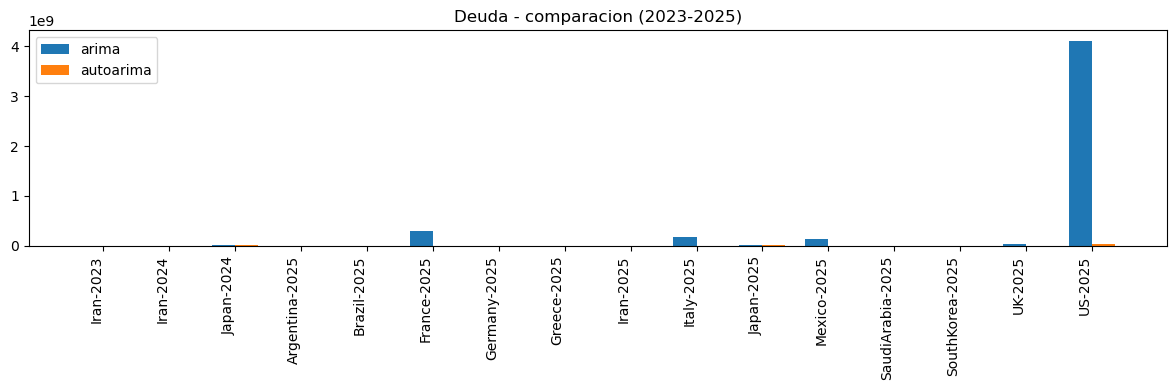

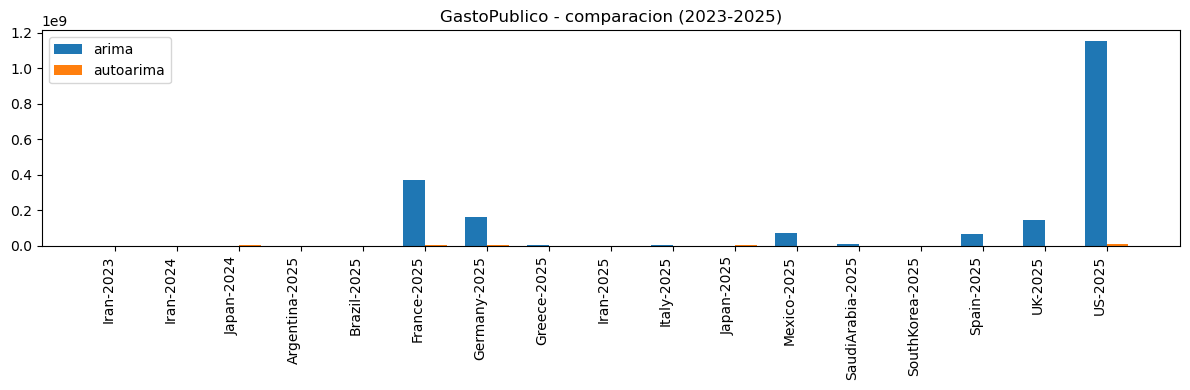

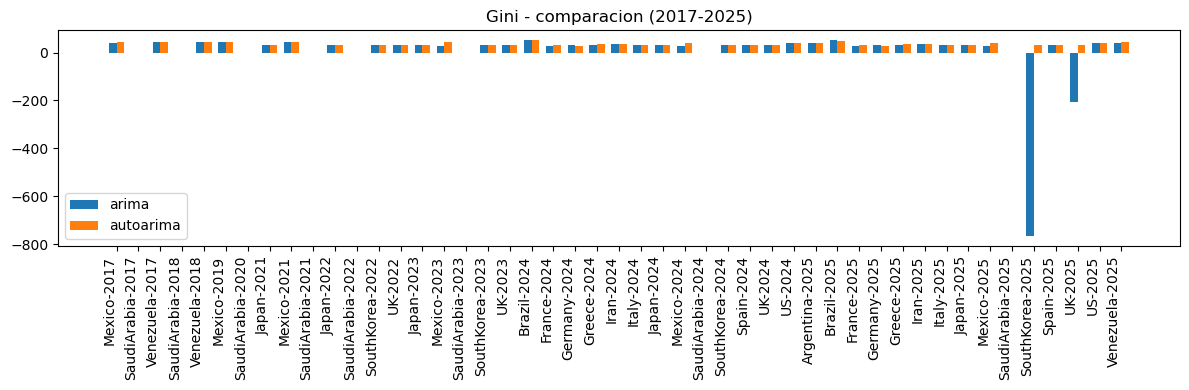

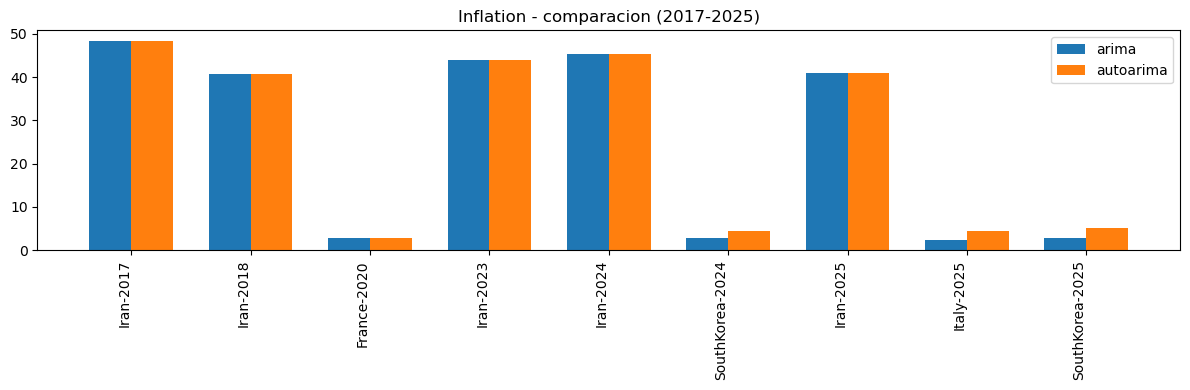

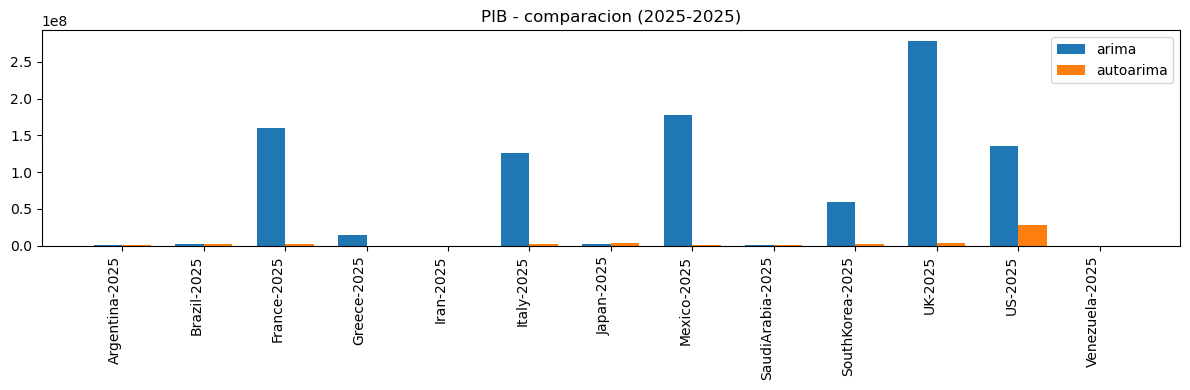

In [14]:
# Graficas: compara valores imputados para todos los anios modelados
for col, comp in comparisons.items():
    if comp.empty:
        continue
    comp_plot = comp.sort_values(["Year", "Country"]).copy()
    comp_plot["Year"] = comp_plot["Year"].astype(str)
    x = np.arange(len(comp_plot))
    width = 0.35
    plt.figure(figsize=(12, 4))
    plt.bar(x - width / 2, comp_plot["arima"], width, label="arima")
    plt.bar(x + width / 2, comp_plot["autoarima"], width, label="autoarima")
    plt.xticks(x, comp_plot["Country"] + "-" + comp_plot["Year"], rotation=90, ha="right")
    year_min = comp_plot["Year"].min()
    year_max = comp_plot["Year"].max()
    plt.title(f"{col} - comparacion ({year_min}-{year_max})")
    plt.tight_layout()
    plt.legend()
    plt.show()

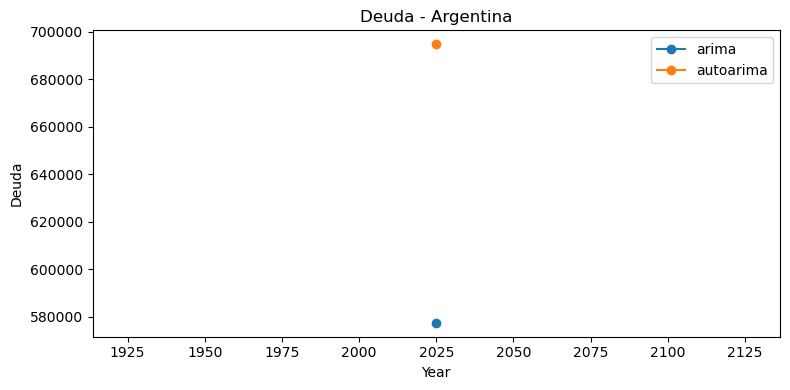

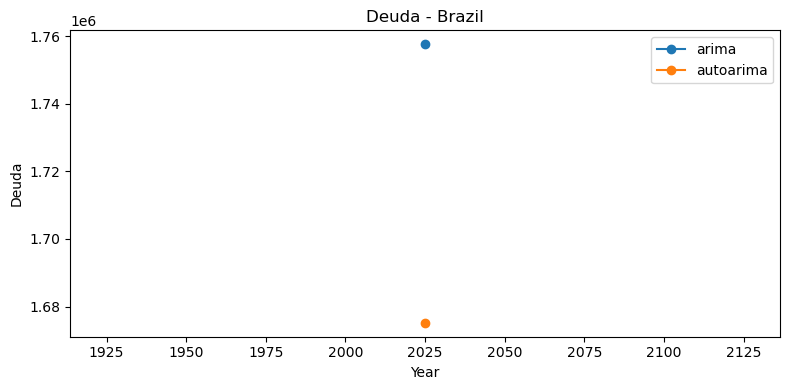

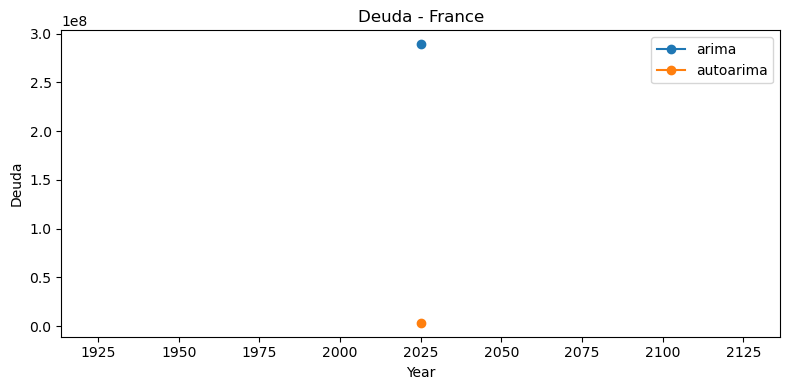

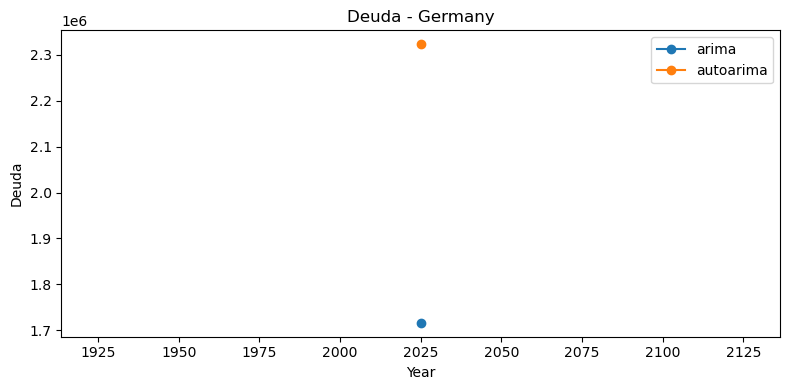

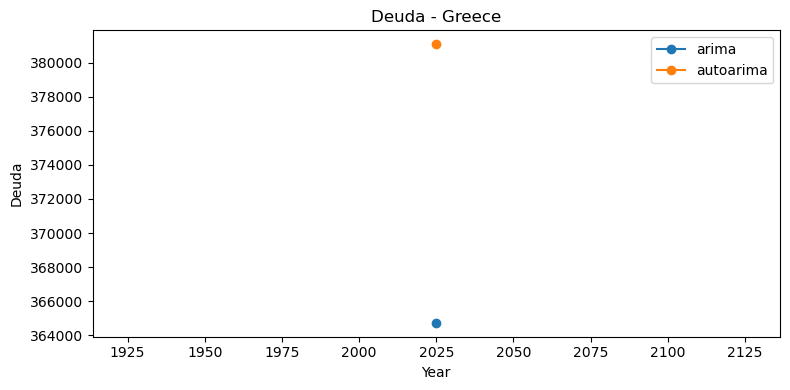

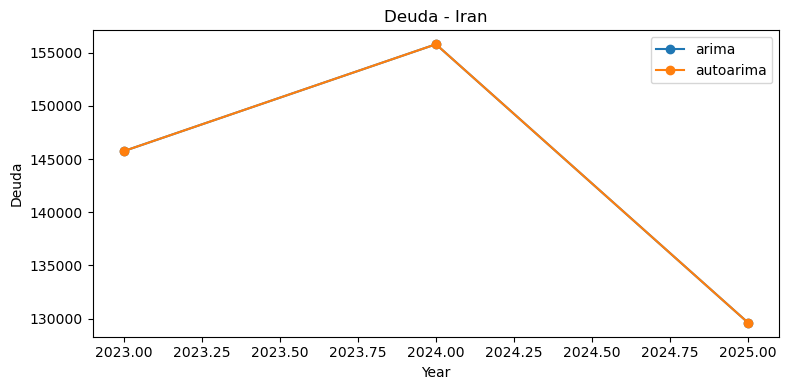

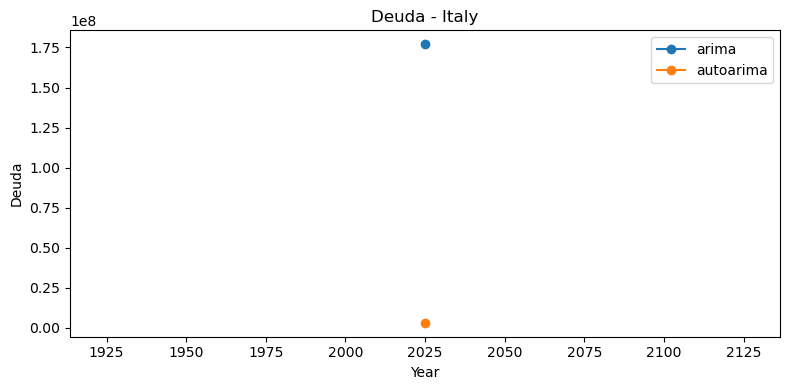

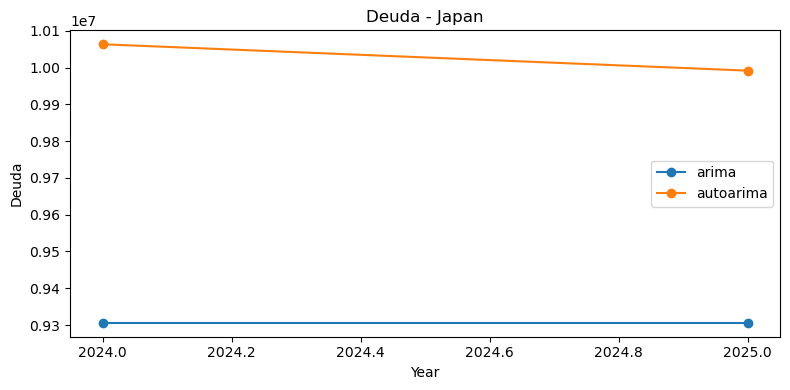

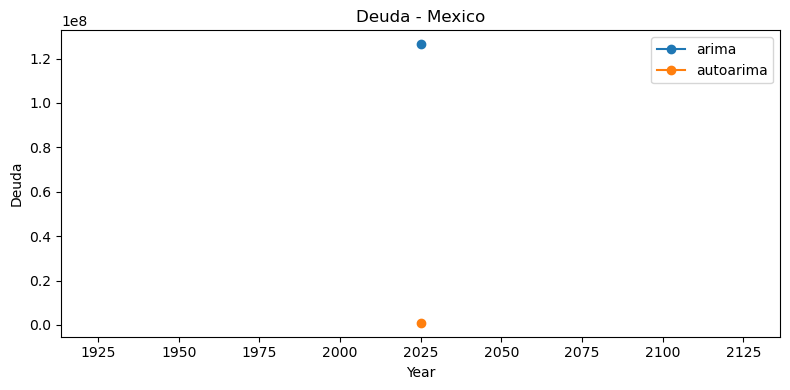

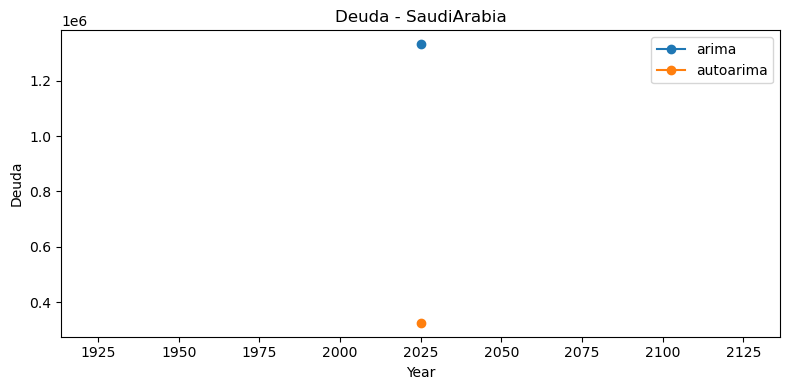

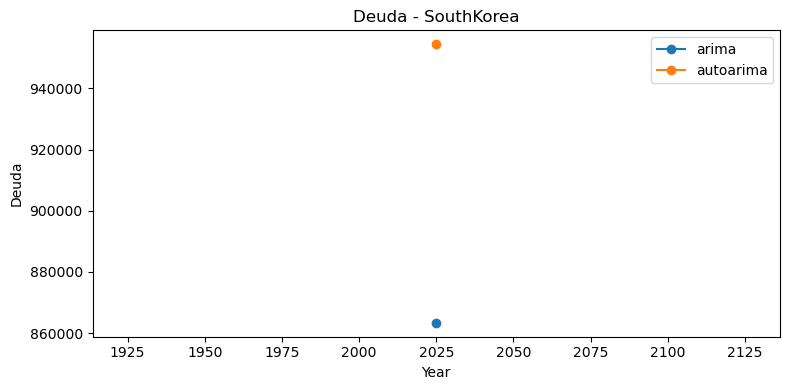

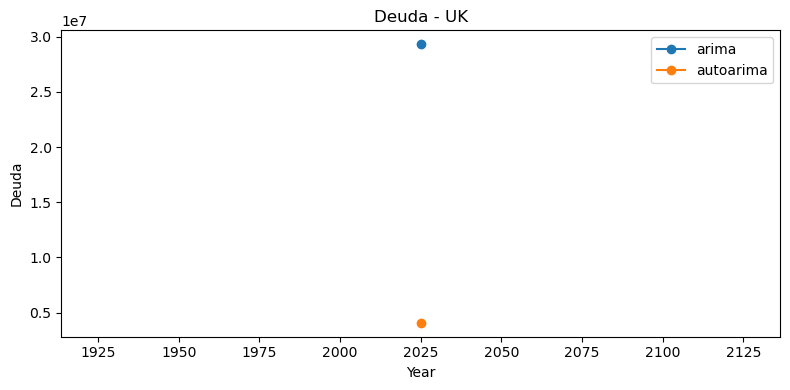

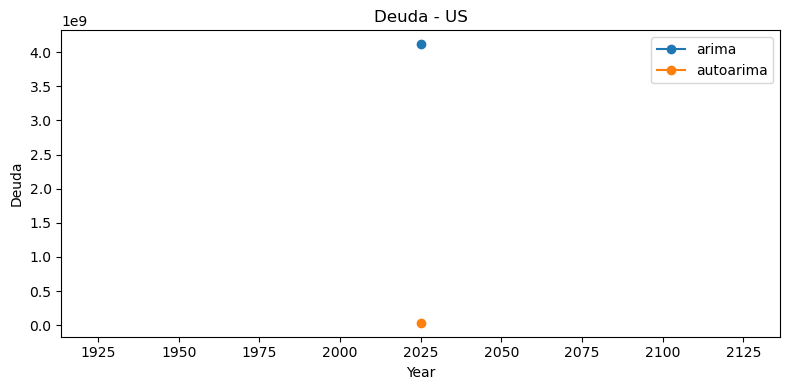

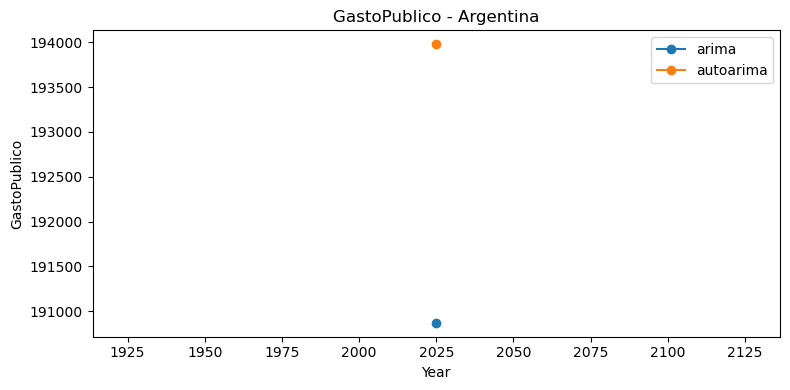

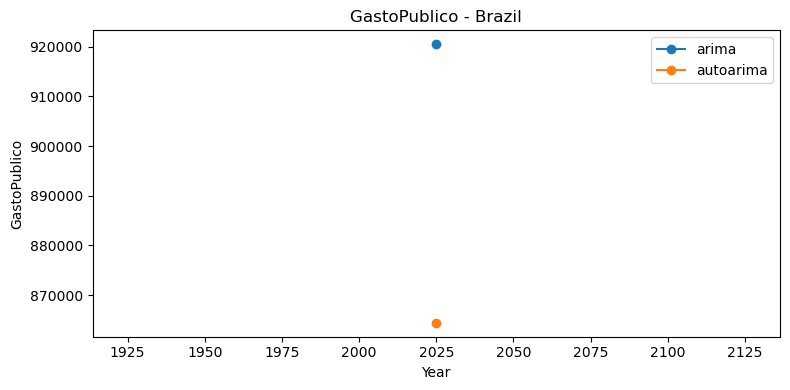

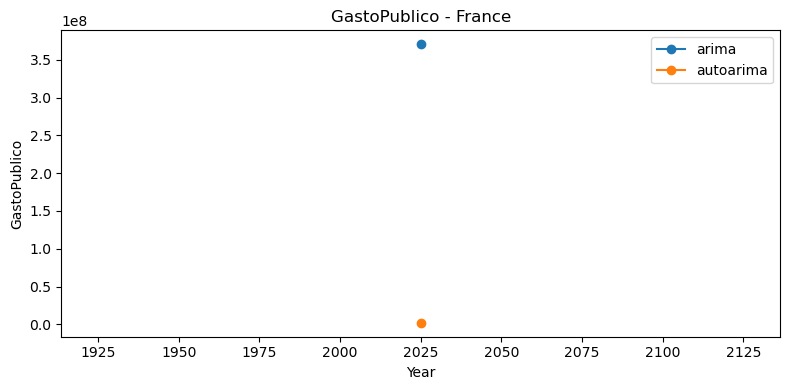

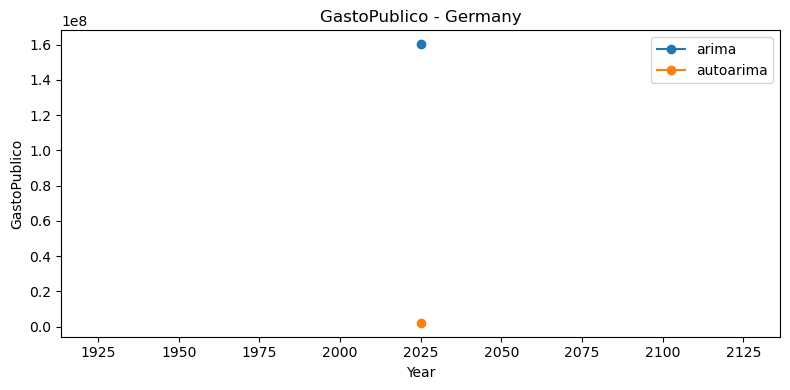

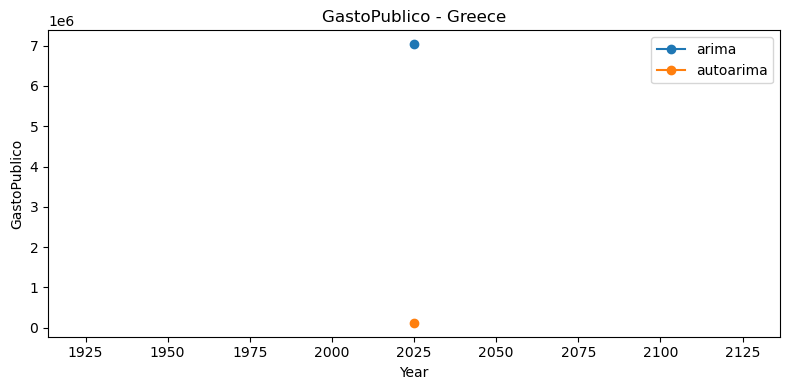

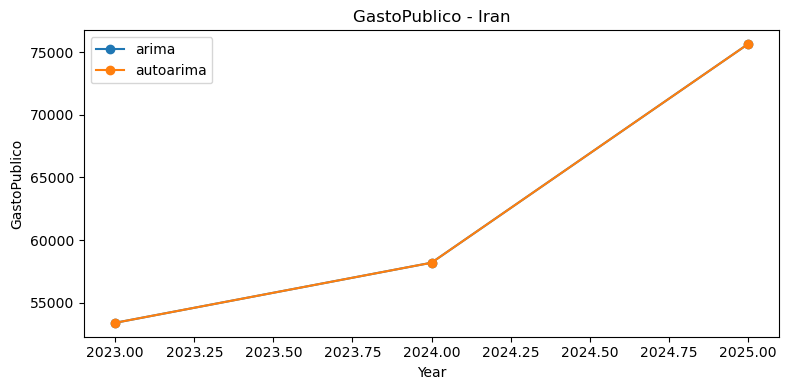

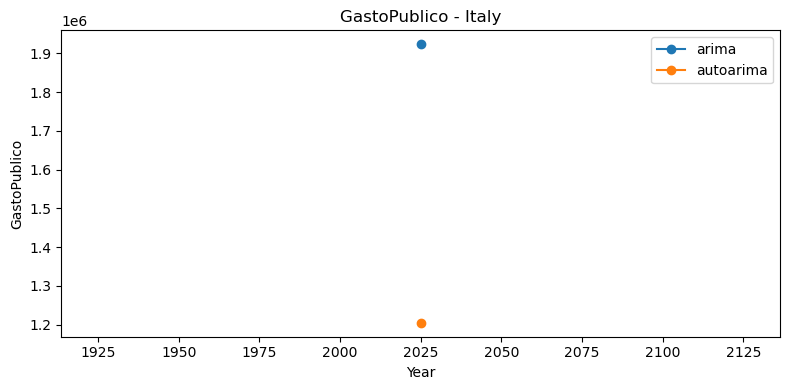

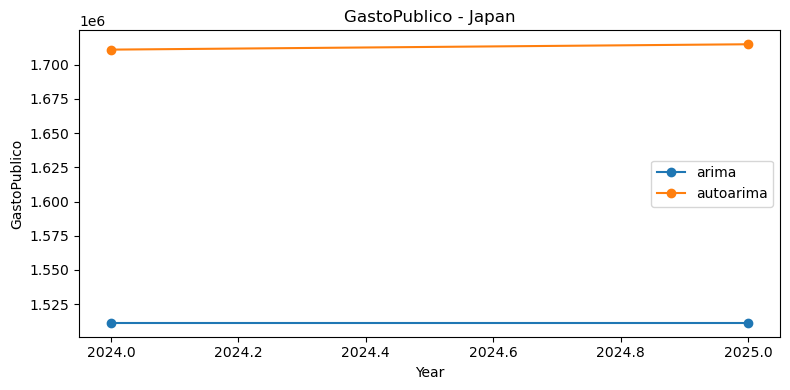

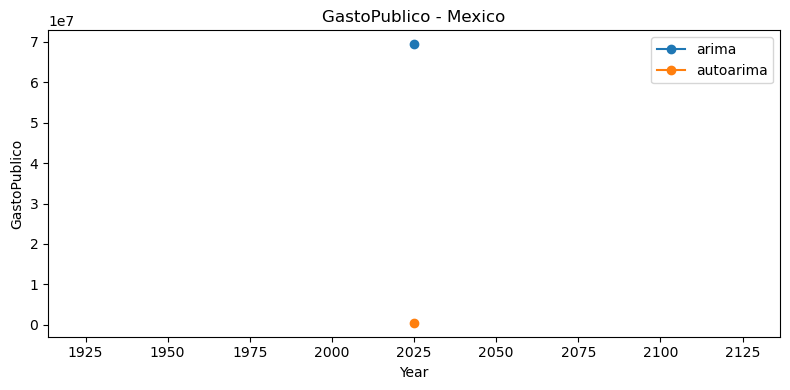

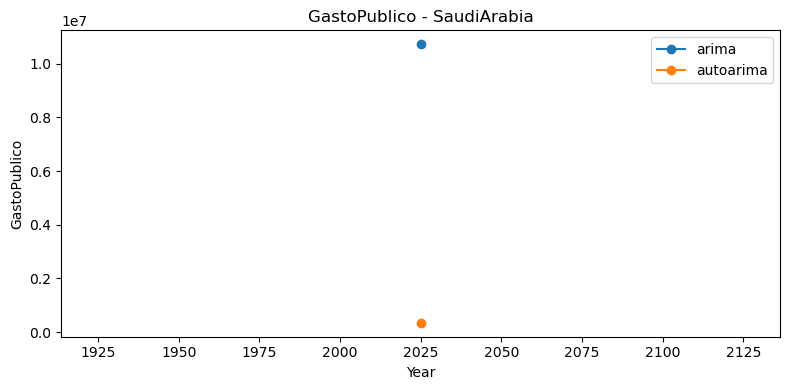

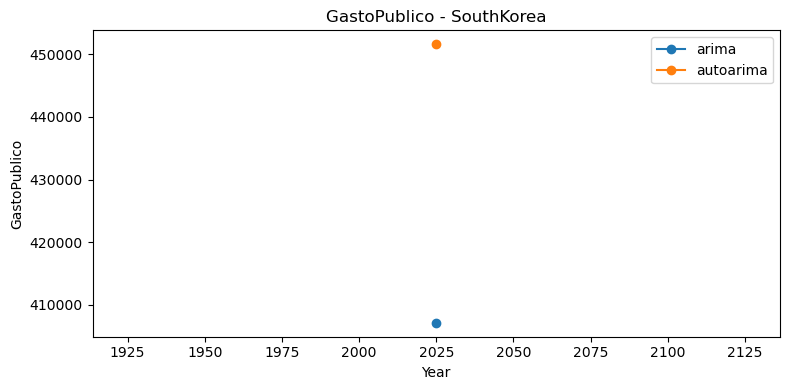

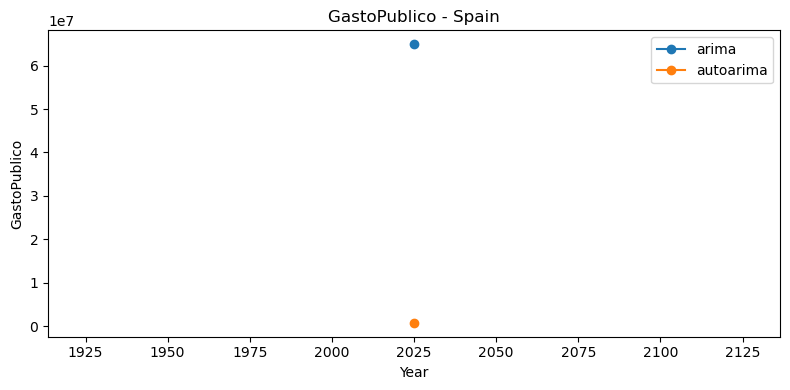

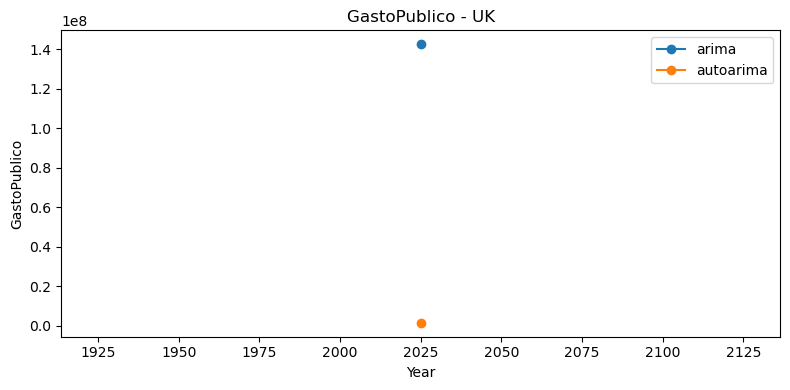

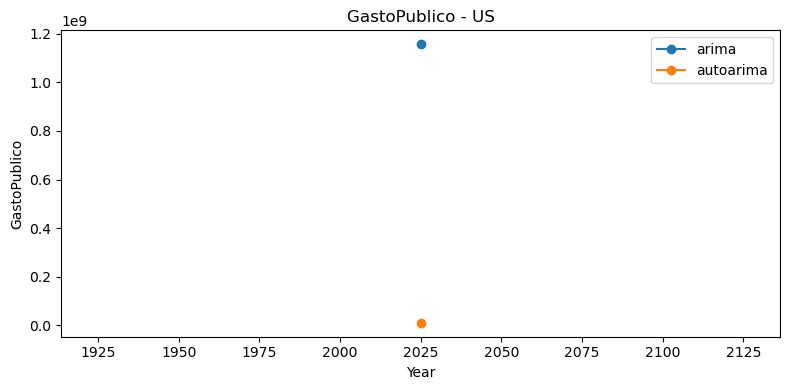

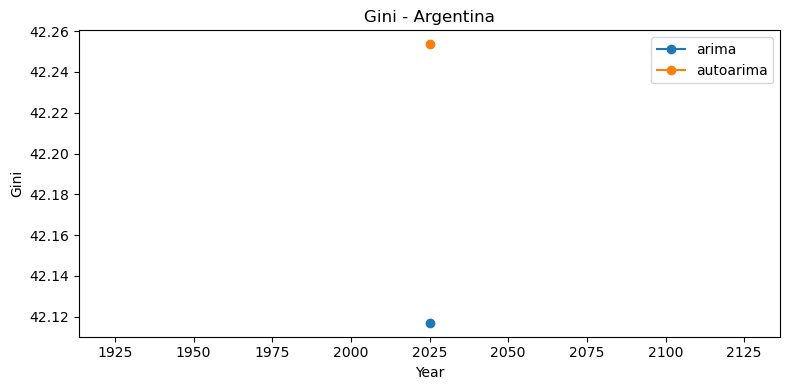

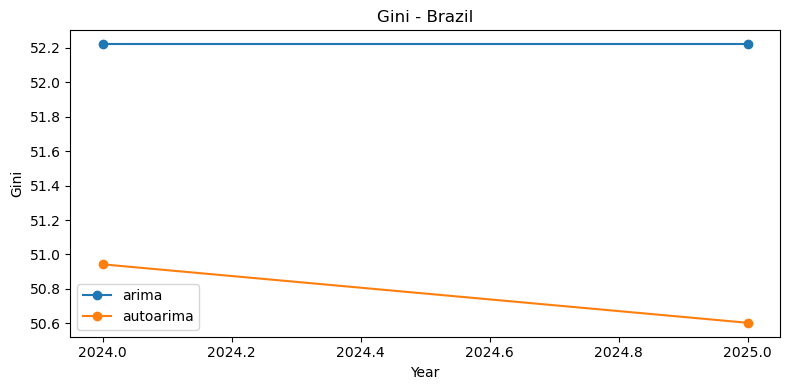

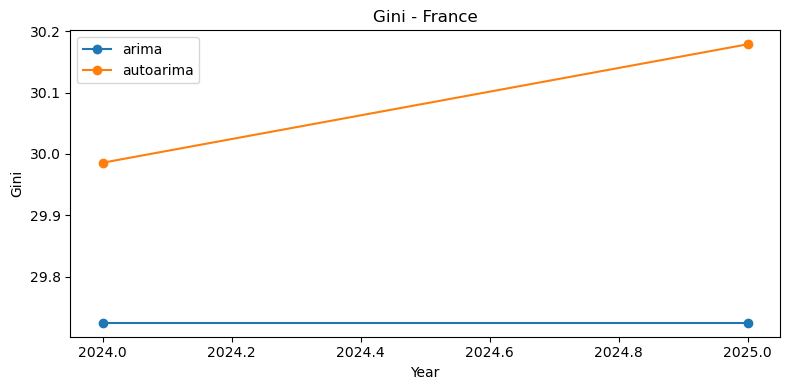

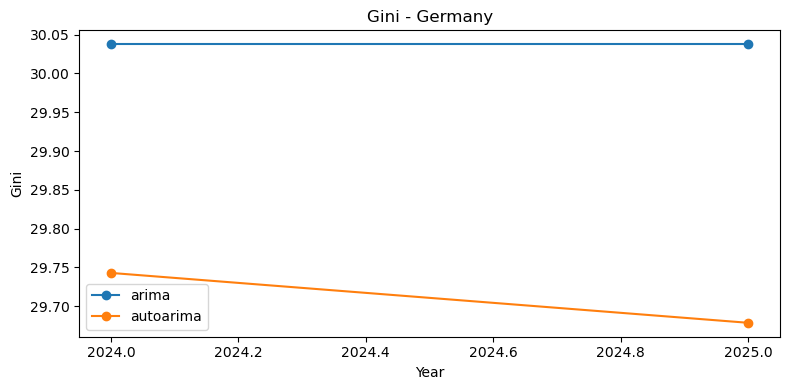

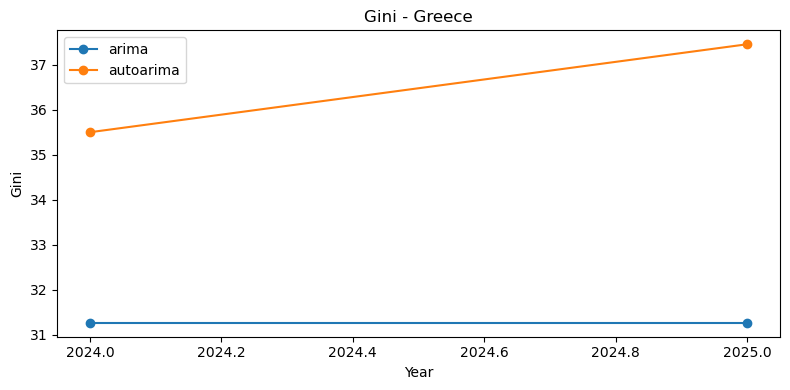

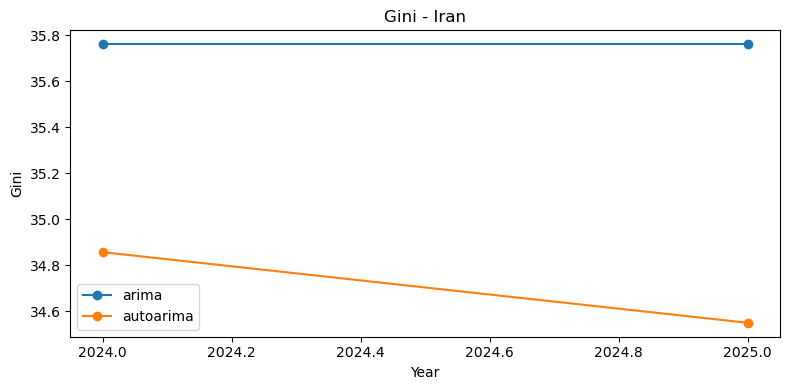

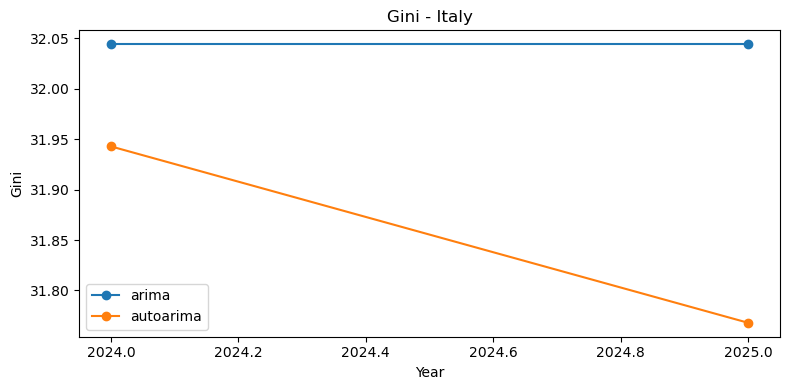

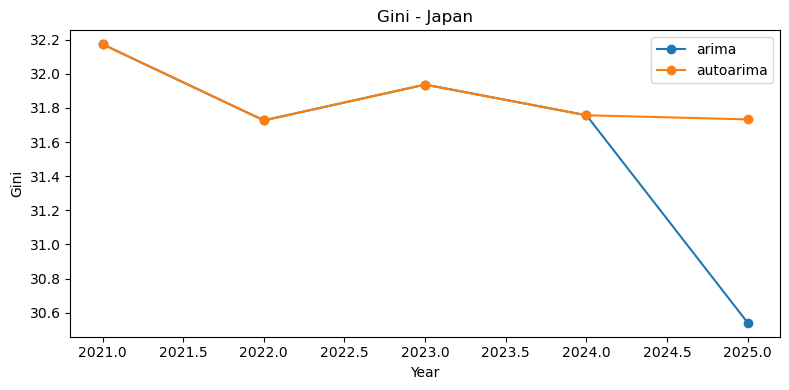

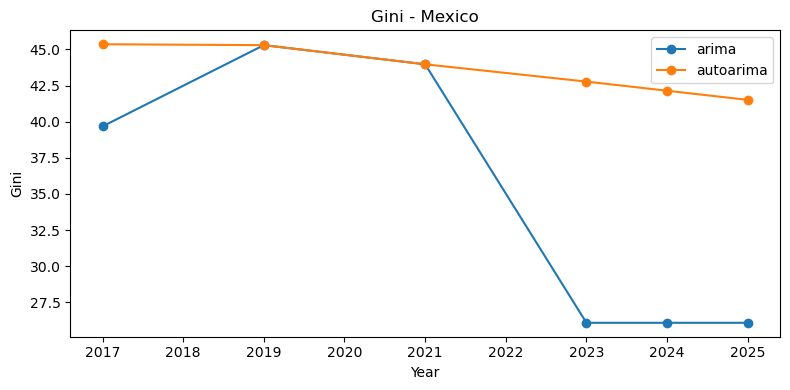

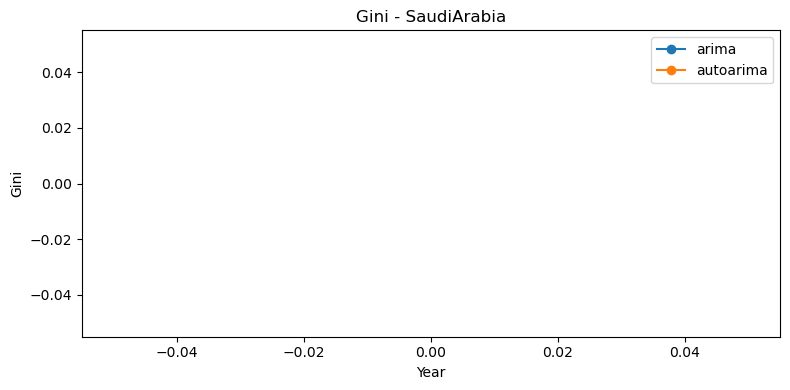

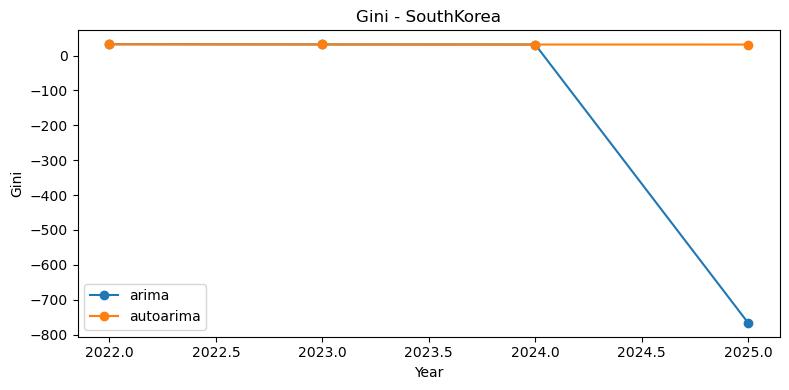

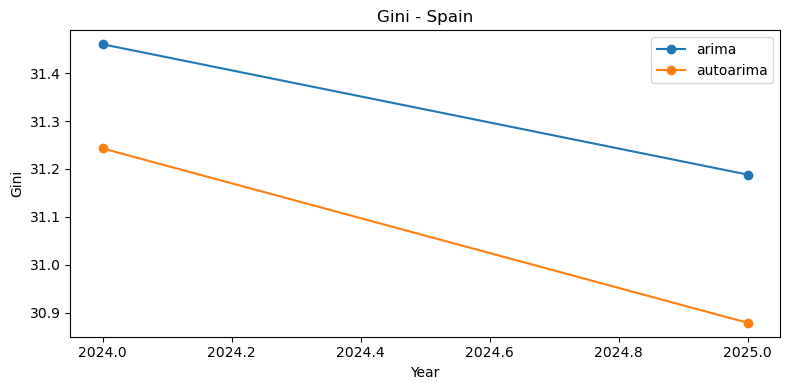

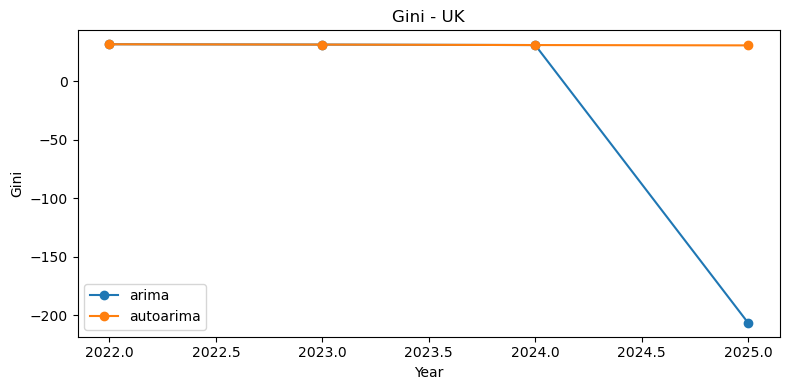

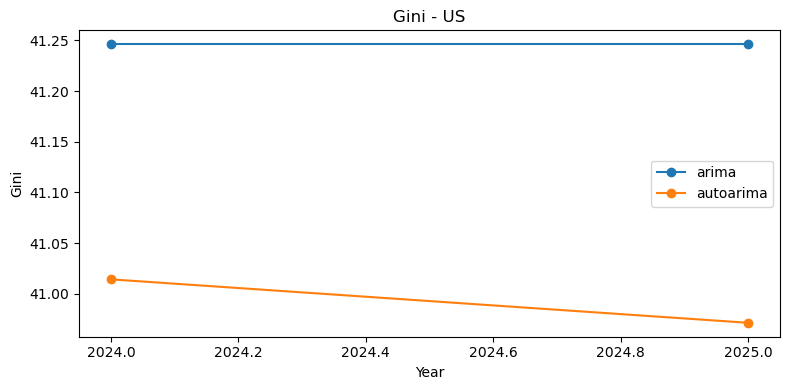

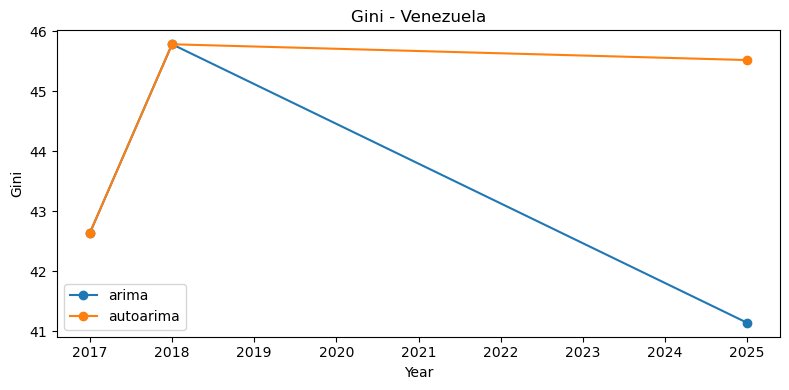

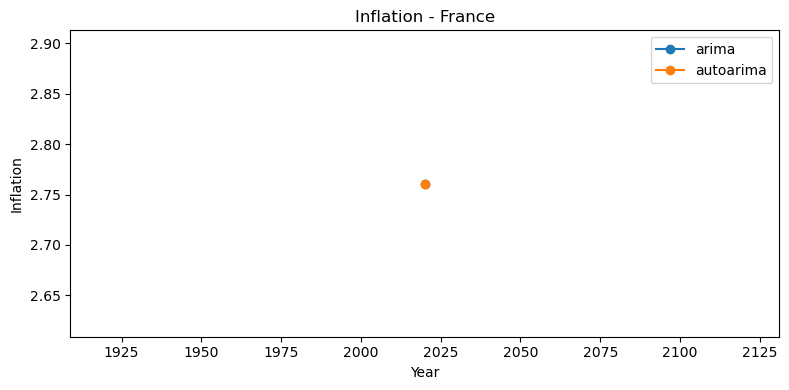

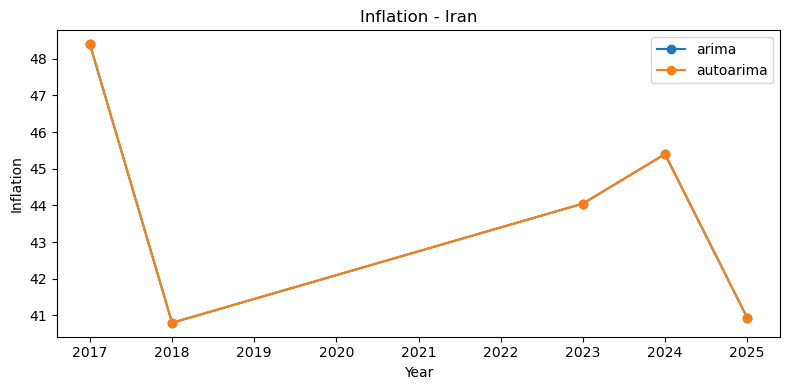

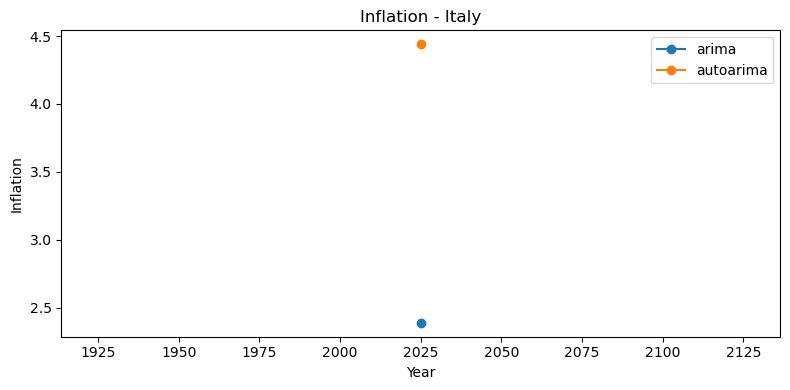

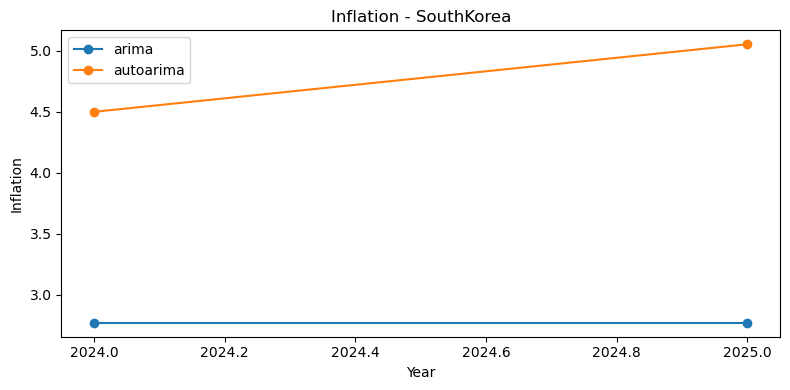

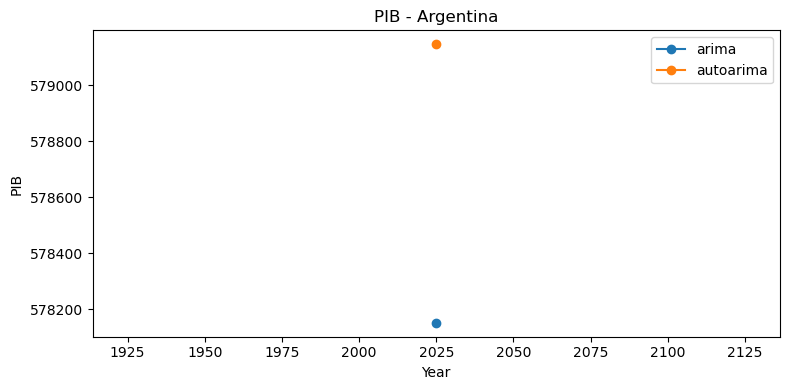

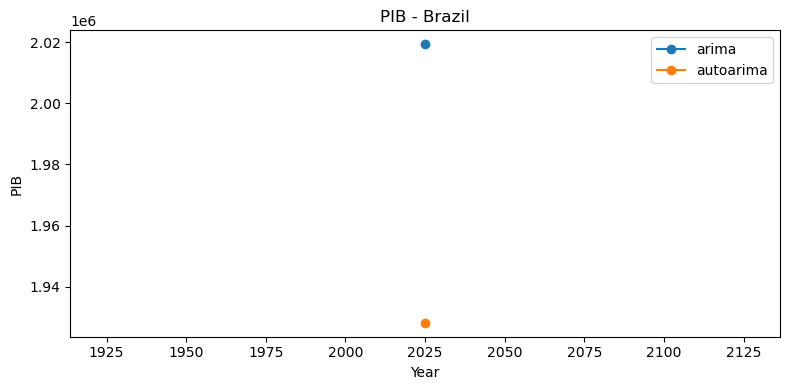

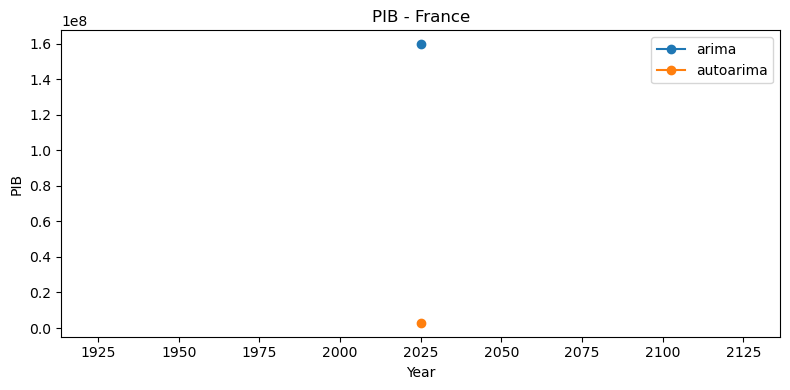

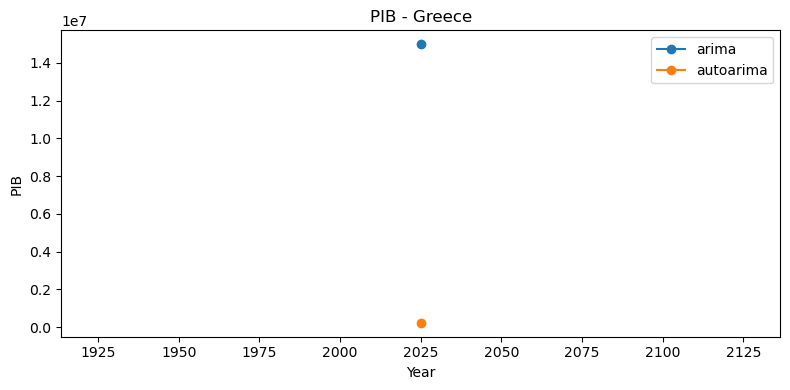

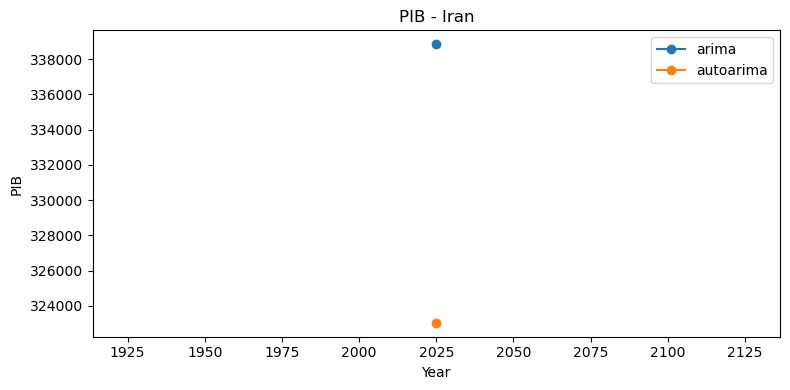

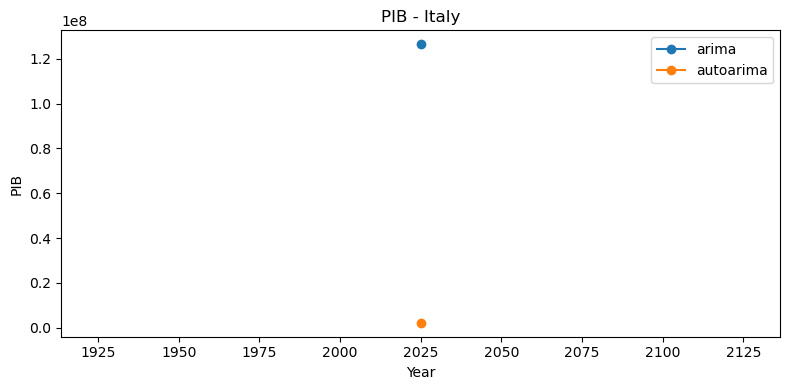

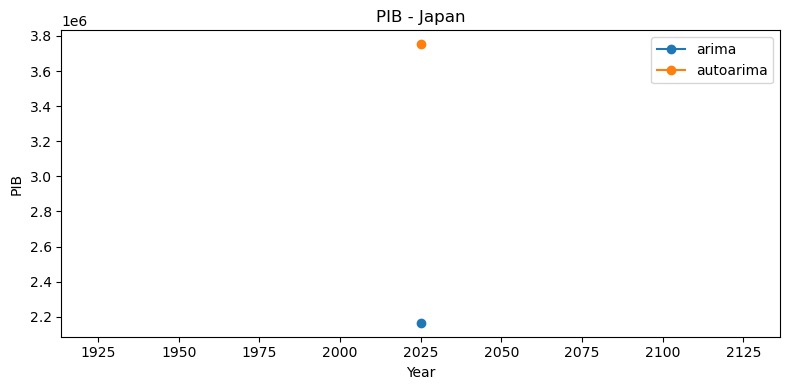

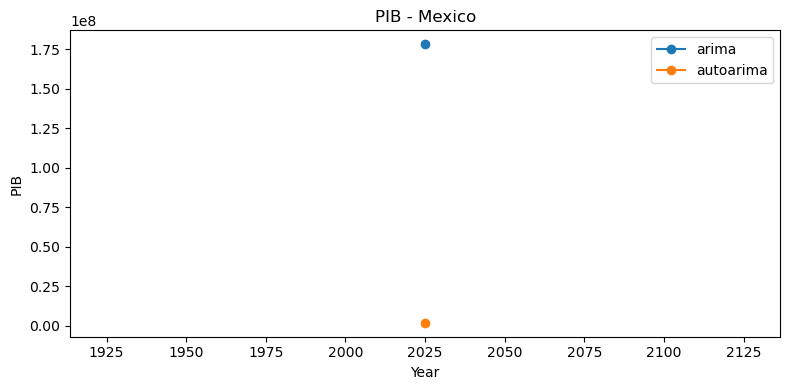

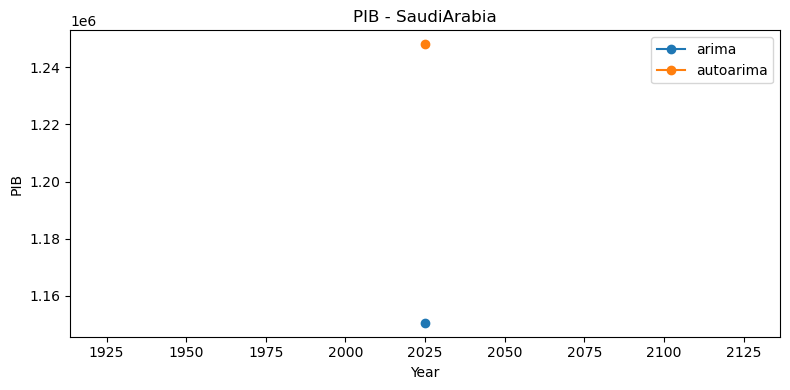

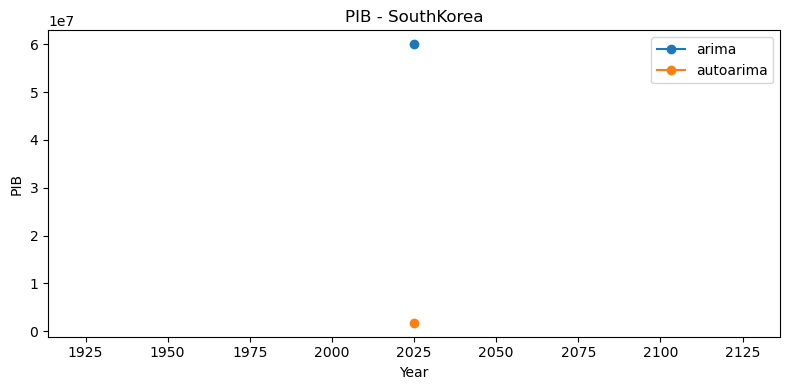

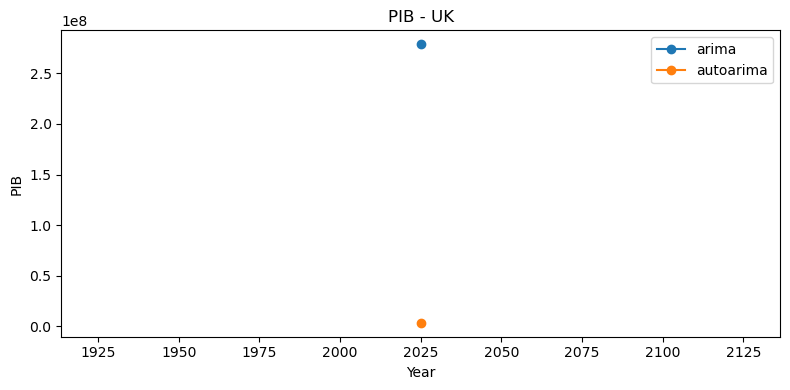

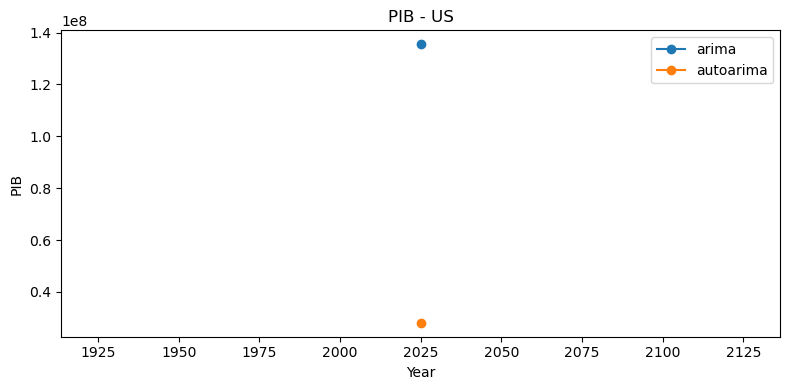

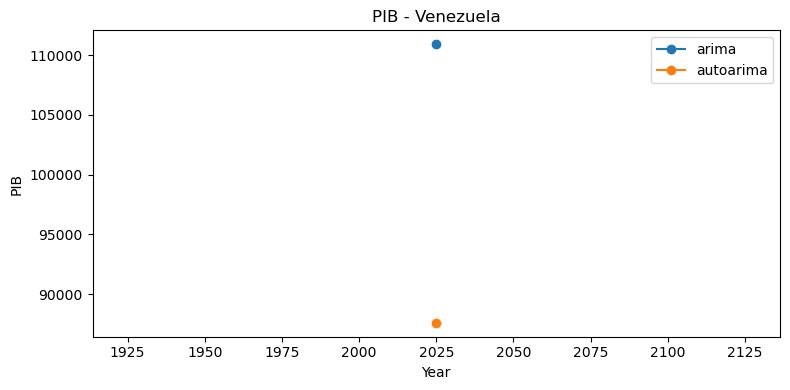

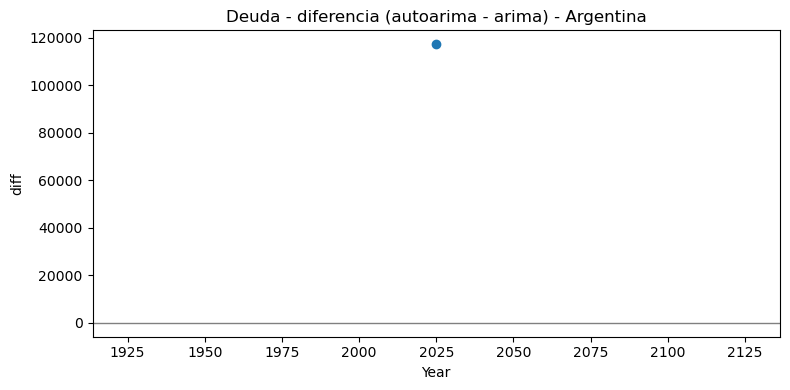

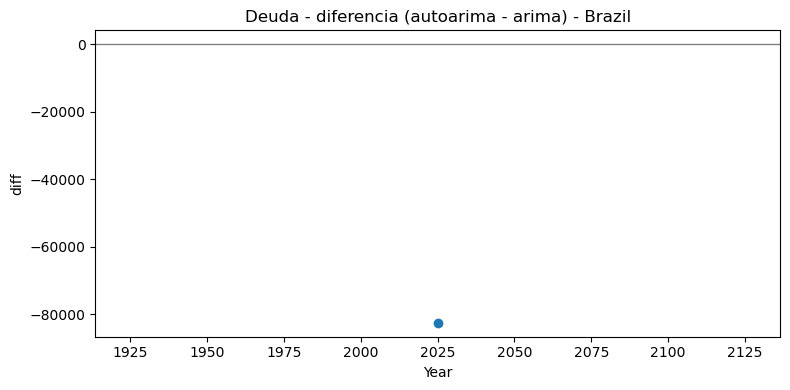

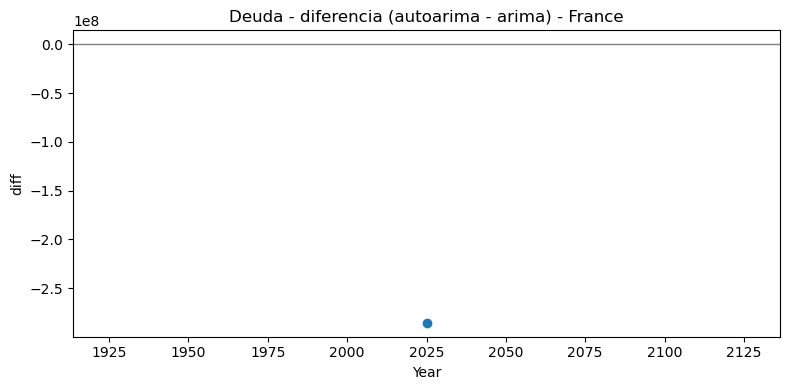

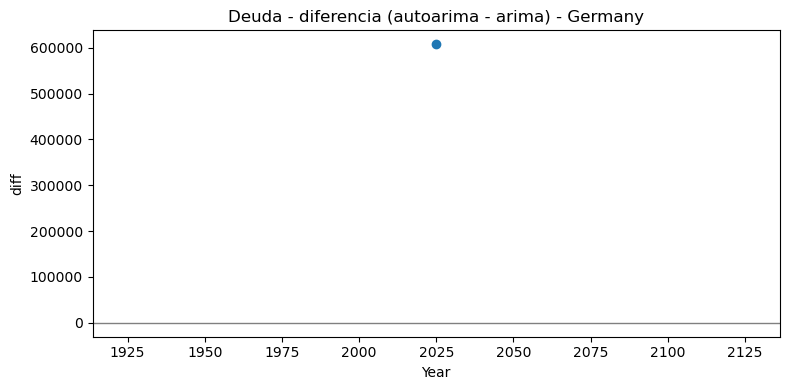

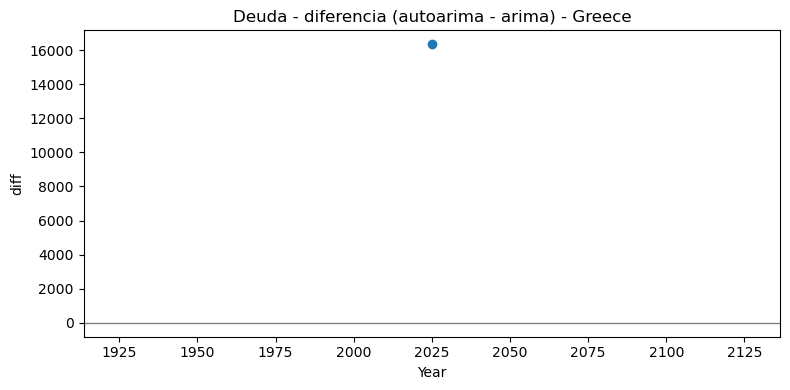

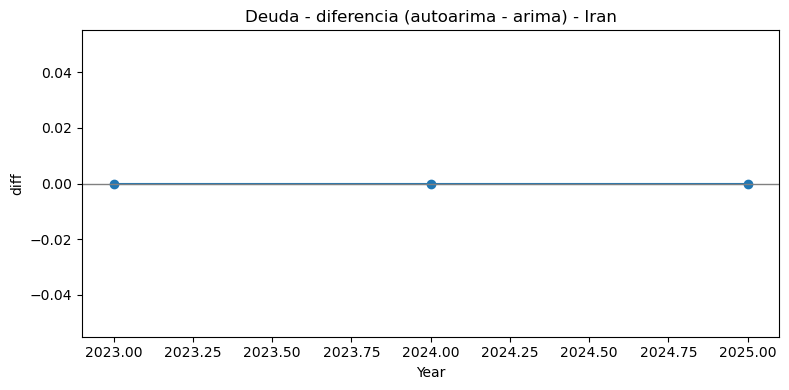

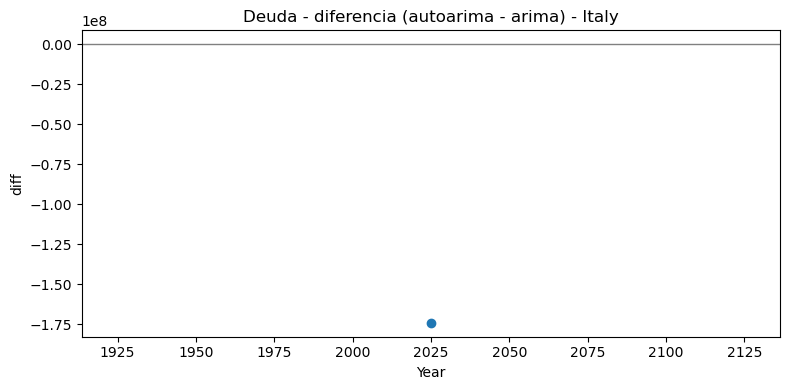

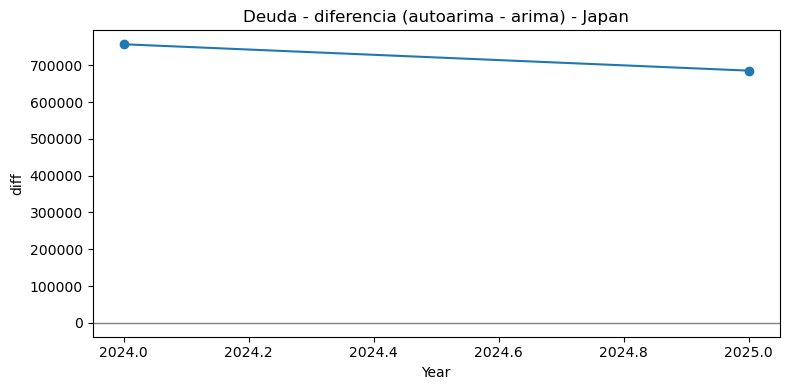

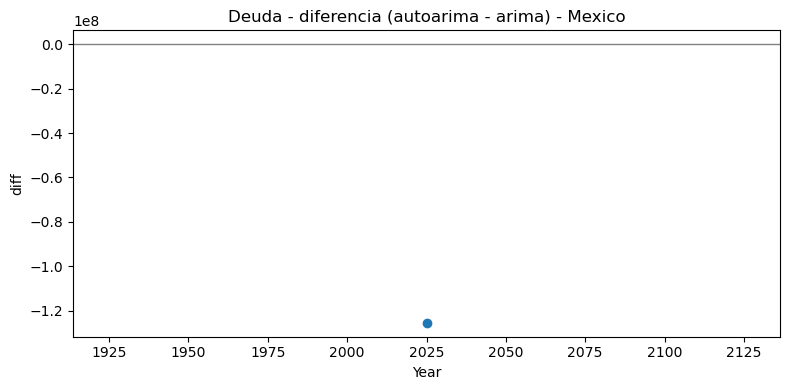

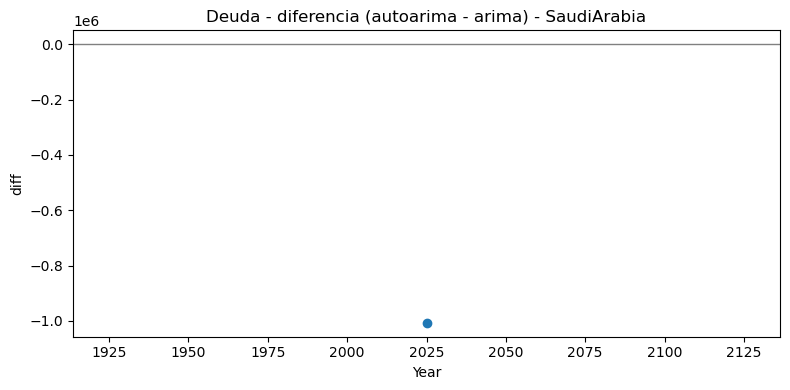

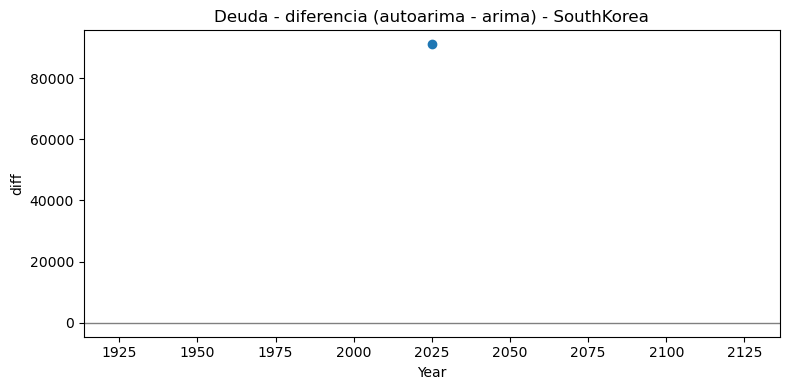

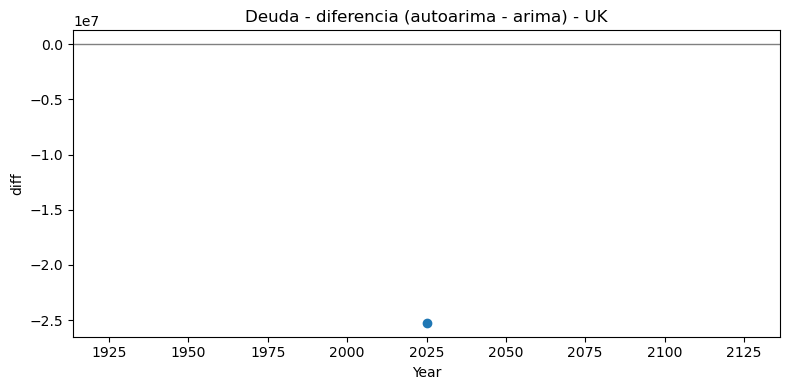

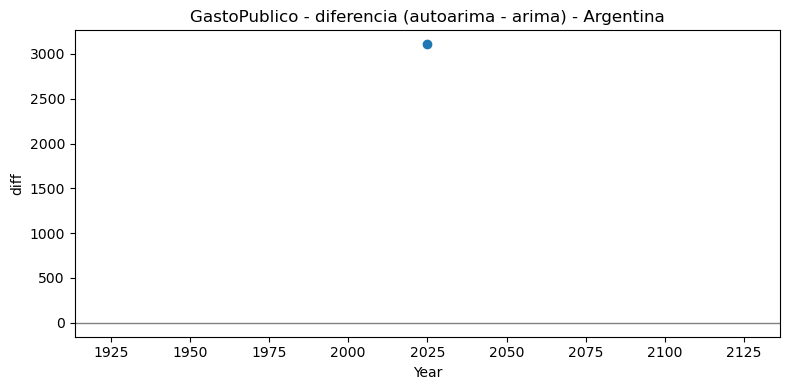

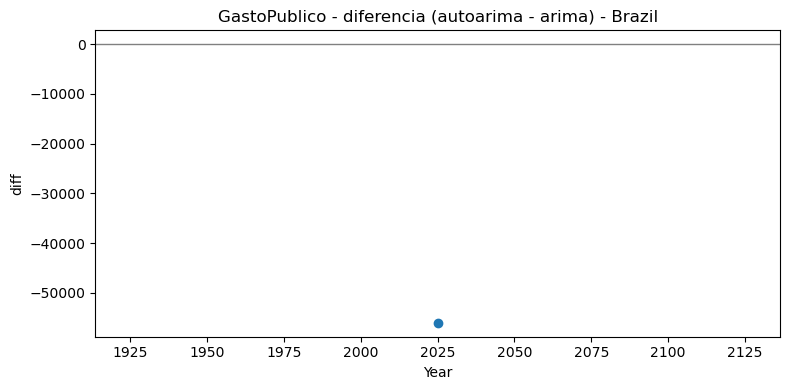

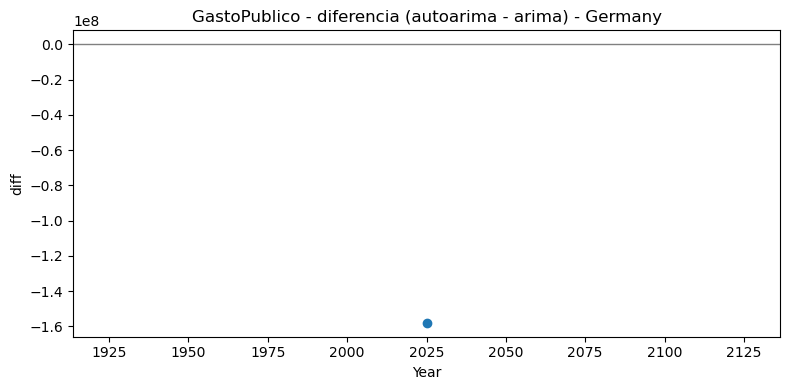

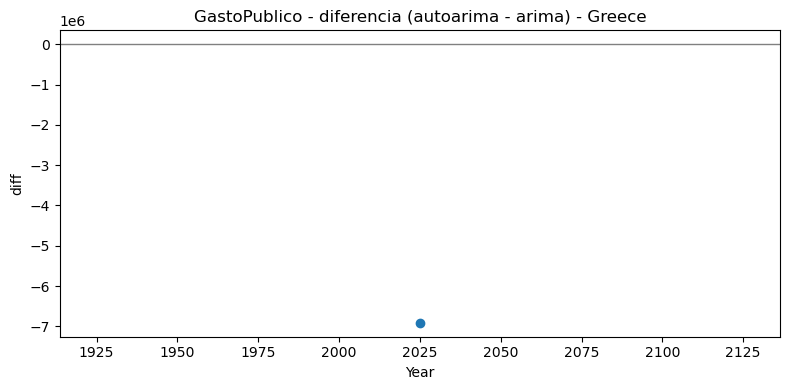

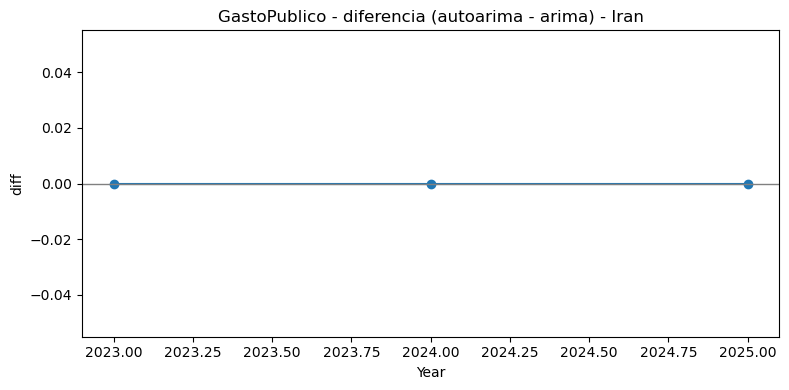

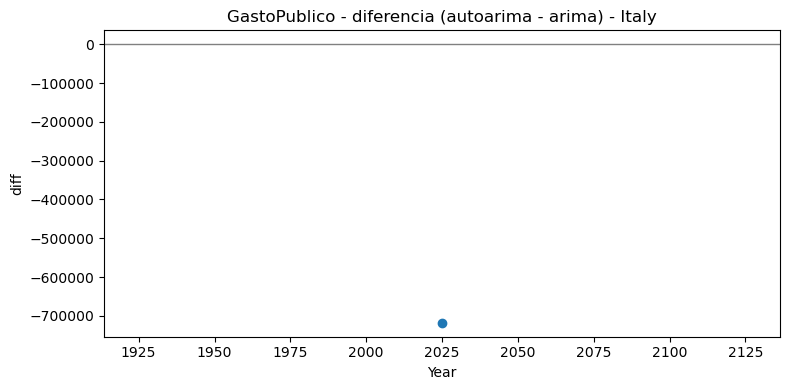

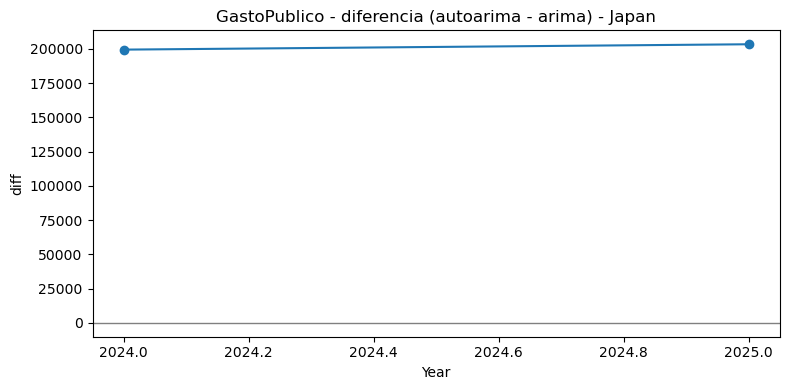

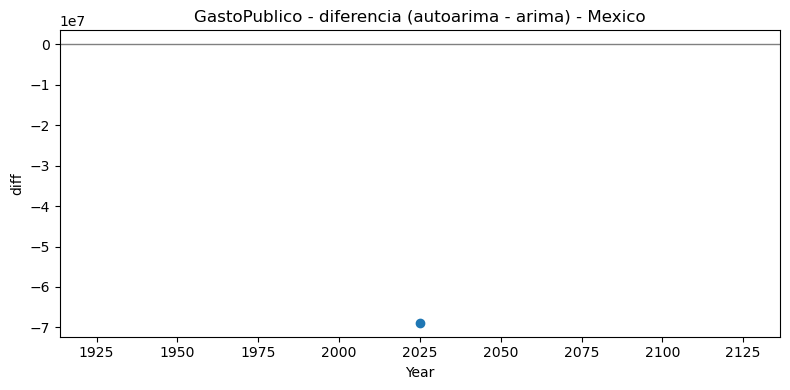

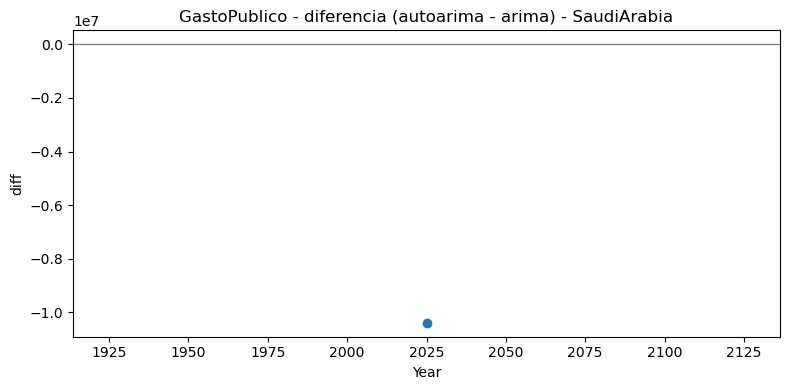

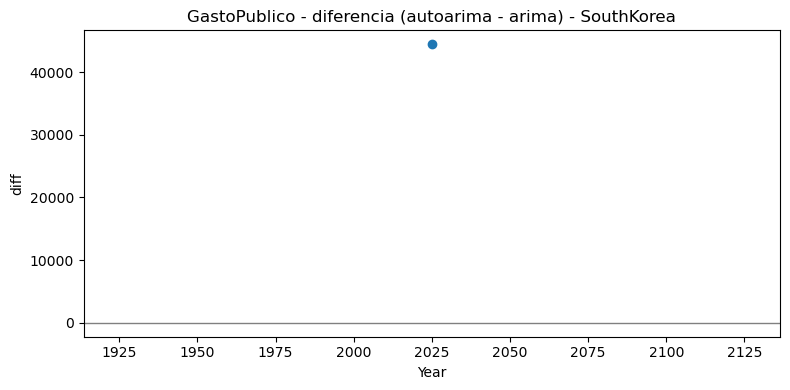

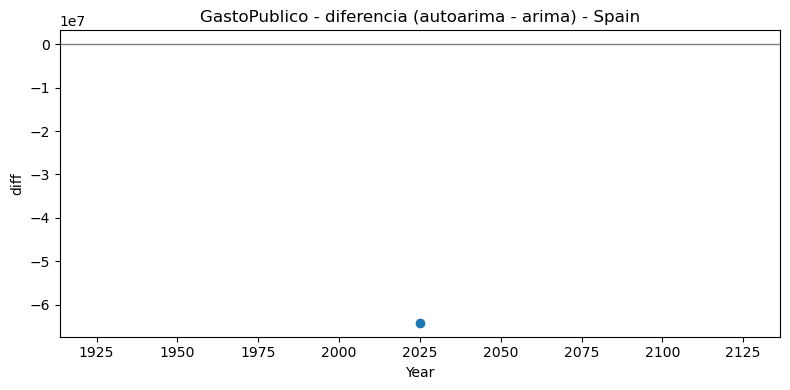

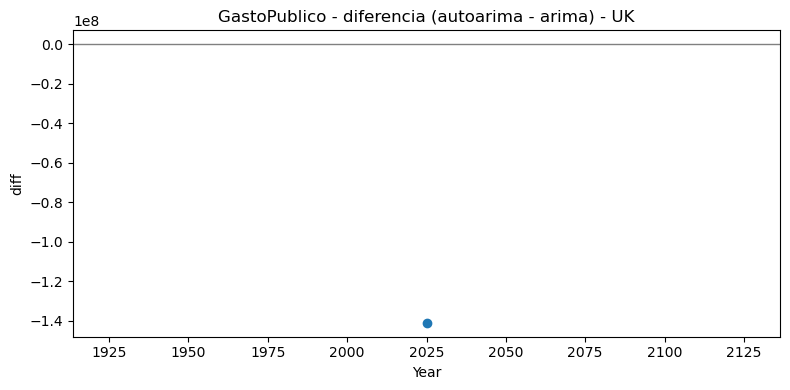

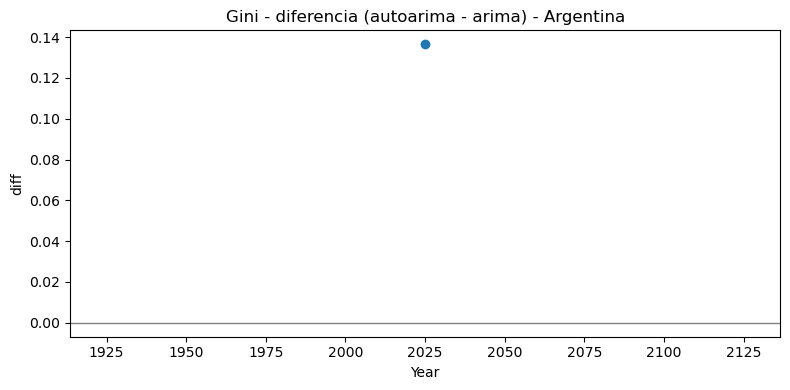

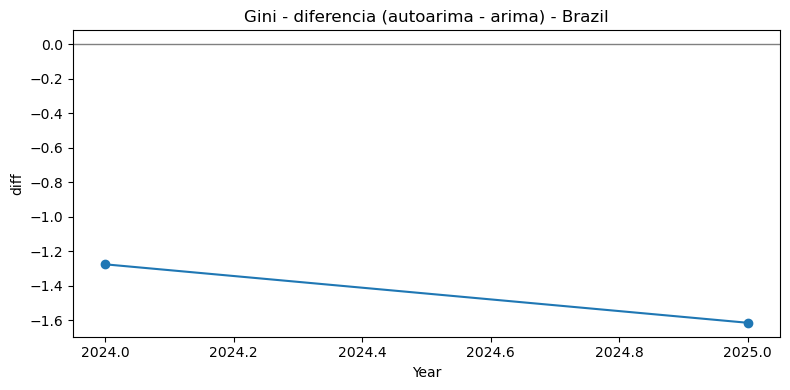

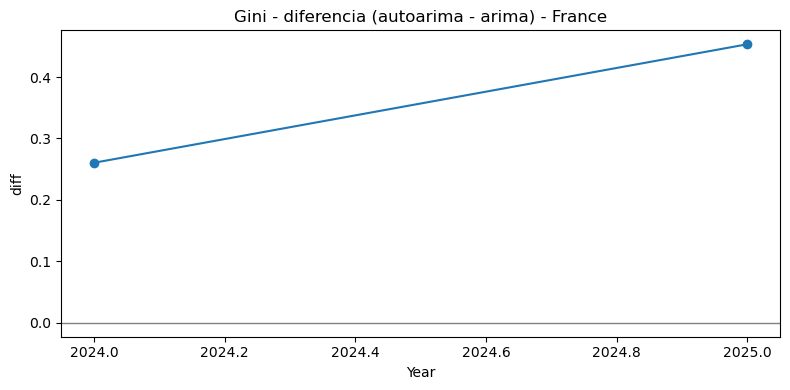

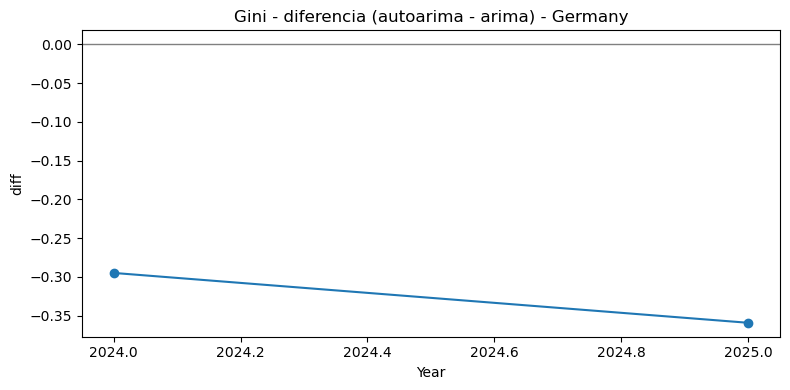

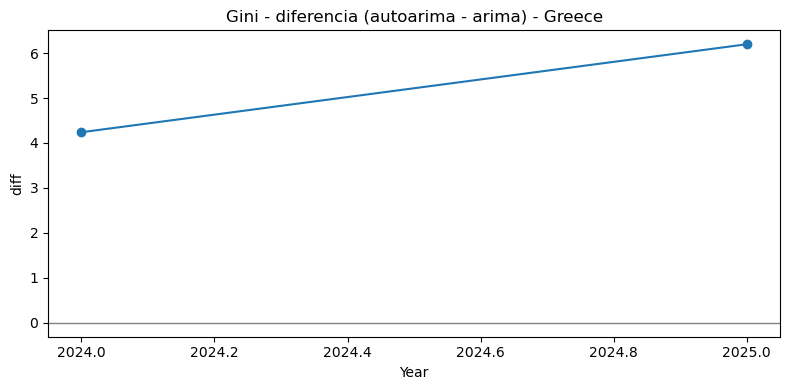

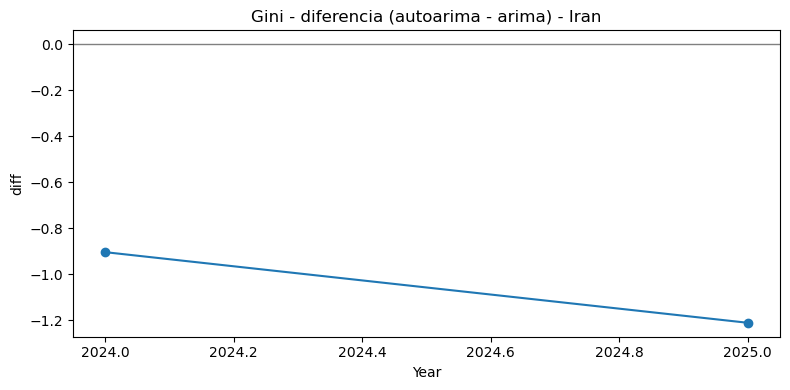

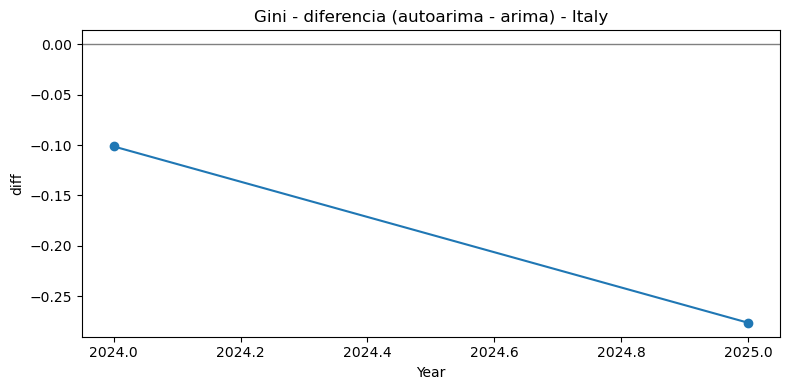

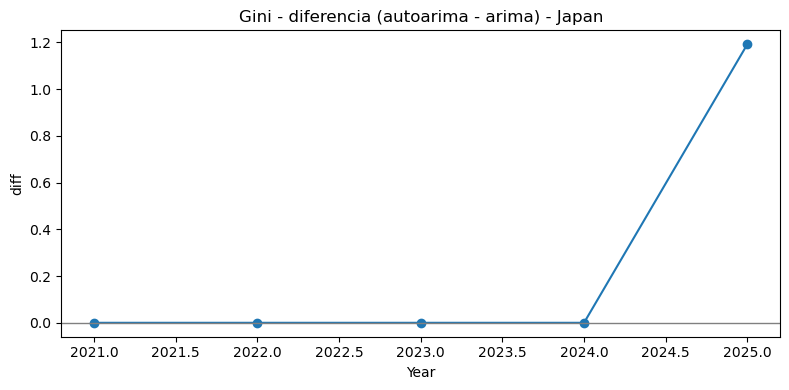

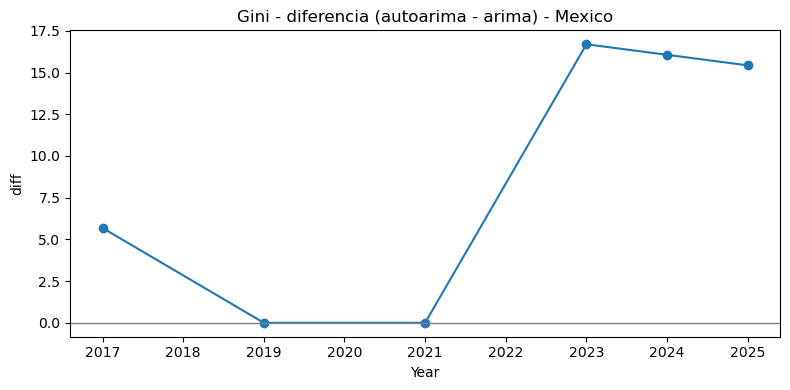

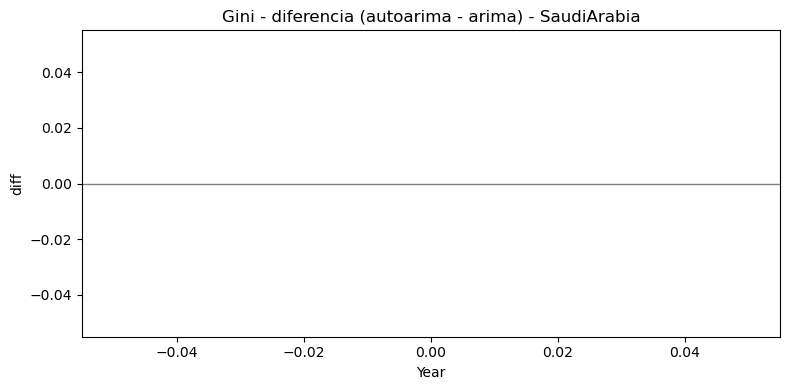

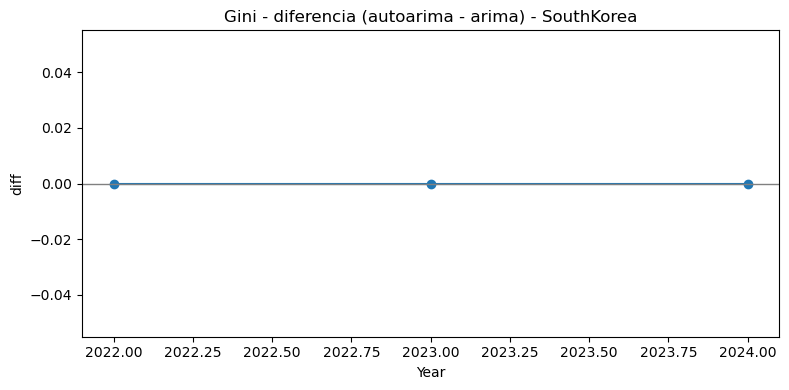

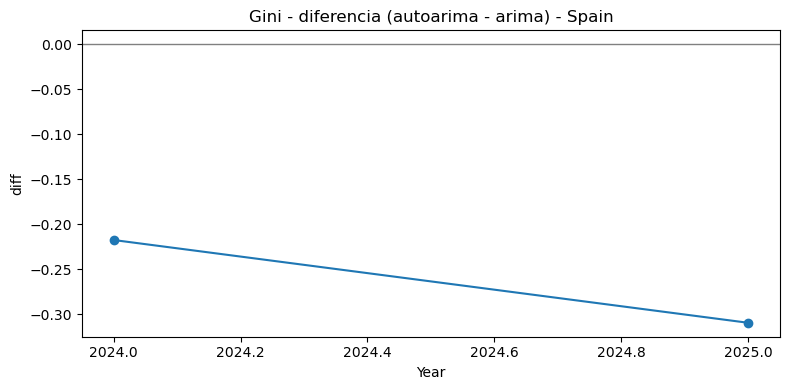

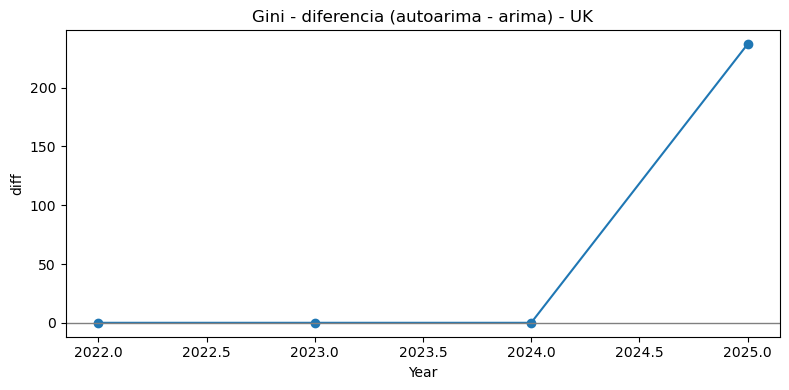

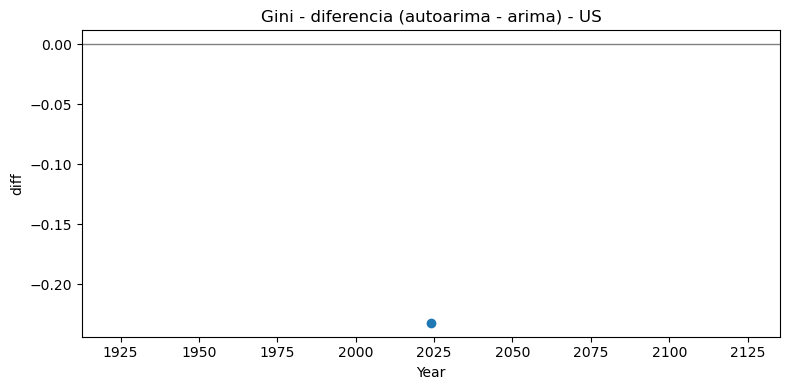

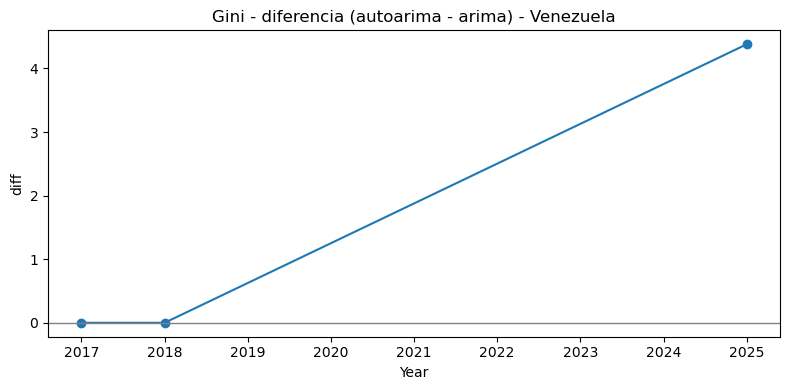

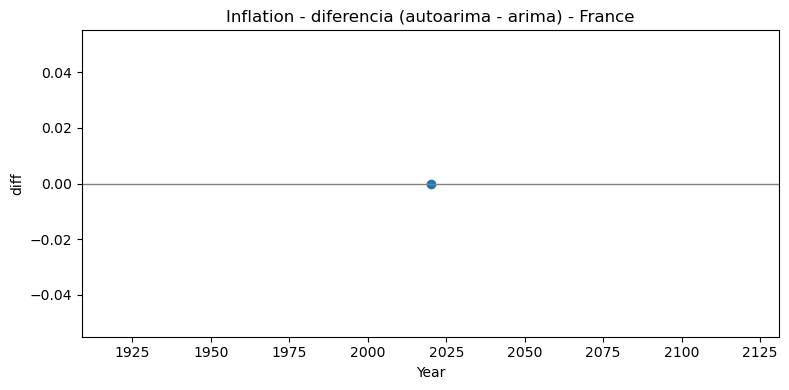

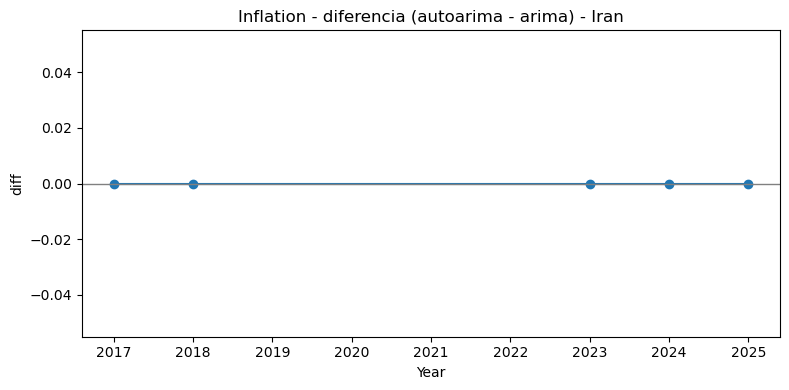

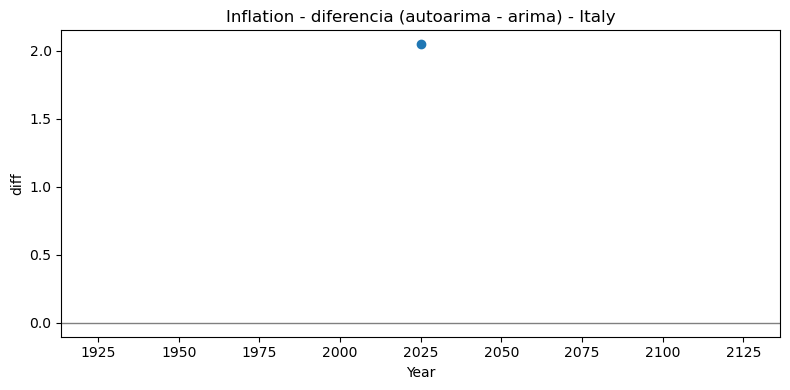

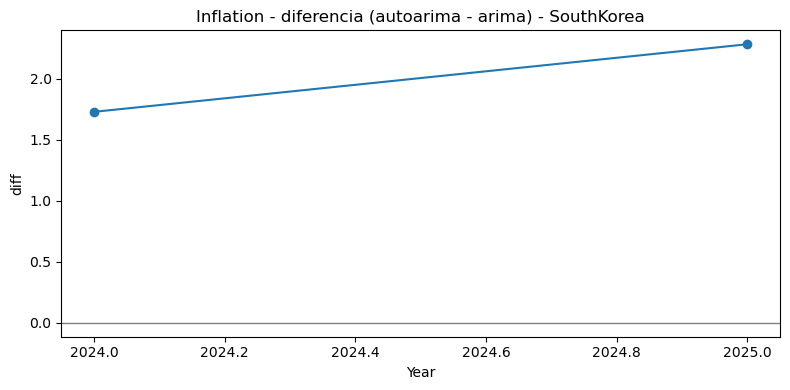

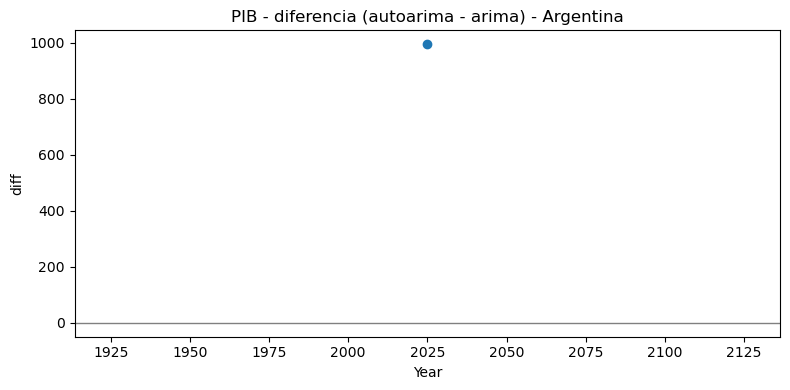

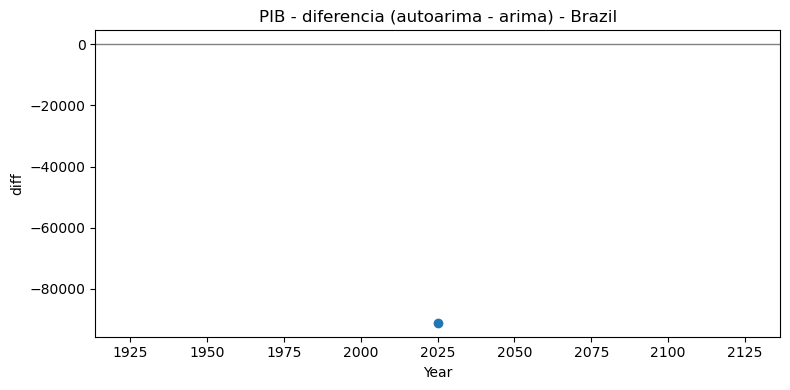

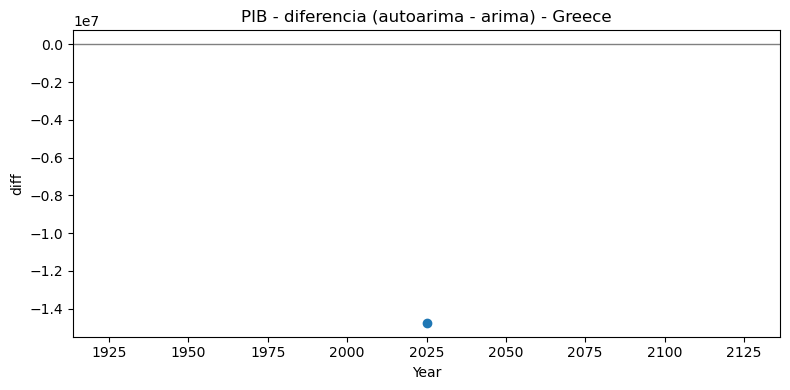

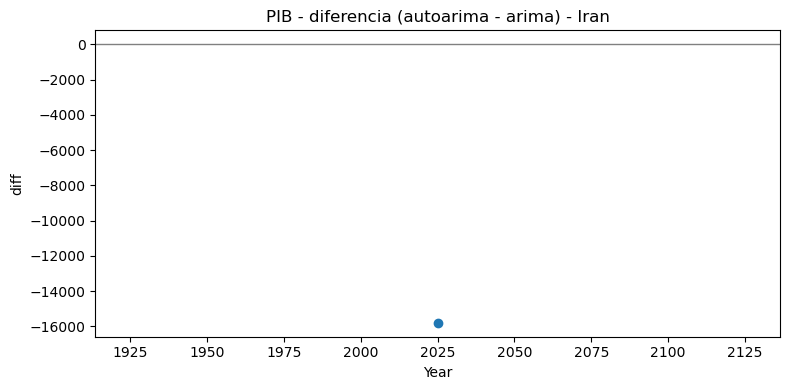

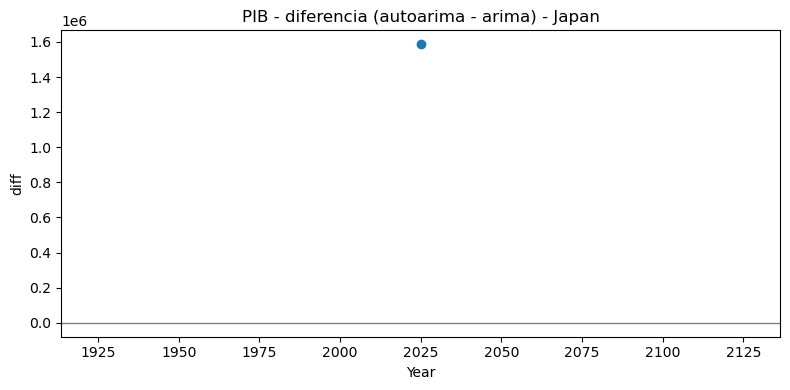

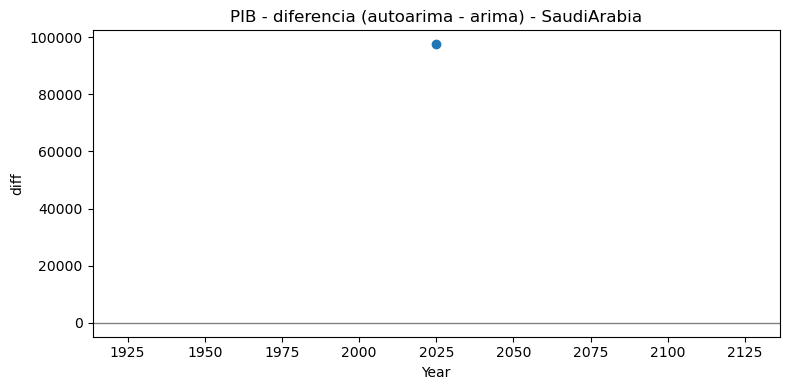

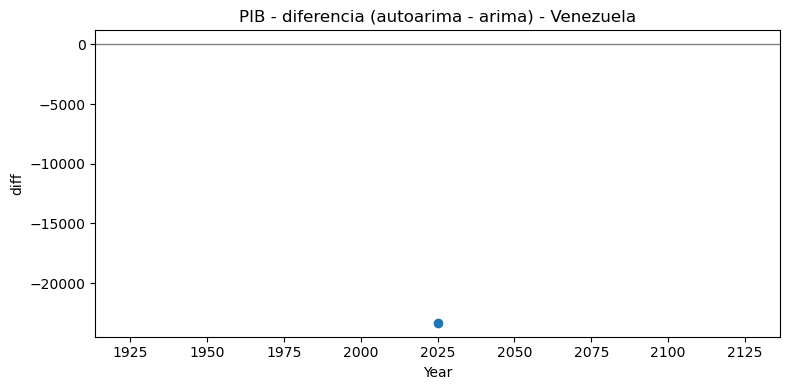

In [15]:
# Lineas por pais y anio: arima vs autoarima (una grafica por columna y pais)
for col, comp in comparisons.items():
    if comp.empty:
        continue
    for country, cdf in comp.groupby("Country"):
        cdf = cdf.sort_values("Year")
        plt.figure(figsize=(8, 4))
        plt.plot(cdf["Year"], cdf["arima"], marker="o", label="arima")
        plt.plot(cdf["Year"], cdf["autoarima"], marker="o", label="autoarima")
        plt.title(f"{col} - {country}")
        plt.xlabel("Year")
        plt.ylabel(col)
        plt.legend()
        plt.tight_layout()
        plt.show()

# Diferencia autoarima - arima, ignorando casos extremos
exclusions = {
    "Deuda": {("US", 2025)},
    "GastoPublico": {("France", 2025), ("US", 2025)},
    "Gini": {("SouthKorea", 2025), ("US", 2025)},
    "PIB": {("France", 2025), ("Italy", 2025), ("Mexico", 2025), ("SouthKorea", 2025), ("UK", 2025), ("US", 2025)},
}

for col, comp in comparisons.items():
    if comp.empty:
        continue
    cdf = comp.copy()
    if col in exclusions:
        drop_mask = cdf.apply(lambda r: (r["Country"], int(r["Year"])) in exclusions[col], axis=1)
        cdf = cdf.loc[~drop_mask]
    if cdf.empty:
        continue
    for country, cdf_country in cdf.groupby("Country"):
        cdf_country = cdf_country.sort_values("Year")
        plt.figure(figsize=(8, 4))
        plt.plot(cdf_country["Year"], cdf_country["diff_auto_minus_arima"], marker="o")
        plt.axhline(0, color="gray", linewidth=1)
        plt.title(f"{col} - diferencia (autoarima - arima) - {country}")
        plt.xlabel("Year")
        plt.ylabel("diff")
        plt.tight_layout()
        plt.show()

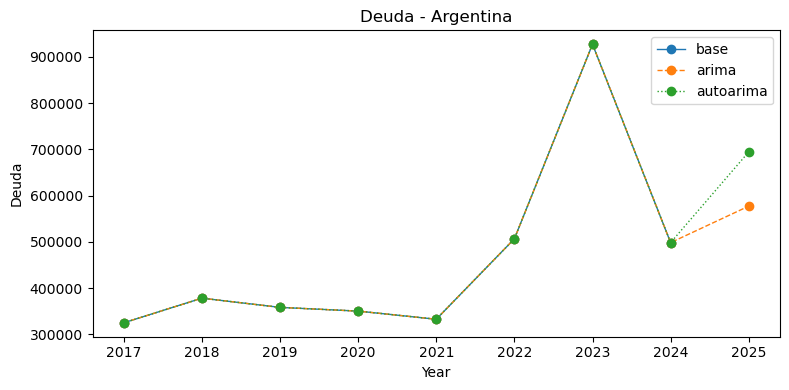

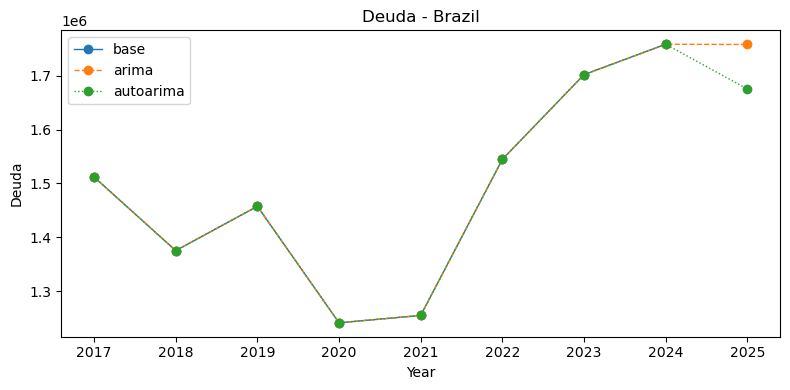

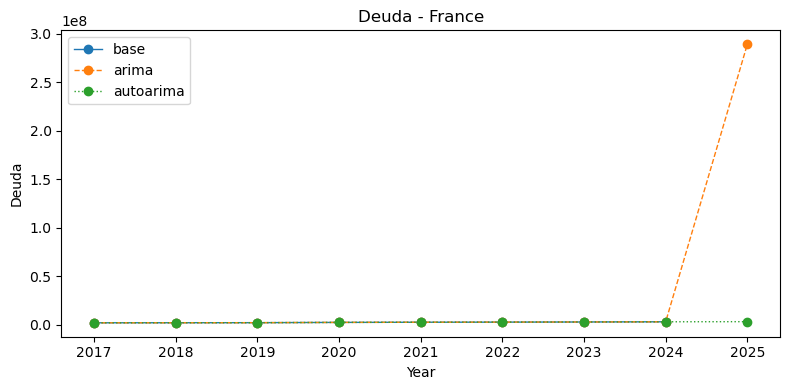

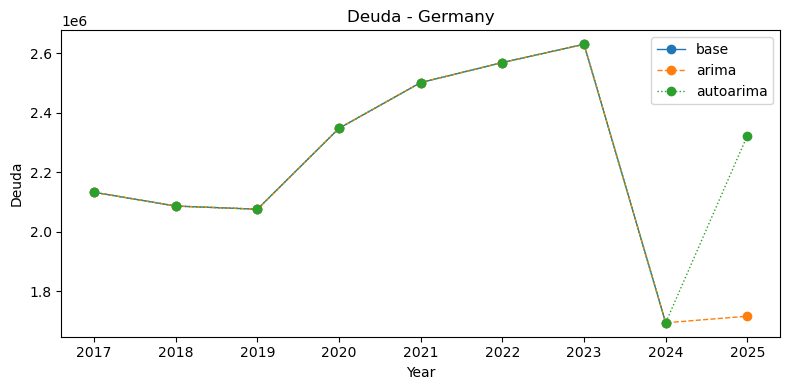

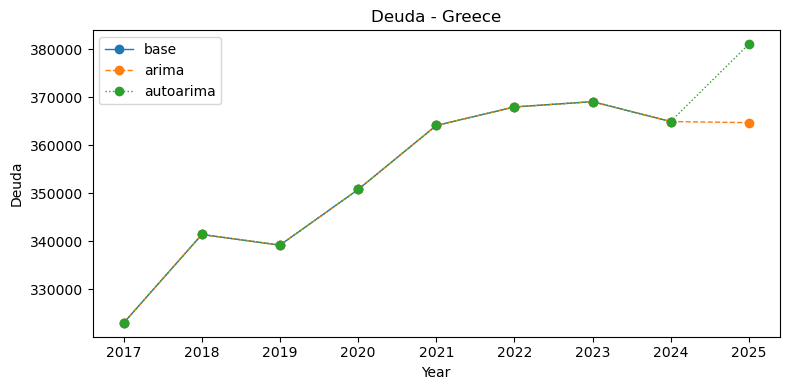

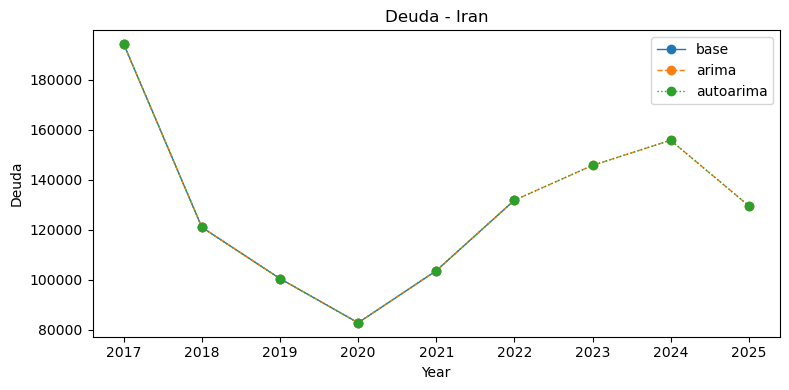

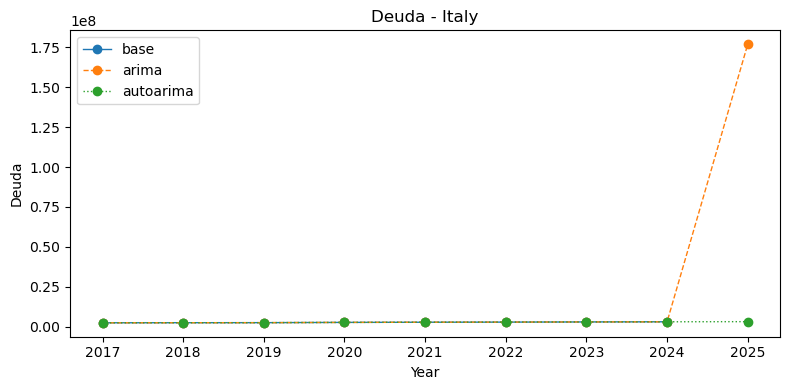

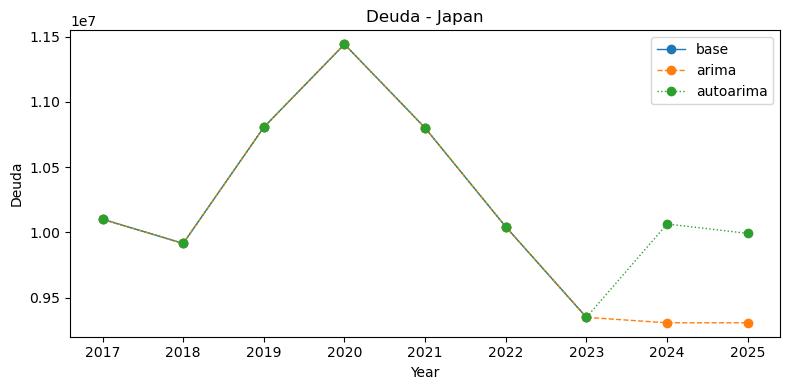

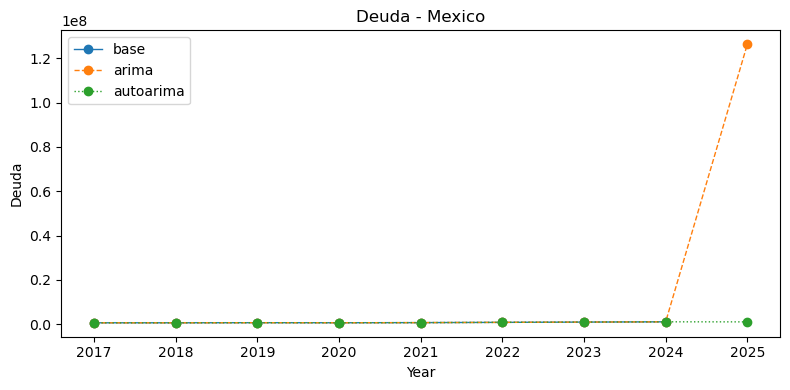

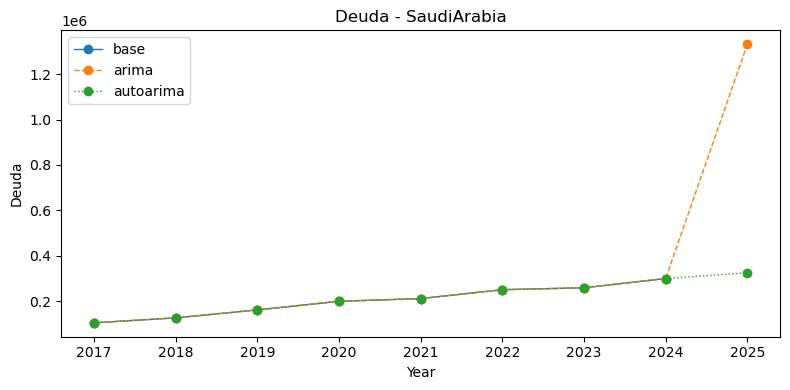

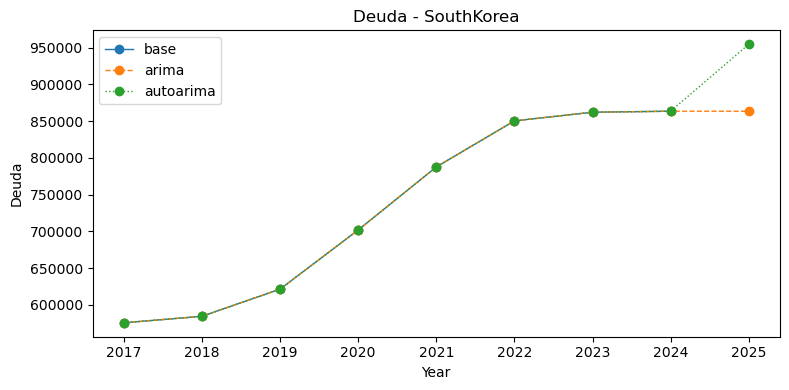

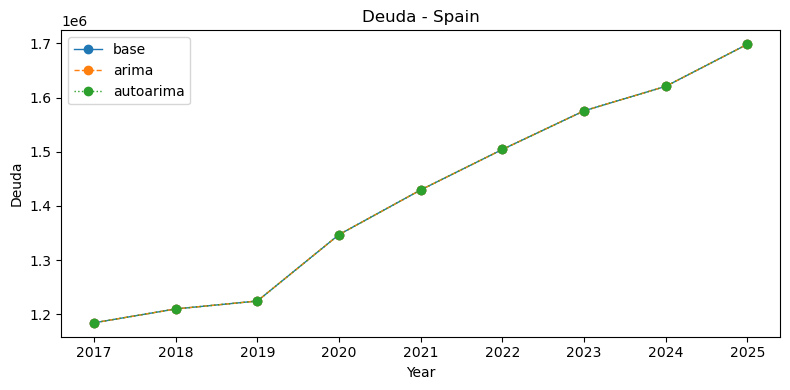

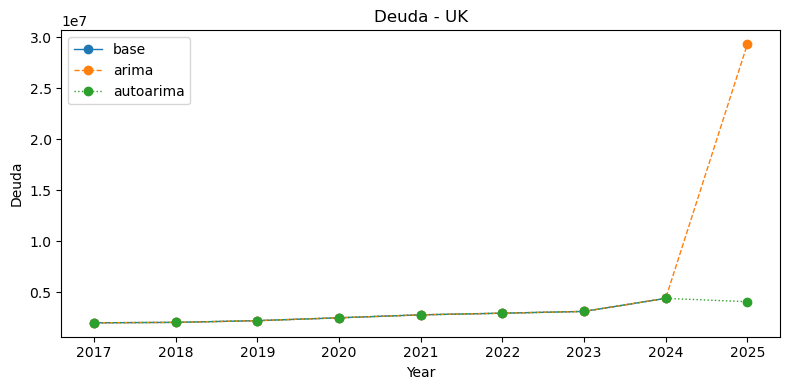

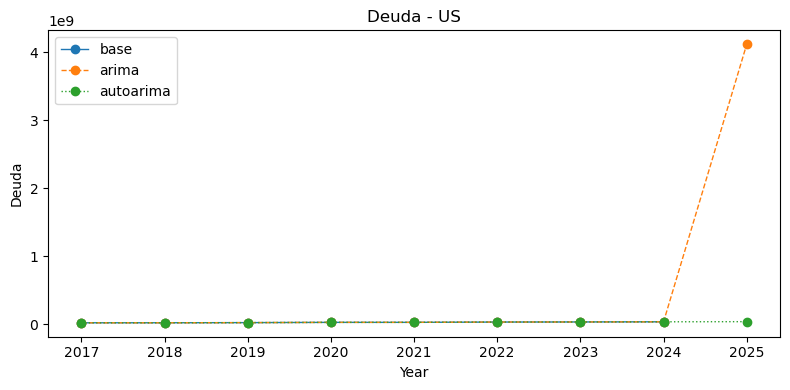

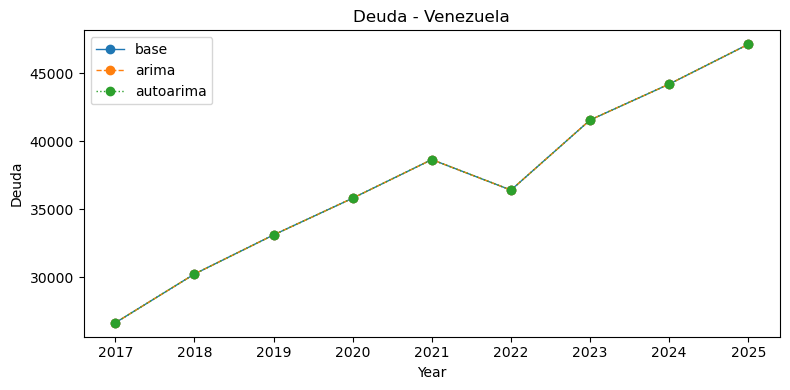

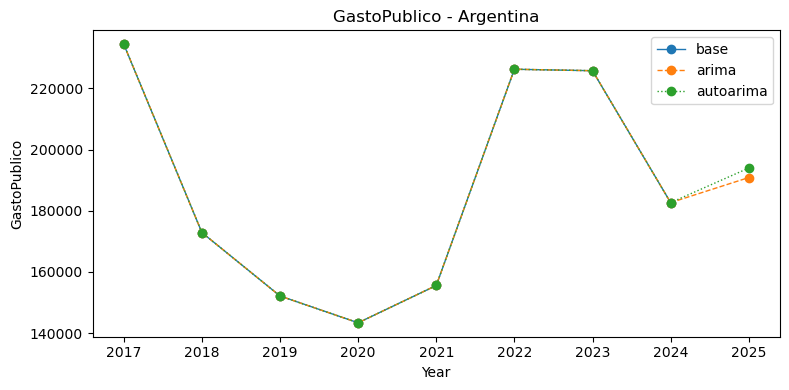

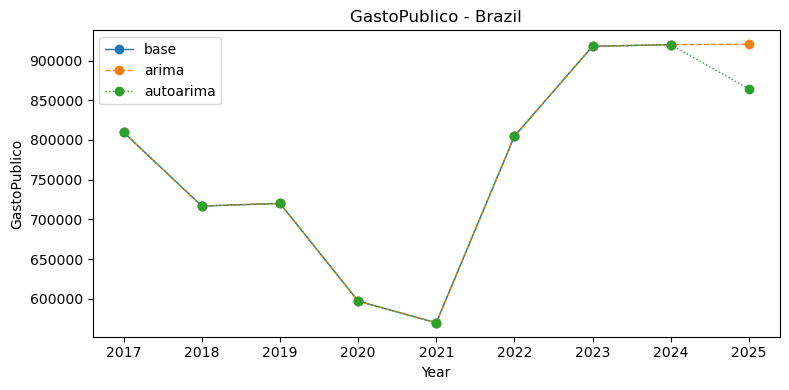

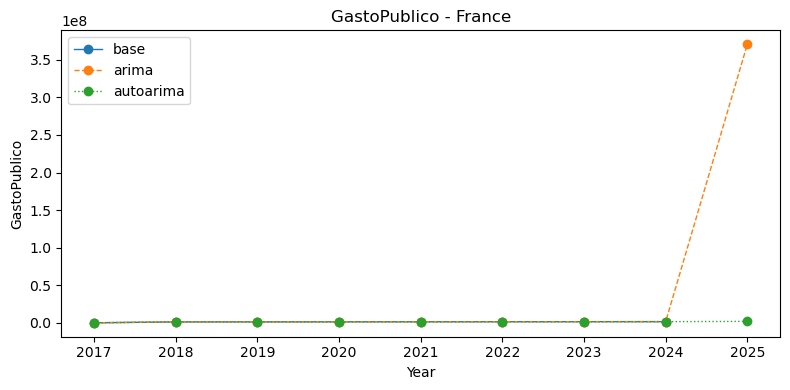

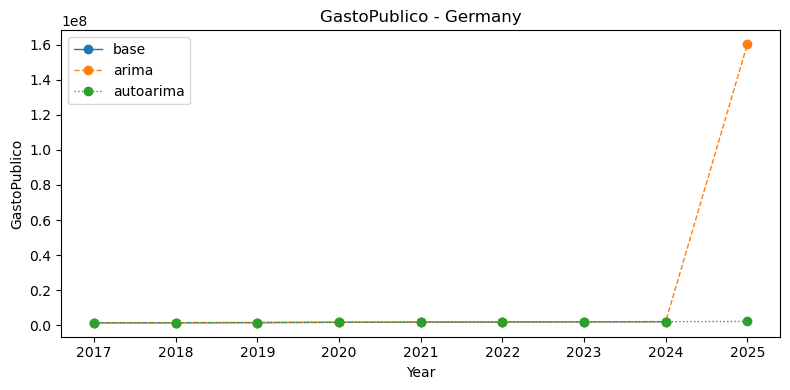

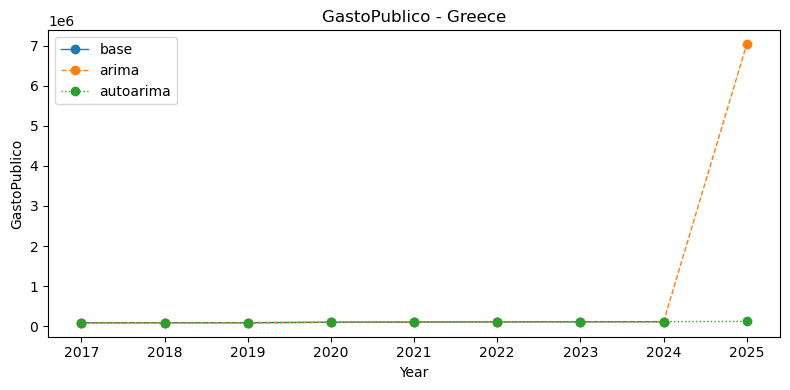

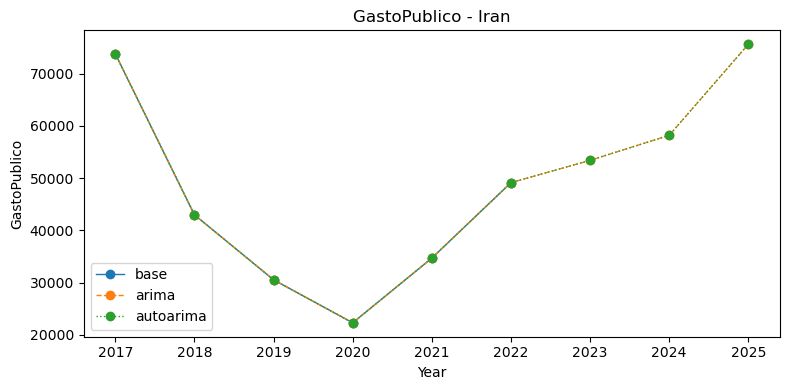

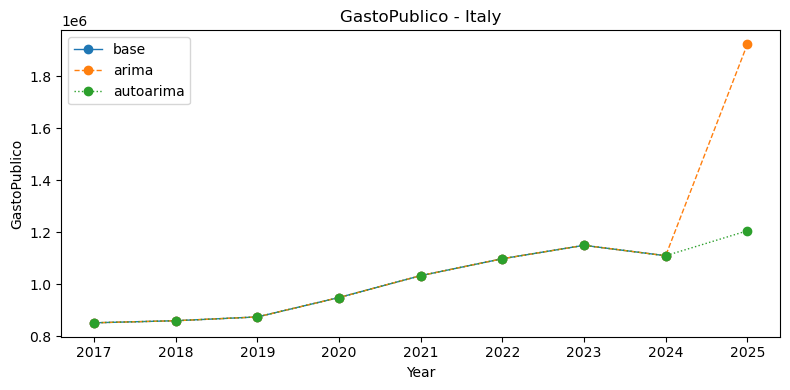

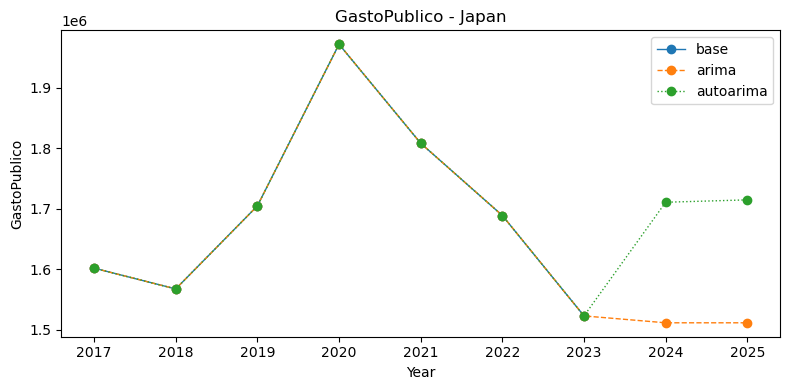

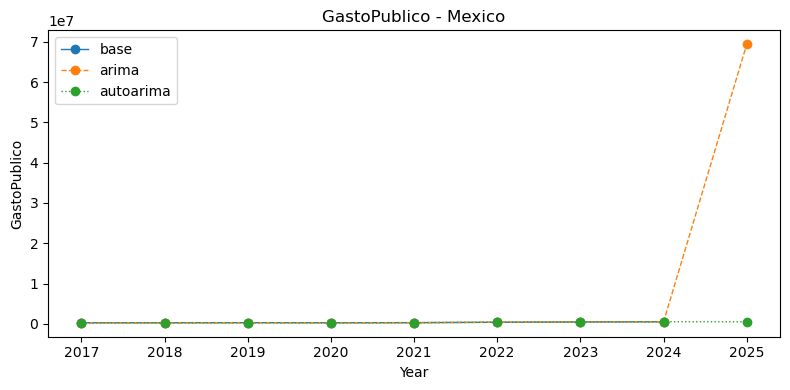

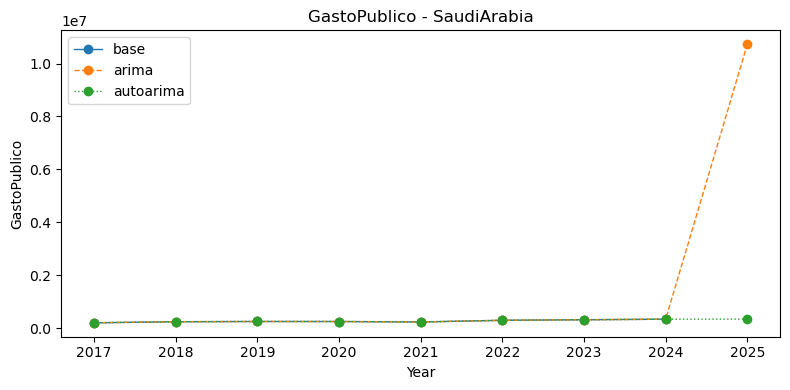

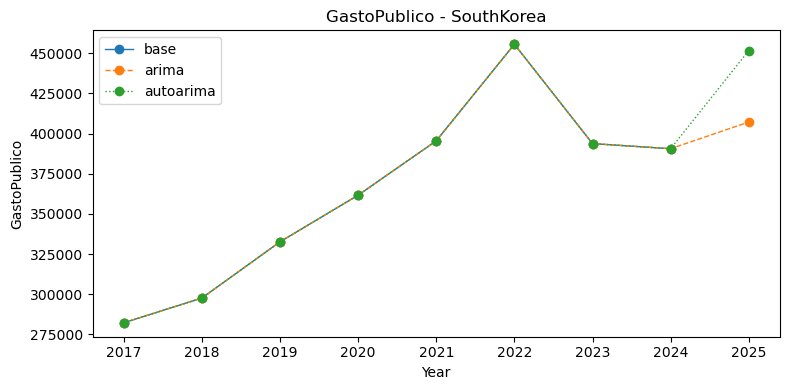

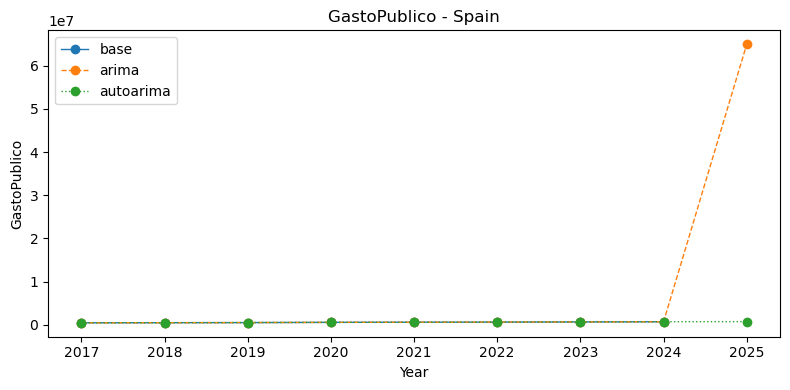

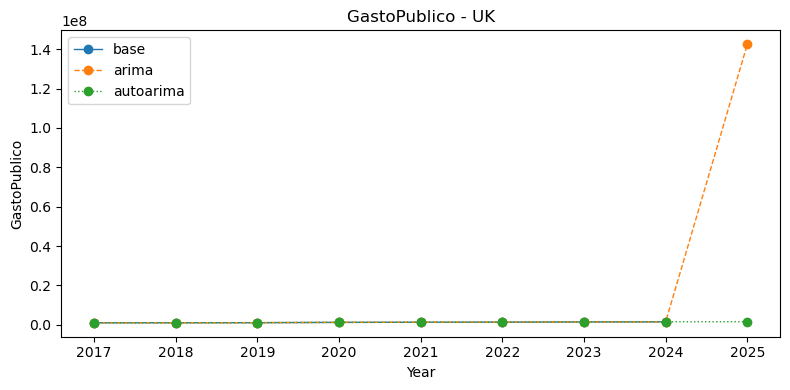

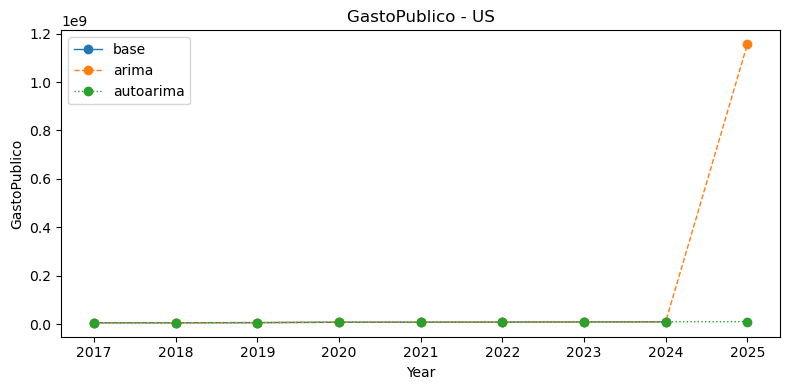

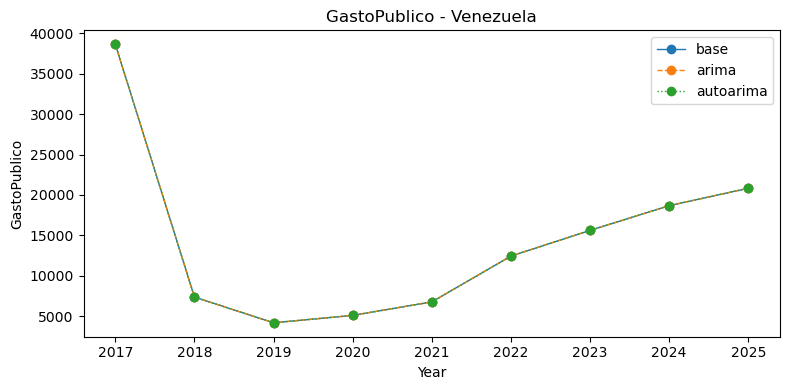

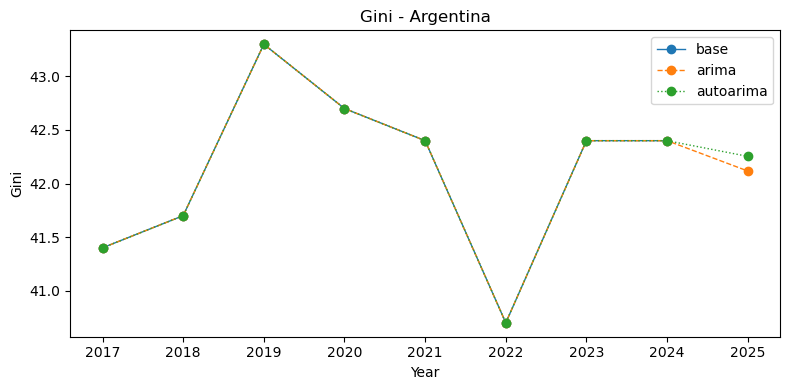

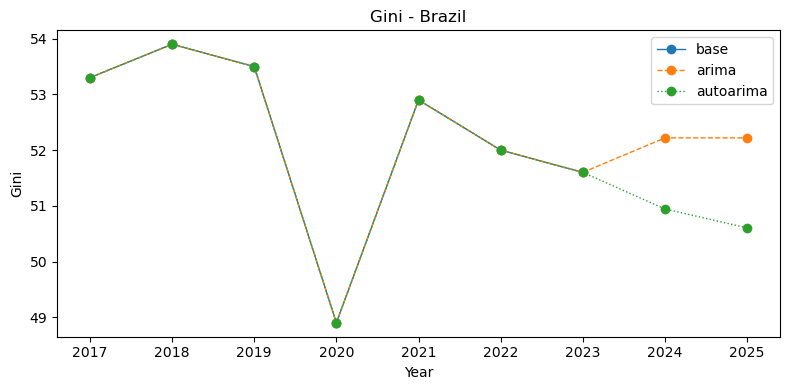

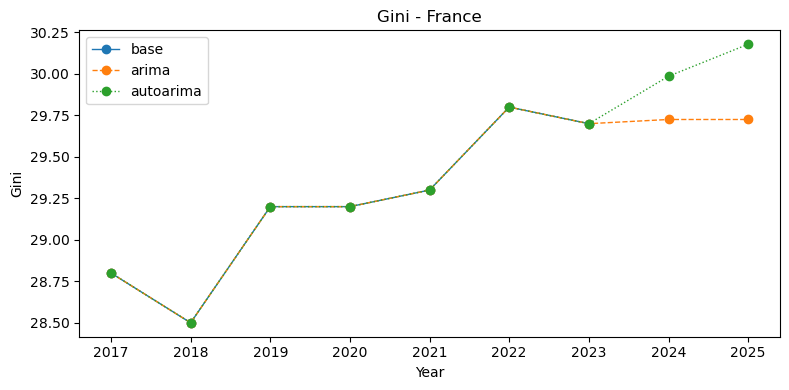

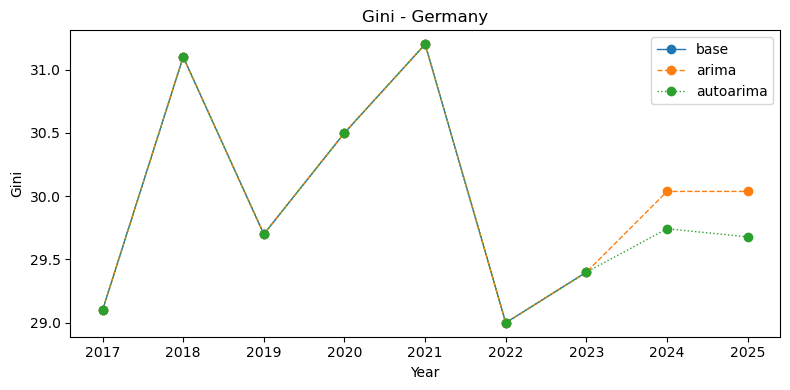

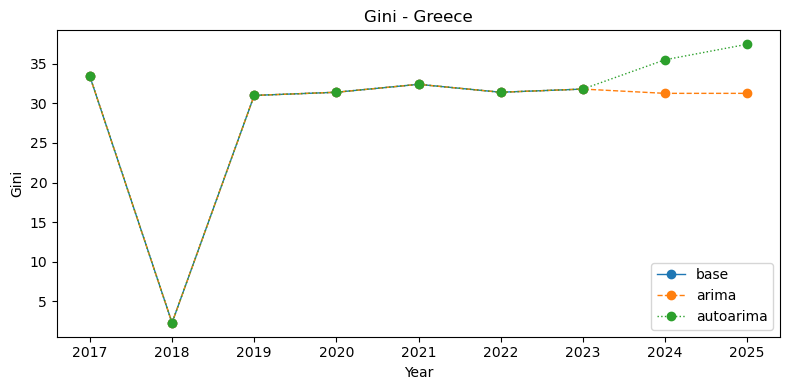

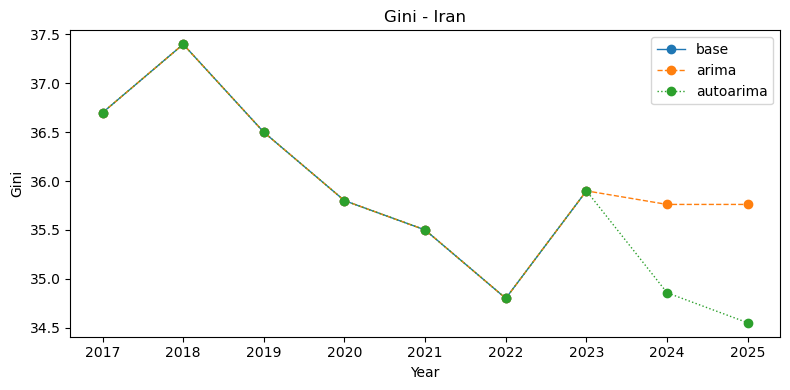

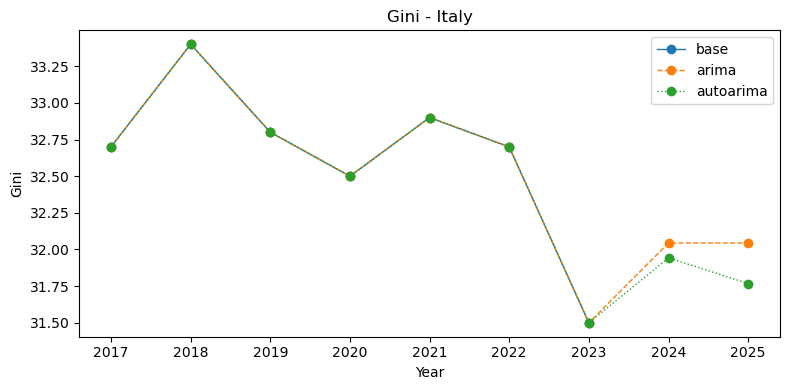

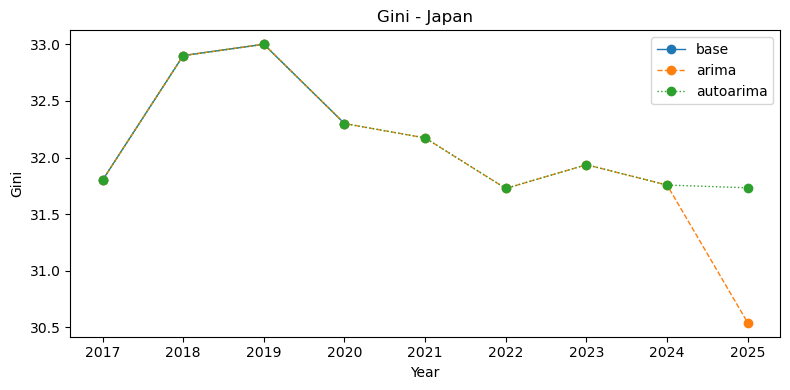

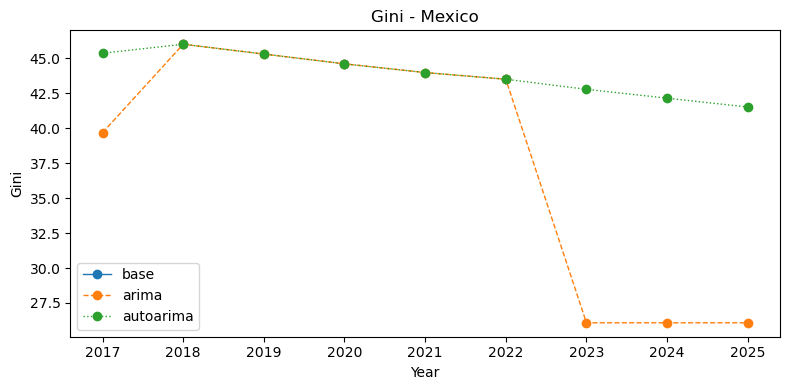

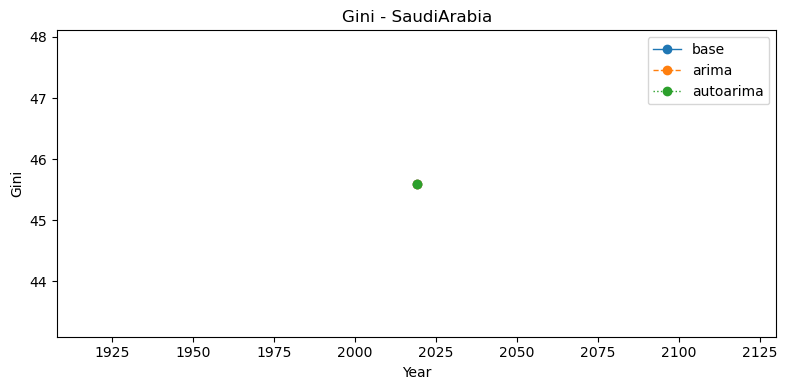

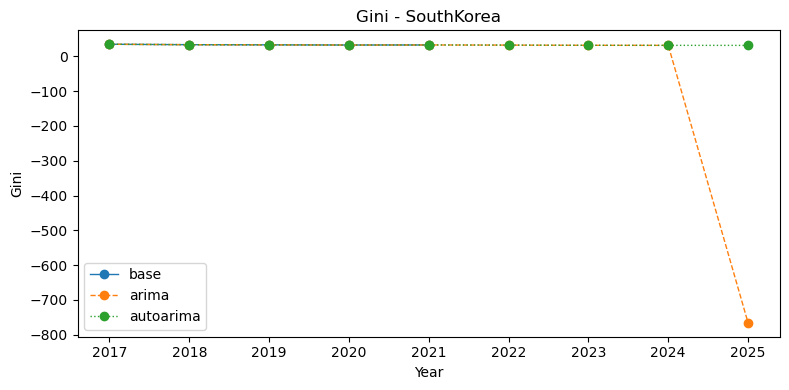

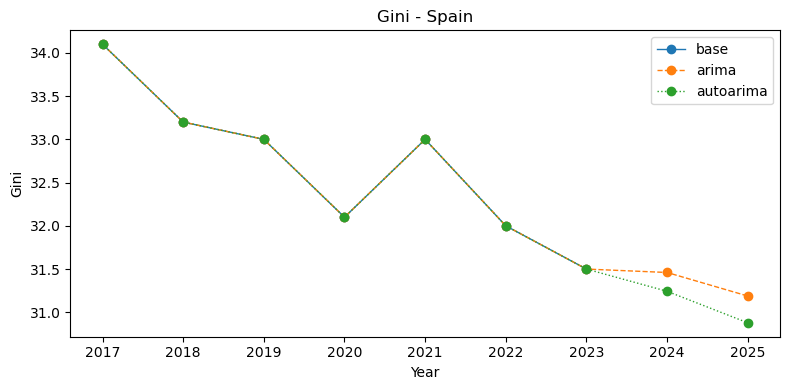

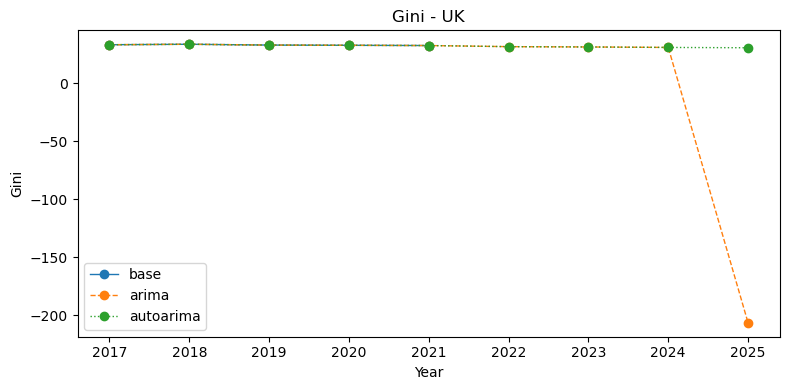

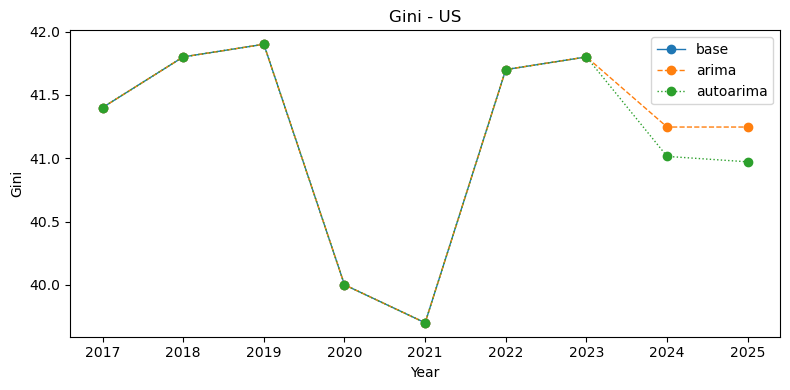

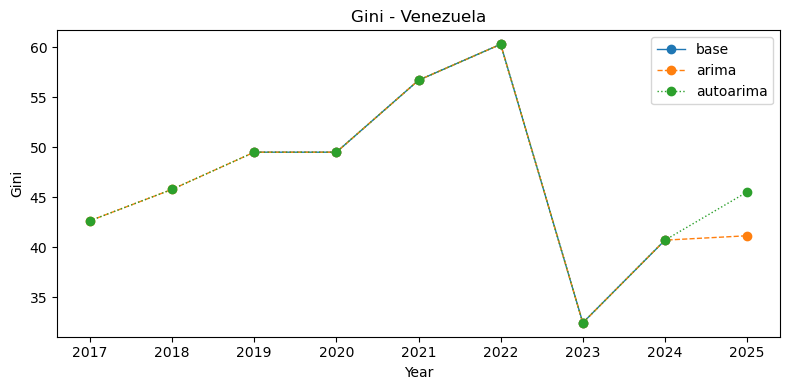

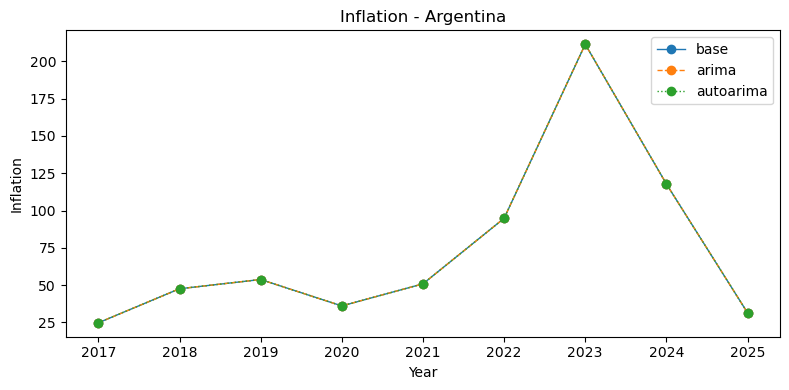

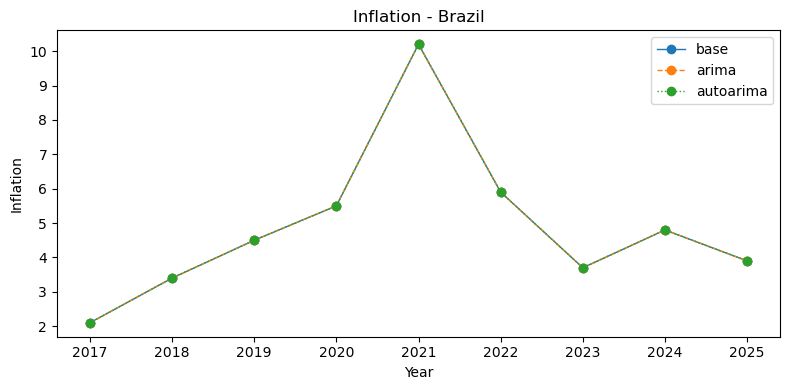

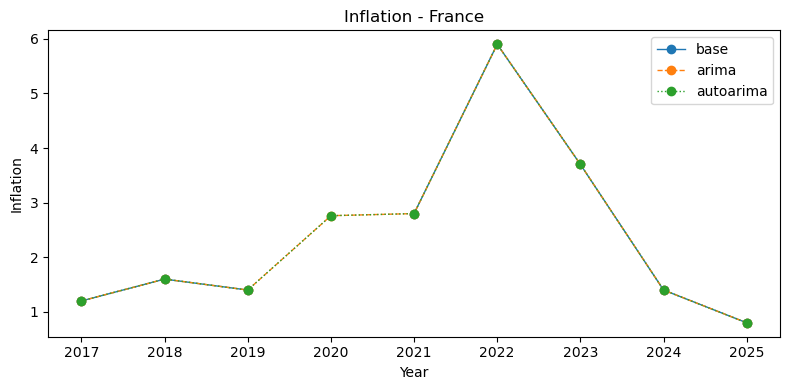

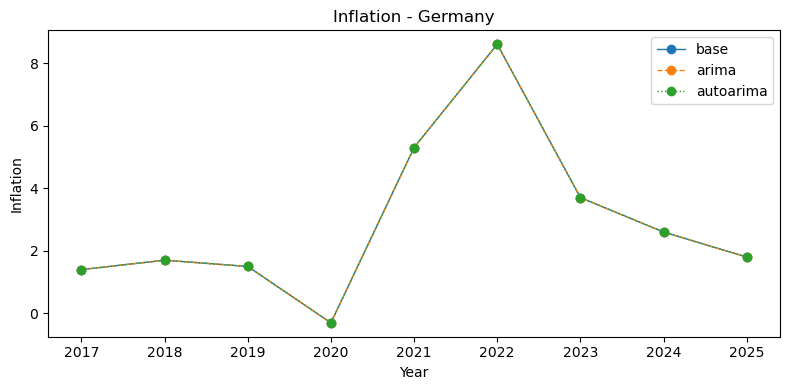

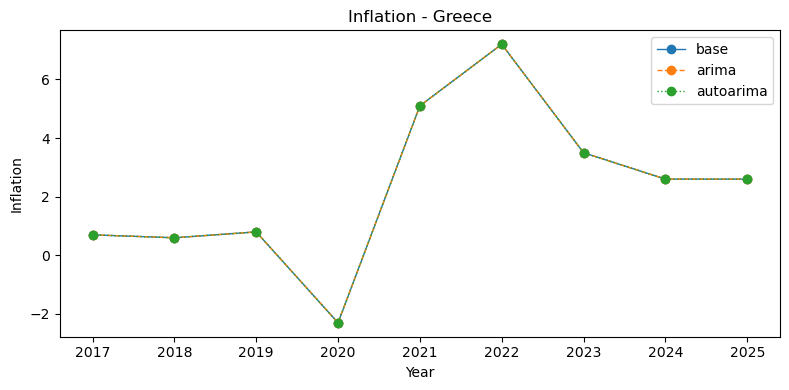

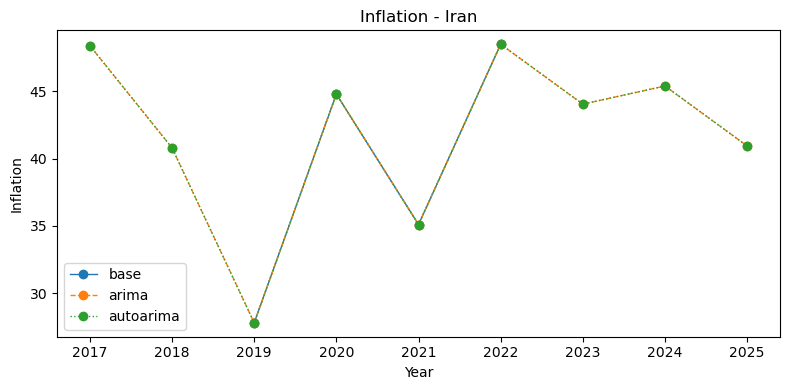

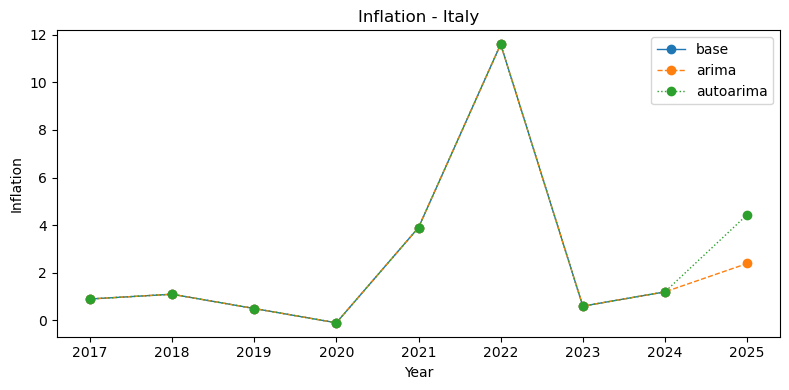

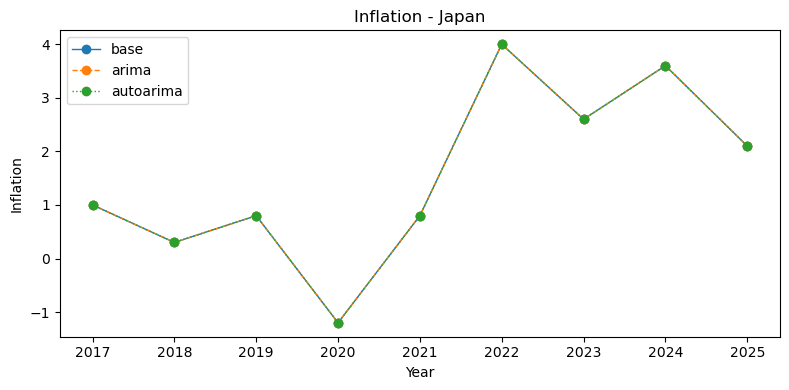

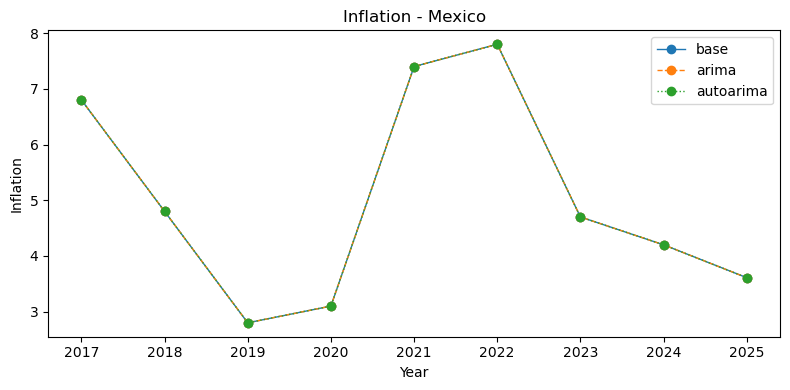

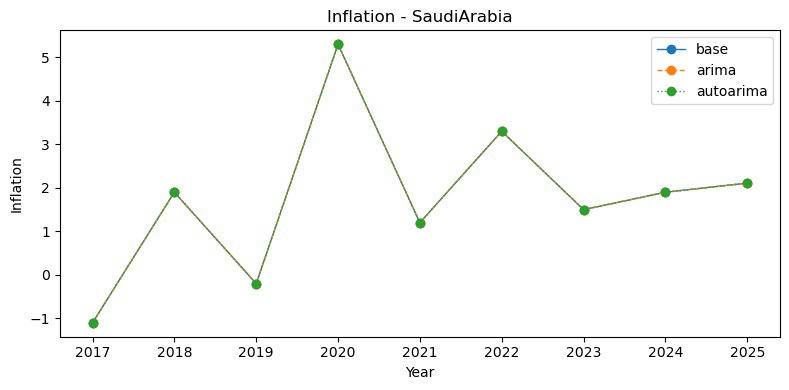

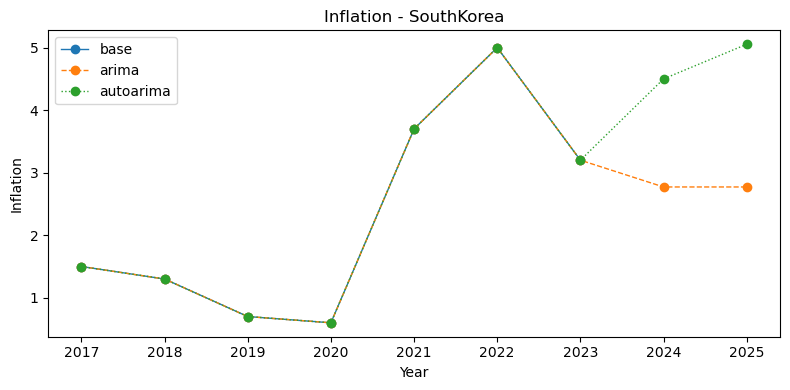

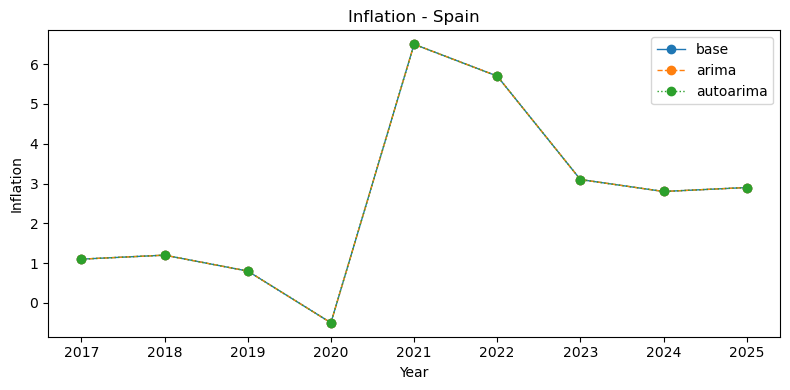

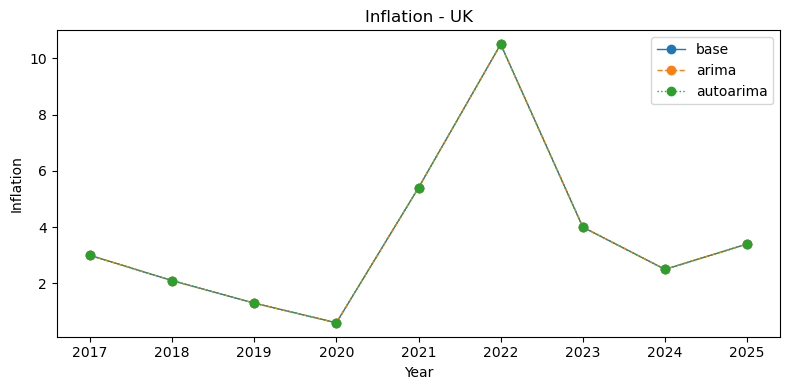

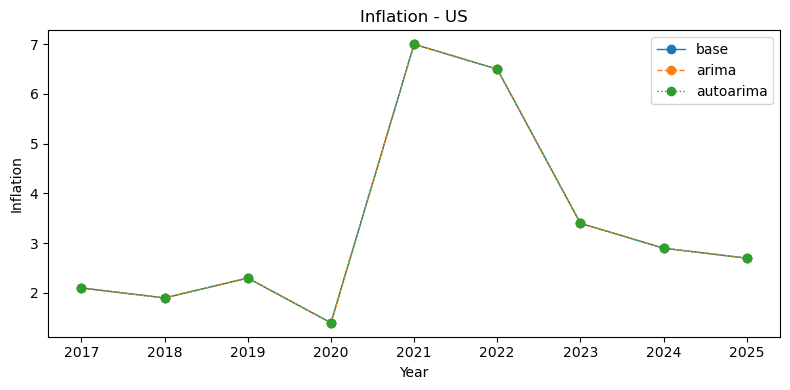

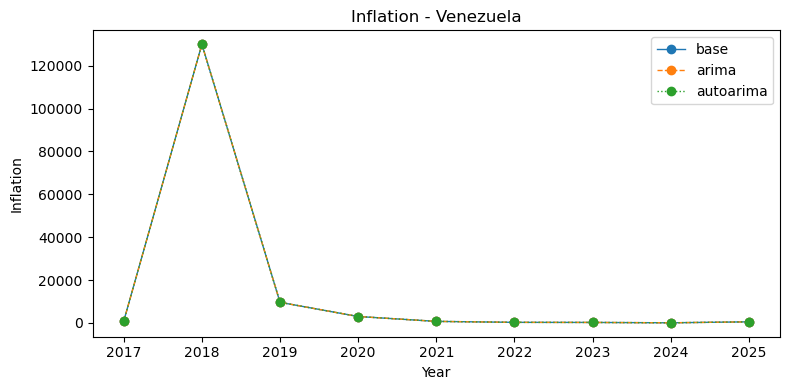

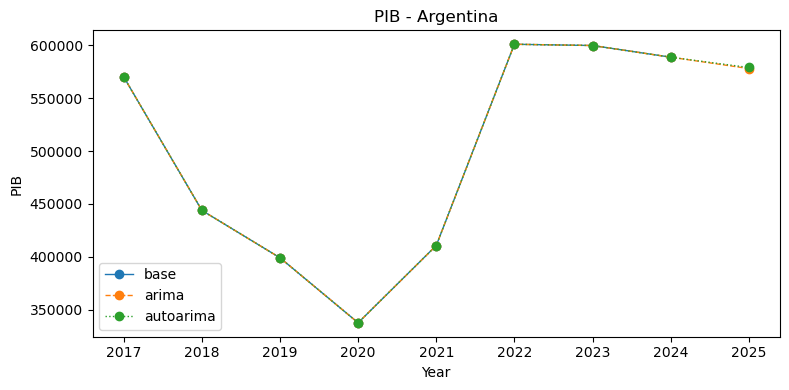

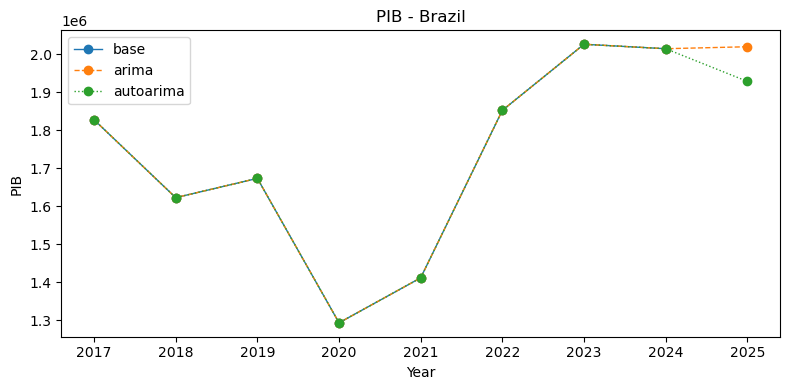

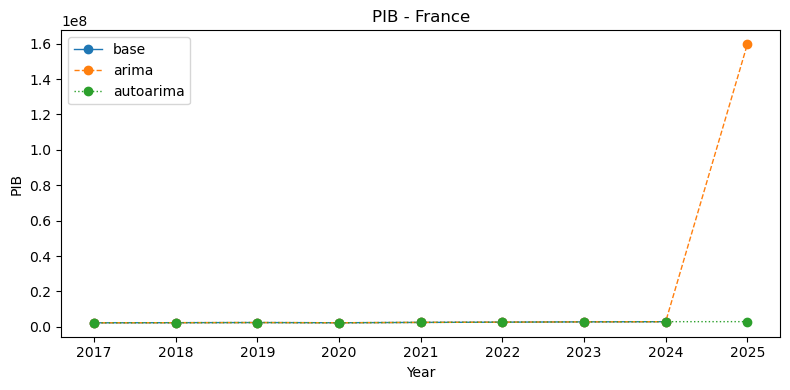

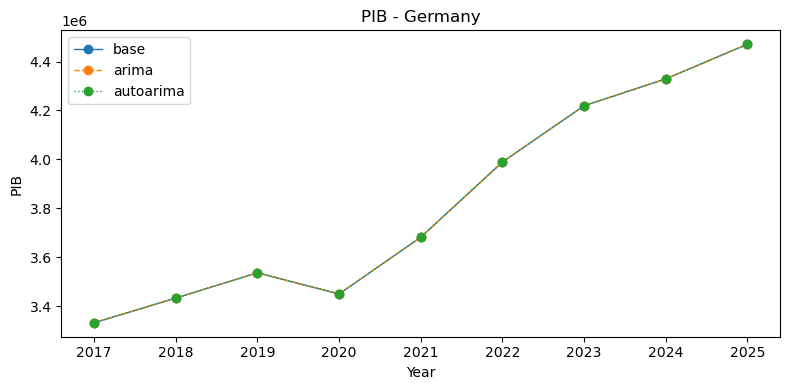

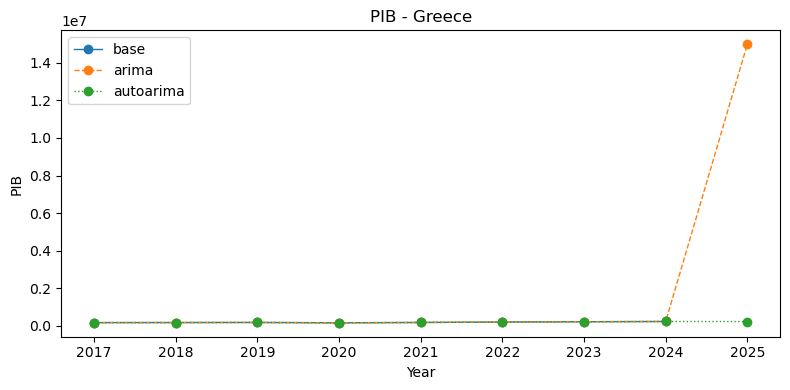

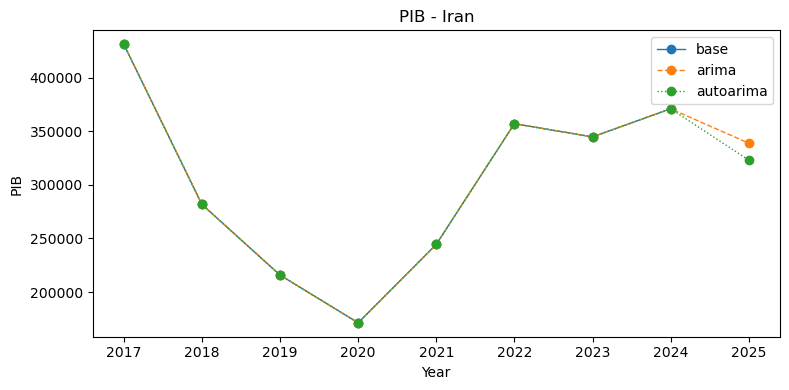

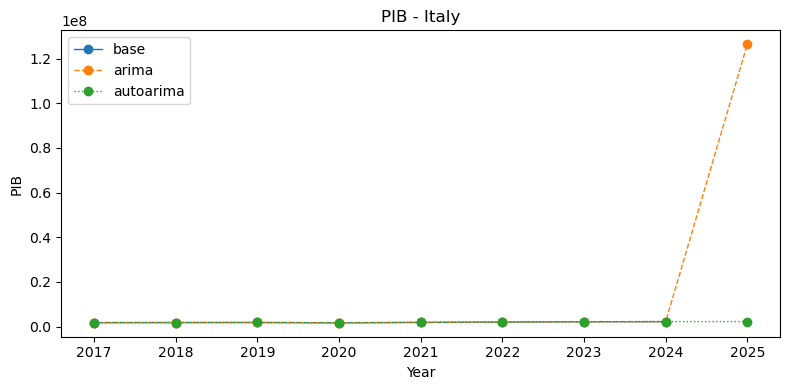

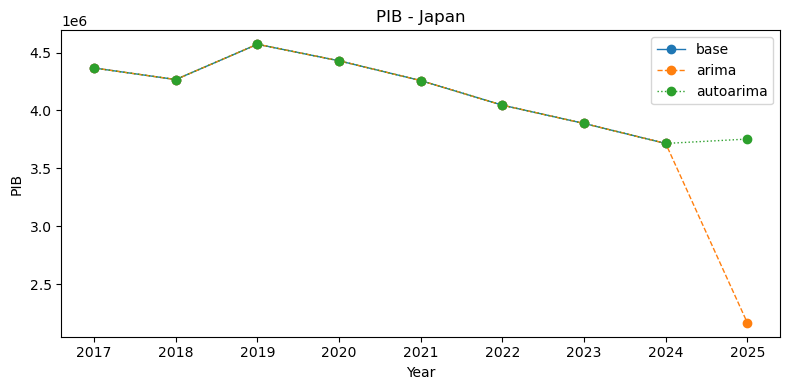

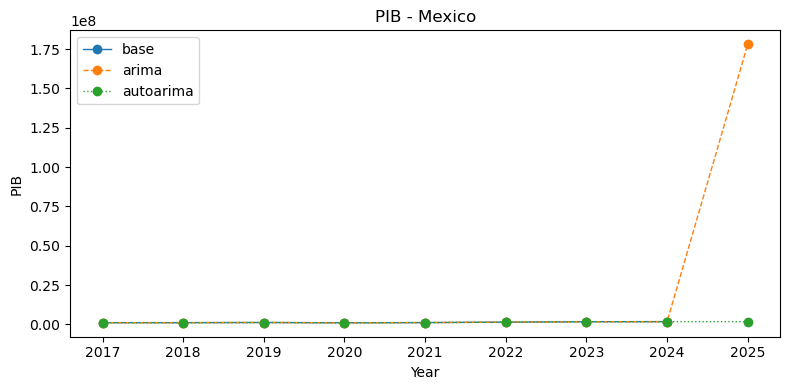

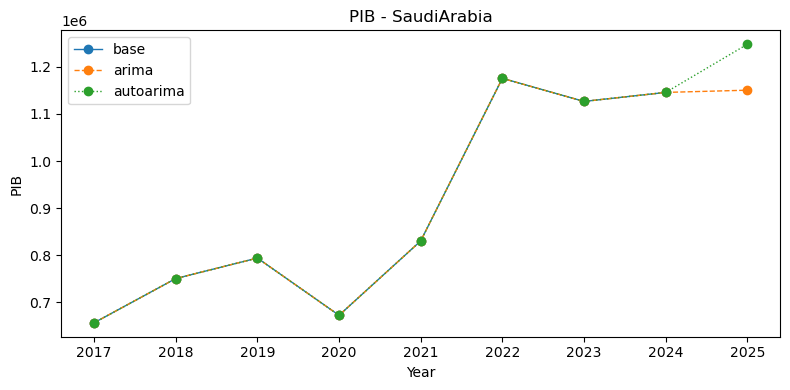

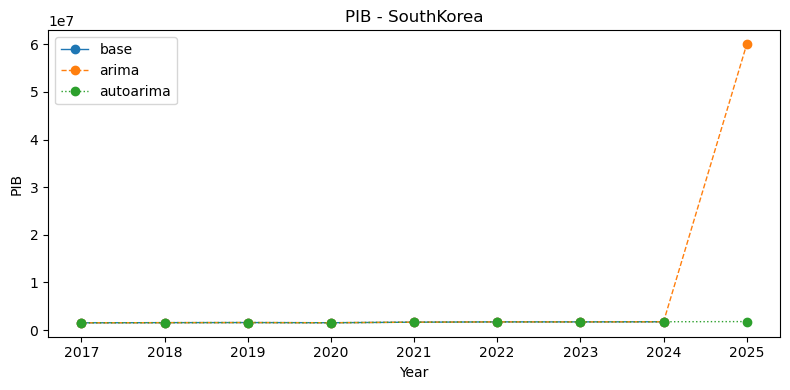

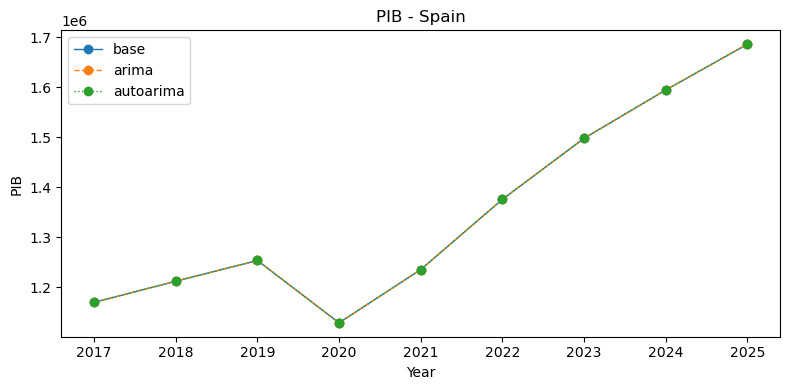

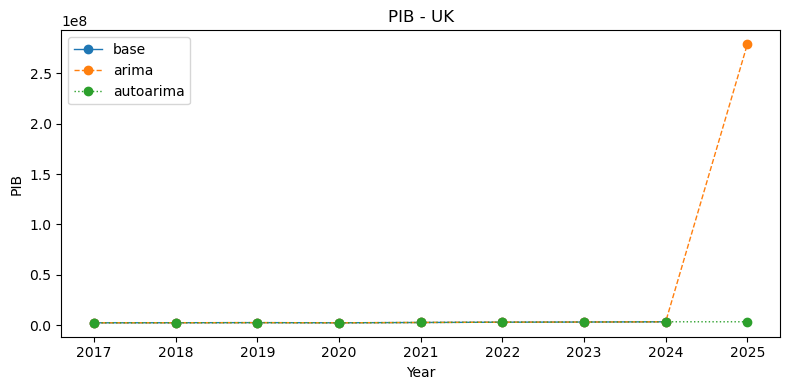

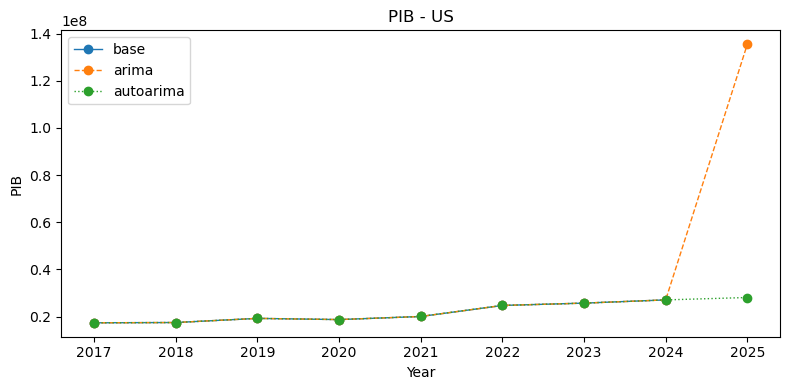

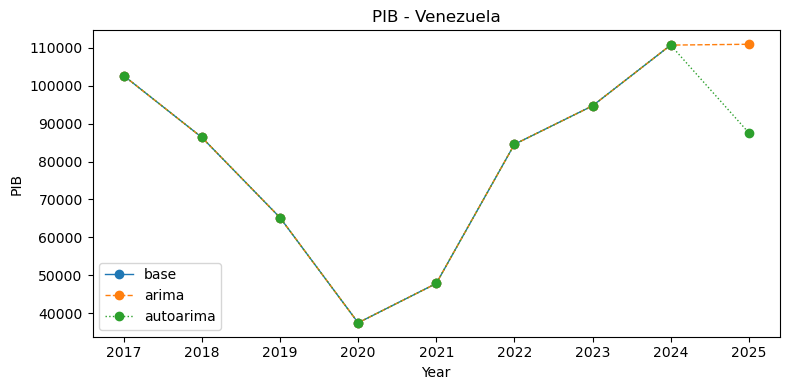

In [18]:
# Arima vs autoarima por columna y pais (base + modelos)
cols_arima = get_model_columns(imputation_plan, {"arima"})
cols_auto = get_model_columns(imputation_plan2, {"autoarima"})
cols_compare = sorted(set(cols_arima + cols_auto))

for col in cols_compare:
    for country in df["Country"].unique():
        b = df[df["Country"] == country].sort_values("Year")
        a = df_arima[df_arima["Country"] == country].sort_values("Year")
        u = df_auto[df_auto["Country"] == country].sort_values("Year")
        if b.empty and a.empty and u.empty:
            continue
        plt.figure(figsize=(8, 4))
        plt.plot(b["Year"], b[col], marker="o", linewidth=1, label="base")
        plt.plot(a["Year"], a[col], marker="o", linewidth=1, linestyle="--", label="arima")
        plt.plot(u["Year"], u[col], marker="o", linewidth=1, linestyle=":", label="autoarima")
        plt.title(f"{col} - {country}")
        plt.xlabel("Year")
        plt.ylabel(col)
        plt.legend()
        plt.tight_layout()
        plt.show()

In [8]:
from sklearn.experimental import enable_iterative_imputer  # noqa: F401
from sklearn.impute import IterativeImputer

def normalize_year_ranges(years):
    if isinstance(years, tuple) and len(years) == 2:
        return [years]
    if isinstance(years, list):
        return [tuple(r) for r in years]
    raise ValueError("years debe ser (inicio, fin) o lista de rangos")

def apply_spline(series, years, order=3):
    s = series.copy()
    for start, end in normalize_year_ranges(years):
        mask = s.index.to_series().between(start, end) & s.isna()
        if mask.sum() == 0:
            continue
        # Requiere suficientes puntos validos para spline/polinomio
        valid_count = s.notna().sum()
        if valid_count <= order:
            s_interp = s.interpolate(method="linear", limit_direction="both")
            s.loc[mask] = s_interp.loc[mask]
            continue
        try:
            s_interp = s.interpolate(method="spline", order=order, limit_direction="both")
        except Exception:
            # Fallback sin SciPy
            try:
                s_interp = s.interpolate(method="polynomial", order=order, limit_direction="both")
            except Exception:
                s_interp = s.interpolate(method="linear", limit_direction="both")
        s.loc[mask] = s_interp.loc[mask]
    return s

def apply_arima(series, years, order=(1, 1, 1)):
    from statsmodels.tsa.arima.model import ARIMA
    s = series.copy()
    train = s.dropna()
    if len(train) < 5:
        return s
    model = ARIMA(train, order=order)
    fit = model.fit()
    for start, end in normalize_year_ranges(years):
        mask = s.index.to_series().between(start, end) & s.isna()
        if mask.sum() == 0:
            continue
        pred = fit.predict(start=start, end=end)
        pred = pred.reindex(s.index)
        s.loc[mask] = pred.loc[mask]
    return s

def apply_auto_arima(
    series,
    years,
    seasonal=False,
    max_p=3,
    max_q=3,
    max_d=2,
    information_criterion="aic",
    stepwise=True,
    suppress_warnings=True,
    error_action="ignore",
    random_state=0,
    n_jobs=1,
    ):
    try:
        from pmdarima import auto_arima
    except ImportError as exc:
        raise ImportError("Instala pmdarima: pip install pmdarima") from exc
    s = series.copy()
    train = s.dropna()
    if len(train) < 5:
        return s
    model = auto_arima(
        train,
        seasonal=seasonal,
        max_p=max_p,
        max_q=max_q,
        max_d=max_d,
        information_criterion=information_criterion,
        stepwise=stepwise,
        suppress_warnings=suppress_warnings,
        error_action=error_action,
        random_state=random_state,
        n_jobs=n_jobs,
    )
    last_train_year = int(train.index.max())
    try:
        in_sample = pd.Series(model.predict_in_sample(), index=train.index)
    except Exception:
        in_sample = pd.Series(dtype=float)
    for start, end in normalize_year_ranges(years):
        mask = s.index.to_series().between(start, end) & s.isna()
        if mask.sum() == 0:
            continue
        if end <= last_train_year and not in_sample.empty:
            s.loc[mask] = in_sample.reindex(s.index).loc[mask]
            continue
        if start <= last_train_year and not in_sample.empty:
            in_mask = s.index.to_series().between(start, last_train_year) & s.isna()
            s.loc[in_mask] = in_sample.reindex(s.index).loc[in_mask]
        if end > last_train_year:
            n_periods = end - last_train_year
            if n_periods <= 0:
                continue
            forecast = model.predict(n_periods=n_periods)
            forecast_index = np.arange(last_train_year + 1, last_train_year + n_periods + 1)
            pred = pd.Series(forecast, index=forecast_index).reindex(s.index)
            pred_mask = pred.loc[mask]
            if pred_mask.isna().all() or pred_mask.nunique(dropna=True) <= 1:
                # Si el pronostico es plano o NaN, usa tendencia lineal
                years_idx = train.index.to_numpy()
                y = train.to_numpy()
                if len(y) >= 2:
                    coef = np.polyfit(years_idx, y, 1)
                    trend_vals = np.polyval(coef, s.index.to_numpy())
                    pred = pd.Series(trend_vals, index=s.index)
                else:
                    pred = s.interpolate(method="linear", limit_direction="both")
            s.loc[mask] = pred.loc[mask]
    return s

def apply_mice(country_df, target_col, years, predictors):
    cols = predictors + [target_col]
    work = country_df[cols].copy()
    imputer = IterativeImputer(random_state=0, max_iter=50)
    imputed = imputer.fit_transform(work)
    imputed_df = pd.DataFrame(imputed, columns=cols, index=country_df.index)
    mask = pd.Series(False, index=country_df.index)
    for start, end in normalize_year_ranges(years):
        mask |= country_df["Year"].between(start, end) & country_df[target_col].isna()
    country_df.loc[mask, target_col] = imputed_df.loc[mask, target_col]
    return country_df

def apply_plan(df_in, plan, mice_predictors):
    df_out = df_in.copy()
    cols_out = df_out.columns.tolist()
    for country in df_out["Country"].unique():
        cdf = df_out.loc[df_out["Country"] == country].copy()
        cdf = cdf.assign(_orig_idx=cdf.index)
        cdf = cdf.sort_values("Year")
        cdf_ts = cdf.set_index("Year")
        for item in plan:
            col = item["column"]
            model = item["model"].lower()
            years = item["years"]
            countries = item.get("countries")
            if countries and country not in countries:
                continue
            if model == "spline":
                cdf_ts[col] = apply_spline(cdf_ts[col], years, order=item.get("order", 3))
            elif model == "arima":
                cdf_ts[col] = apply_arima(cdf_ts[col], years, order=item.get("arima_order", (1, 1, 1)))
            elif model == "autoarima":
                cdf_ts[col] = apply_auto_arima(
                    cdf_ts[col],
                    years,
                    **item.get("autoarima_params", {}),
                )
            elif model == "mice":
                cdf_reset = cdf_ts.reset_index()
                cdf_reset = apply_mice(cdf_reset, col, years, mice_predictors)
                cdf_ts = cdf_reset.set_index("Year")
            else:
                raise ValueError(f"Modelo no soportado: {model}")
        cdf_final = cdf_ts.reset_index()
        cdf_final = cdf_final.set_index(cdf_final["_orig_idx"]).drop(columns=["_orig_idx"])
        df_out.loc[cdf_final.index, cols_out] = cdf_final[cols_out]
    return df_out

In [25]:
# Ejecuta la imputacion y guarda un nuevo archivo
df_imputed = apply_plan(df, imputation_plan3, mice_predictors)

out_path = csv_path.with_name(csv_path.stem + "_imputado.csv")
df_imputed.to_csv(out_path, index=False)
out_path

c:\Users\ruben\.conda\envs\teg\lib\site-packages\statsmodels\tsa\base\tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(
c:\Users\ruben\.conda\envs\teg\lib\site-packages\statsmodels\tsa\base\tsa_model.py:837: FutureWarning: No supported index is available. In the next version, calling this method in a model without a supported index will result in an exception.
  return get_prediction_index(
c:\Users\ruben\.conda\envs\teg\lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: An unsupported index was provided. As a result, forecasts cannot be generated. To use the model for forecasting, use one of the supported classes of index.
  self._init_dates(dates, freq)
c:\Users\ruben\.conda\envs\teg\lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: An unsupported index was provided. As a result, forecasts cannot be generated. To use the m

WindowsPath('C:/Users/ruben/Desktop/TEG/MacroEconomy2_imputado.csv')